In [1]:
import numpyro
numpyro.set_host_device_count(4)

import jax
import jax.numpy as jnp
import numpy as np
import sncosmo
from bayesn import SEDmodel
from pathlib import Path
import pandas as pd

from io import BytesIO
import gzip
from astropy.io import fits
from zipfile import ZipFile, BadZipFile

import numpy as np
import matplotlib.pyplot as plt
import sncosmo
from bayesn import SEDmodel

/Users/jennakempster-taylor/miniforge3/envs/bayesn-lsst/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


In [2]:
from zipfile import ZipFile

with ZipFile("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/data/LSST_SHORT.zip", "r") as archive:
    names = archive.namelist()
    print(len(names), "files")
    for n in names[:30]:
        print(n)

5 files
./
LSST/
LSST/LSST.LIST
LSST/LSST_CHUNK01_SPLIT002_HEAD.FITS.gz
LSST/LSST_CHUNK01_SPLIT002_PHOT.FITS.gz


In [5]:
lsst_zip = Path("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/data/LSST_SHORT.zip")

head_name = "LSST/LSST_CHUNK01_SPLIT002_HEAD.FITS.gz"
phot_name = "LSST/LSST_CHUNK01_SPLIT002_PHOT.FITS.gz"

with ZipFile(lsst_zip, "r") as archive:
    head_bytes = gzip.decompress(archive.read(head_name))
    with fits.open(BytesIO(head_bytes), memmap=False) as hdul:
        head_data = hdul[1].data.copy()

    phot_bytes = gzip.decompress(archive.read(phot_name))
    with fits.open(BytesIO(phot_bytes), memmap=False) as hdul:
        phot_data = hdul[1].data.copy()

print("HEAD rows:", len(head_data))
print("PHOT rows:", len(phot_data))

HEAD rows: 3951
PHOT rows: 60825


In [34]:
import numpy as np
import pandas as pd
import jax.numpy as jnp
from bayesn import SEDmodel
import pickle
from pathlib import Path
    
# --- extract one object's lightcurve from PHOT table ---
def get_lightcurve(head_row, phot_table):
    start = int(head_row["PTROBS_MIN"]) - 1
    stop = int(head_row["PTROBS_MAX"])

    lc = pd.DataFrame(phot_table[start:stop])

    lc["BAND"] = (
        lc["BAND"].str.decode("utf-8").str.strip()
        if lc["BAND"].dtype == object
        else lc["BAND"].astype(str).str.strip()
    )
    return lc

LSST_FILT_MAP = {
    "u": "u_LSST",
    "g": "g_LSST",
    "r": "r_LSST",
    "i": "i_LSST",
    "z": "z_LSST",
    "y": "y_LSST",
}

zq_broad = jnp.linspace(0, 1, 101)

model = SEDmodel(load_model="T21_model")

output_dir = Path("fit_results")
output_dir.mkdir(exist_ok=True)

BATCH_SIZE = 10

n_objects = len(head_data)
n_batches = (n_objects + BATCH_SIZE - 1) // BATCH_SIZE

for batch_num in range(n_batches):
    out_path = output_dir / f"batch_{batch_num:04d}.pkl"

    if out_path.exists():
        print(f"Batch {batch_num + 1}/{n_batches} already done, skipping.")
        continue

    batch_start = batch_num * BATCH_SIZE
    batch_end = min(batch_start + BATCH_SIZE, n_objects)

    print(f"\n=== Batch {batch_num + 1}/{n_batches} (objects {batch_start}-{batch_end - 1}) ===")

    batch_results = {}
    

    for idx in range(batch_start, batch_end):
        head_row = head_data[idx]
        snid = str(head_row["SNID"]).strip()

        # --- extract + clean lightcurve ---
        lc = get_lightcurve(head_row, phot_data)

        float_cols = lc.select_dtypes(include="float").columns
        lc[float_cols] = lc[float_cols].astype("float32")
        lc["DETNUM"] = lc["DETNUM"].astype("int16")

        lc = lc[
            np.isfinite(lc["MJD"])
            & np.isfinite(lc["FLUXCAL"])
            & np.isfinite(lc["FLUXCALERR"])
            & (lc["FLUXCALERR"] > 0)
        ].copy()

        lc["BAND"] = (
            lc["BAND"].astype(str).str.strip().str.replace("LSST_", "", regex=False)
        )
        lc = lc.sort_values("MJD").reset_index(drop=True)

        peak_mjd = float(head_row["PEAKMJD"])
        lc = lc[lc["MJD"].between(peak_mjd - 20, peak_mjd + 200)].copy()

        if len(lc) < 5:
            print(f"  Skipping {snid}: too few points ({len(lc)})")
            continue

        t = np.asarray(lc["MJD"], dtype=float)
        flux = np.asarray(lc["FLUXCAL"], dtype=float)
        flux_err = np.asarray(lc["FLUXCALERR"], dtype=float)
        filters = np.asarray(lc["BAND"], dtype=str)

        print(f"  Fitting {snid} ({len(lc)} obs)...")

        try:
            samples, props = model.fit(
                t,
                flux,
                np.clip(flux_err, flux / 10, np.inf),
                filters,
                ebv_mw=float(head_row["MWEBV"]),
                peak_mjd=peak_mjd,
                filt_map=LSST_FILT_MAP,
                photoz=True,
                z_quantiles=zq_broad,
                chain_method="parallel",
            )
            # Convert to plain numpy so nothing keeps a live JAX/device reference
            batch_results[snid] = {
                "samples": {k: np.asarray(v) for k, v in samples.items()},
                "props": props,
            }
        except Exception as e:
            print(f"    Fit failed for {snid}: {e}")

    # --- save this batch to disk, then drop it from memory ---
    out_path = output_dir / f"batch_{batch_num:04d}.pkl"
    with open(out_path, "wb") as f:
        pickle.dump(batch_results, f)

    print(f"Saved {len(batch_results)} fits to {out_path}")

    del batch_results  # free memory before next batch

print("\nAll batches complete.")

Current devices: [CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3)]
Currently working in /Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks
Loading built-in model T21_model
Batch 1/396 already done, skipping.
Batch 2/396 already done, skipping.
Batch 3/396 already done, skipping.
Batch 4/396 already done, skipping.
Batch 5/396 already done, skipping.
Batch 6/396 already done, skipping.
Batch 7/396 already done, skipping.
Batch 8/396 already done, skipping.

=== Batch 9/396 (objects 80-89) ===
  Fitting 00f99dc3-8cf0-4d04-b97e-6a49271f74f9 (11 obs)...


/Users/jennakempster-taylor/miniforge3/envs/bayesn-lsst/lib/python3.11/site-packages/jax/_src/api_util.py:691: UserWarning: Missing a plate statement for batch dimension -2 at site 'obs'. You can use `numpyro.util.format_shapes` utility to check shapes at all sites of your model.
  ans = _fun(*args, **kwargs)


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

...

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [13]:
import matplotlib.pyplot as plt

colours = {
    "u": "blue",
    "g": "green",
    "r": "red",
    "i": "orange",
    "z": "purple",
    "y": "brown",
}

def set_band_state(model, observed_bands, filt_map):
    band_indices = np.array([
        model.band_dict[filt_map[band]] for band in observed_bands
    ])
    model.used_band_inds = np.unique(band_indices)
    model.zps = model.all_zps[model.used_band_inds]
    model.offsets = model.all_offsets[model.used_band_inds]

def plot_fit(snid, samples):
    # --- re-extract the same lightcurve used for fitting ---
    idx = np.flatnonzero(
        np.char.strip(head_data["SNID"].astype(str)) == snid
    )[0]
    head_row = head_data[idx]

    lc = get_lightcurve(head_row, phot_data)

    float_cols = lc.select_dtypes(include="float").columns
    lc[float_cols] = lc[float_cols].astype("float32")
    lc["DETNUM"] = lc["DETNUM"].astype("int16")

    lc = lc[
        np.isfinite(lc["MJD"])
        & np.isfinite(lc["FLUXCAL"])
        & np.isfinite(lc["FLUXCALERR"])
        & (lc["FLUXCALERR"] > 0)
    ].copy()

    lc["BAND"] = (
        lc["BAND"].astype(str).str.strip().str.replace("LSST_", "", regex=False)
    )
    lc = lc.sort_values("MJD").reset_index(drop=True)

    peak_mjd = float(head_row["PEAKMJD"])
    lc = lc[lc["MJD"].between(peak_mjd - 20, peak_mjd + 200)].copy()

    t = np.asarray(lc["MJD"], dtype=float)
    flux = np.asarray(lc["FLUXCAL"], dtype=float)
    flux_err = np.asarray(lc["FLUXCALERR"], dtype=float)
    filters = np.asarray(lc["BAND"], dtype=str)

    observed_bands = [
        band for band in ["u", "g", "r", "i", "z", "y"]
        if band in np.unique(filters)
    ]

    # --- get model curves from the posterior samples (same as before) ---
    plot_samples = dict(samples)
    if "mu" not in plot_samples:
        plot_samples["mu"] = plot_samples["Ds"]
    if "delM" not in plot_samples:
        plot_samples["delM"] = np.zeros_like(plot_samples["Ds"])

    model.peak_mjds = np.array([peak_mjd])
    model.ebv = np.array([float(head_row["MWEBV"])])

    fit_bands = [[LSST_FILT_MAP[band] for band in observed_bands]]

    set_band_state(model, observed_bands, LSST_FILT_MAP)   # <-- new line

    model_mjd, model_mean, model_std = model.get_flux_from_chains_photoz(
        chains=plot_samples,
        bands=fit_bands,
        num_sne=1,
        n_grid=200,
        num_samples=200,
    )

    # --- plot, same style as before ---
    z_median = np.median(np.asarray(samples["z"]).reshape(-1))

    fig, ax = plt.subplots(figsize=(11, 7))

    for band_index, band in enumerate(observed_bands):
        use = filters == band
        colour = colours[band]

        ax.errorbar(
            t[use], flux[use], yerr=flux_err[use],
            fmt="o", ms=5, capsize=2, color=colour,
            label=f"{band} data", zorder=3,
        )

        fitted_flux = model_mean[0, band_index]
        fitted_std = model_std[0, band_index]

        ax.plot(model_mjd[0], fitted_flux, color=colour, linewidth=2,
                 label=f"{band} BayeSN", zorder=2)

        ax.fill_between(
            model_mjd[0], fitted_flux - fitted_std, fitted_flux + fitted_std,
            color=colour, alpha=0.18, linewidth=0, zorder=1,
        )

    ax.axhline(0, color="grey", linestyle="--")
    ax.set(
        xlabel="Observer-frame MJD",
        ylabel="FLUXCAL",
        title=f"{snid}\nPosterior median z = {z_median:.3f}",
    )
    ax.legend(ncol=2)
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

In [14]:
import pickle
from pathlib import Path

batch_path = Path("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks/fit_results/batch_0000.pkl")

with open(batch_path, "rb") as f:
    batch_0 = pickle.load(f)

print(f"{len(batch_0)} fits in this batch:")
for snid in batch_0:
    print(" ", snid)

8 fits in this batch:
  0083a0d8-0767-41d6-91ed-3c82e681c2be
  0083f23b-95f4-43ae-a8b7-cb6d8e1ac9cf
  00860b27-495d-4b33-8821-5a9ae2f91adf
  0086d3a5-f4d9-419e-839a-523a68eee027
  00878cd2-479c-4404-90cf-abdde598c4cf
  0087cf4a-dbbd-47f8-9578-529a1dab0077
  0088561b-59c5-401a-adef-eba29ce7dadd
  0089b9d7-391a-413a-bfa8-38e654525e14


Getting photo-z posterior-predictive light curves from chains...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.56s/it]


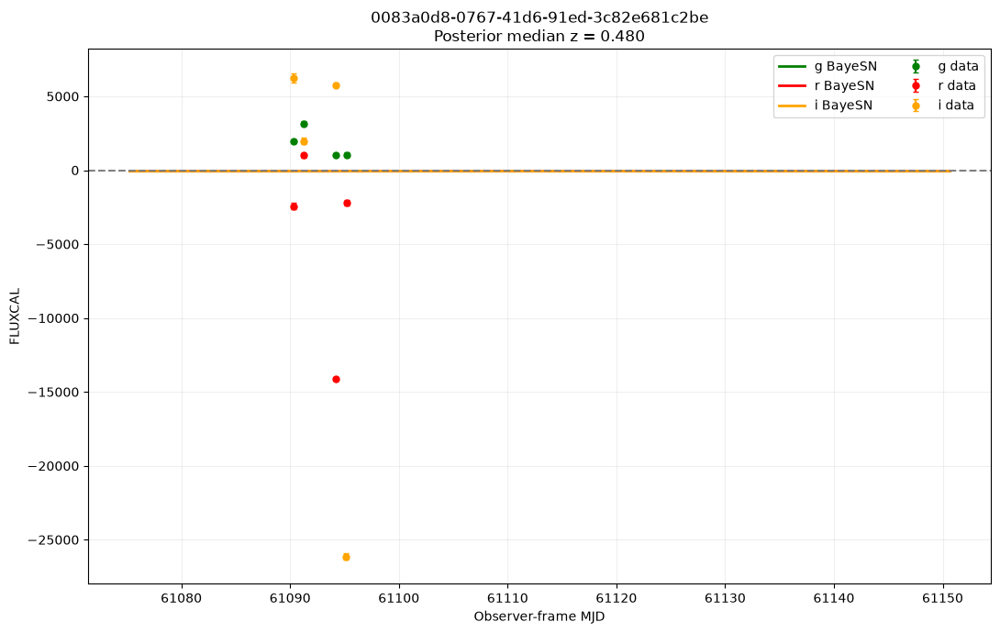

Getting photo-z posterior-predictive light curves from chains...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:11<00:00, 11.80s/it]


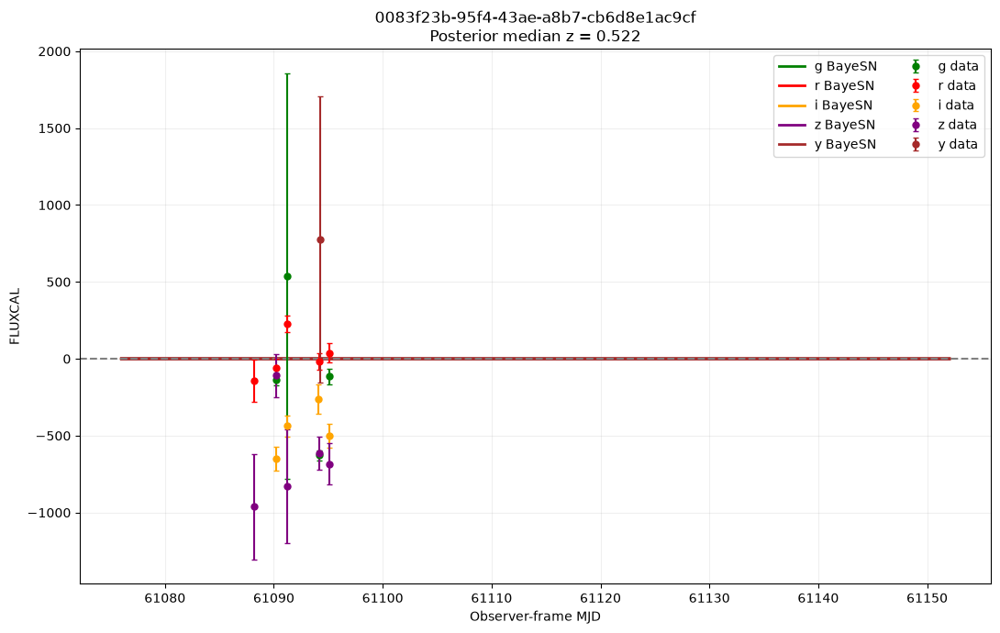

Getting photo-z posterior-predictive light curves from chains...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:10<00:00, 10.14s/it]


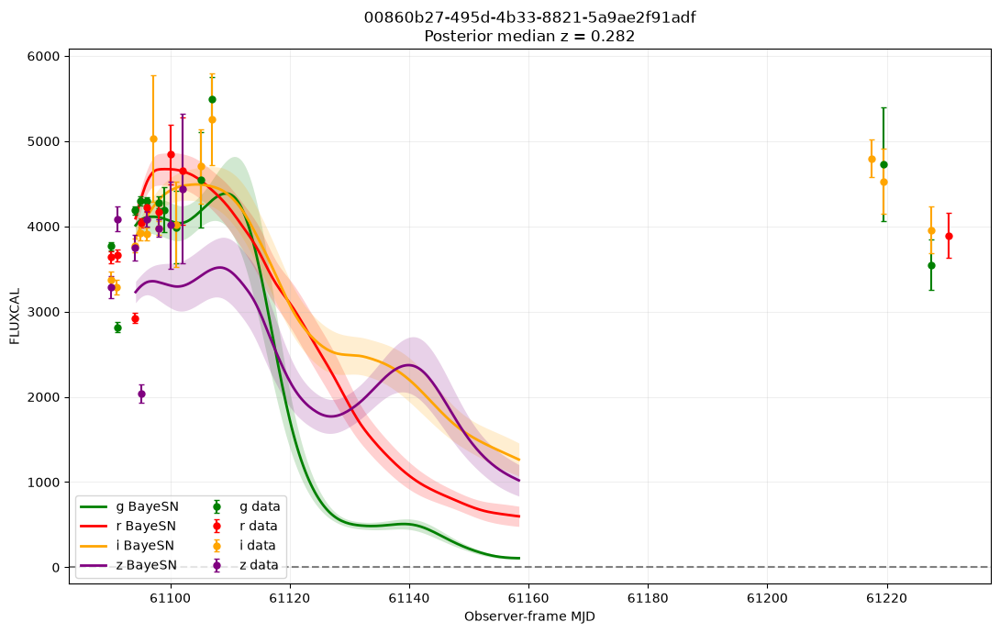

Getting photo-z posterior-predictive light curves from chains...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:08<00:00,  8.32s/it]


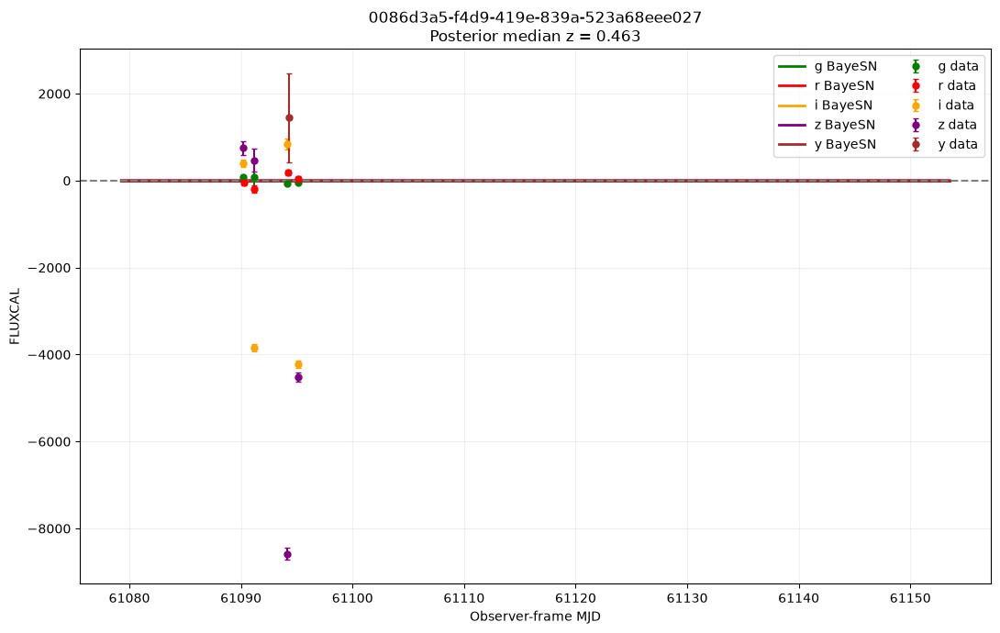

Getting photo-z posterior-predictive light curves from chains...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.82s/it]


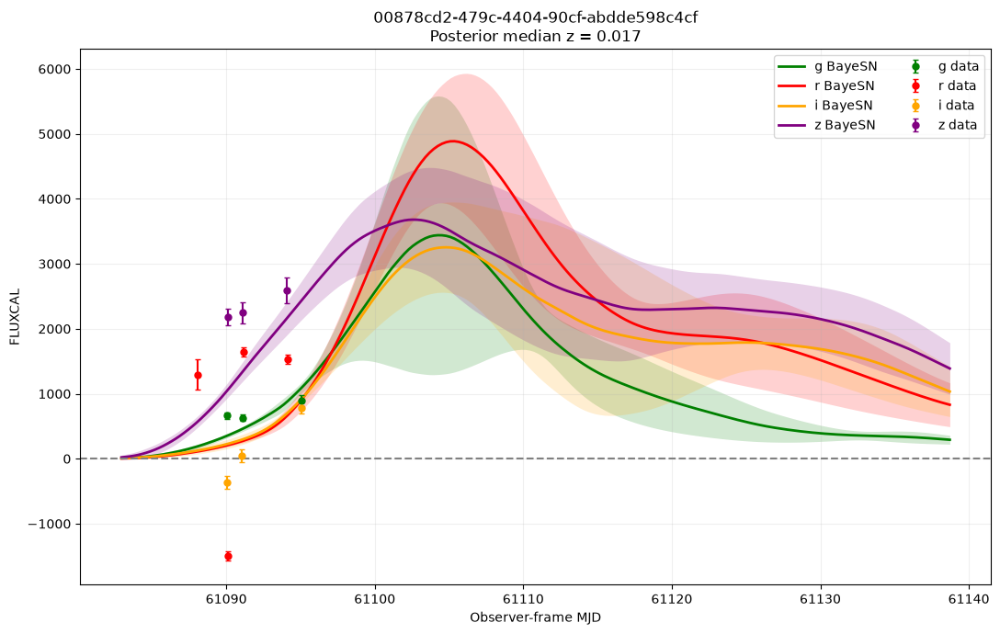

Getting photo-z posterior-predictive light curves from chains...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:04<00:00,  4.20s/it]


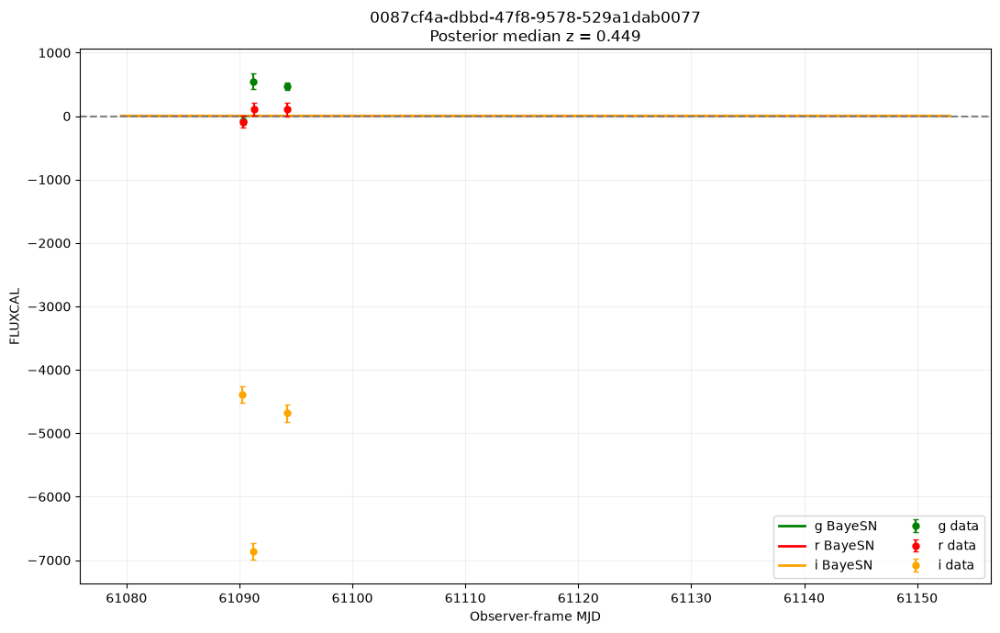

Getting photo-z posterior-predictive light curves from chains...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


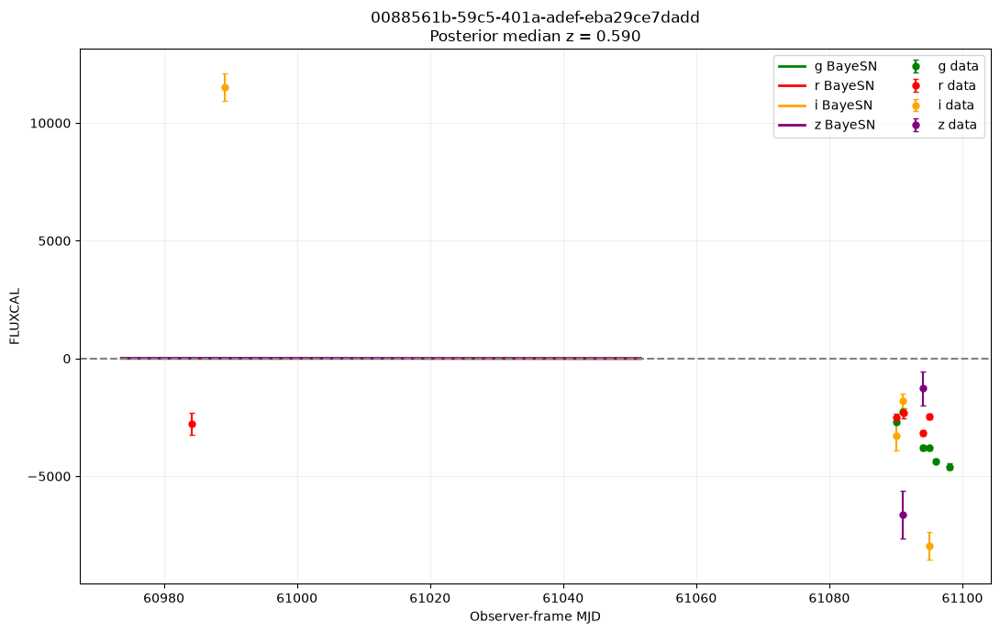

Getting photo-z posterior-predictive light curves from chains...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.52s/it]


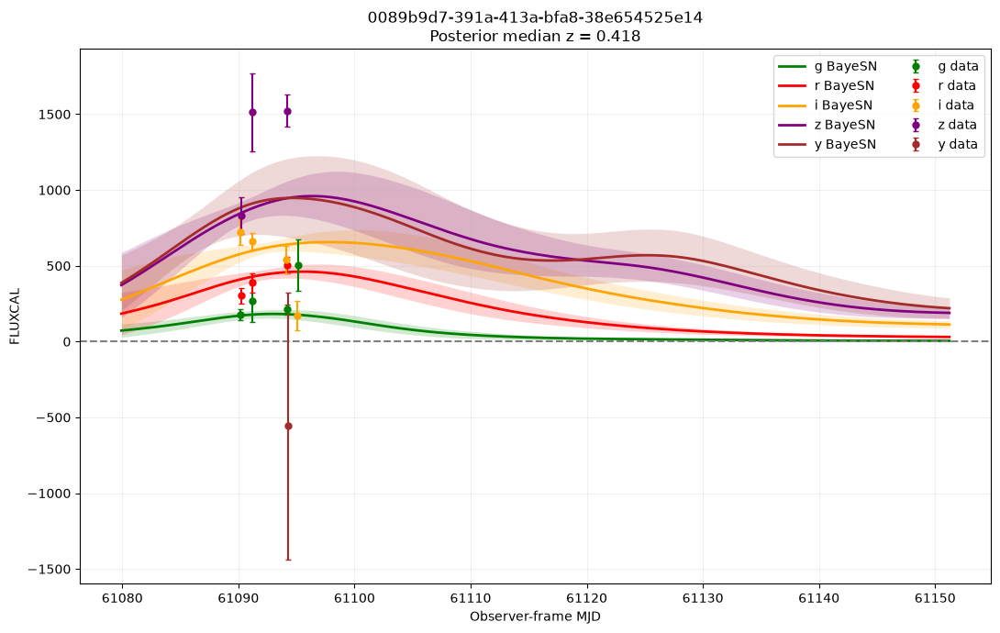

In [15]:
for snid, result in batch_0.items():
    plot_fit(snid, result["samples"])

In [27]:
def plot_fit(snid, samples, mjd_min=None, mjd_max=None):
    idx = np.flatnonzero(
        np.char.strip(head_data["SNID"].astype(str)) == snid
    )[0]
    head_row = head_data[idx]

    lc = get_lightcurve(head_row, phot_data)

    float_cols = lc.select_dtypes(include="float").columns
    lc[float_cols] = lc[float_cols].astype("float32")
    lc["DETNUM"] = lc["DETNUM"].astype("int16")

    lc = lc[
        np.isfinite(lc["MJD"])
        & np.isfinite(lc["FLUXCAL"])
        & np.isfinite(lc["FLUXCALERR"])
        & (lc["FLUXCALERR"] > 0)
    ].copy()

    lc["BAND"] = (
        lc["BAND"].astype(str).str.strip().str.replace("LSST_", "", regex=False)
    )
    lc = lc.sort_values("MJD").reset_index(drop=True)

    peak_mjd = float(head_row["PEAKMJD"])
    lc = lc[lc["MJD"].between(peak_mjd - 20, peak_mjd + 200)].copy()

    t = np.asarray(lc["MJD"], dtype=float)
    flux = np.asarray(lc["FLUXCAL"], dtype=float)
    flux_err = np.asarray(lc["FLUXCALERR"], dtype=float)
    filters = np.asarray(lc["BAND"], dtype=str)

    observed_bands = [
        band for band in ["u", "g", "r", "i", "z", "y"]
        if band in np.unique(filters)
    ]

    plot_samples = dict(samples)
    if "mu" not in plot_samples:
        plot_samples["mu"] = plot_samples["Ds"]
    if "delM" not in plot_samples:
        plot_samples["delM"] = np.zeros_like(plot_samples["Ds"])

    model.peak_mjds = np.array([peak_mjd])
    model.ebv = np.array([float(head_row["MWEBV"])])

    set_band_state(model, observed_bands, LSST_FILT_MAP)

    fit_bands = [[LSST_FILT_MAP[band] for band in observed_bands]]

    model_mjd, model_mean, model_std = model.get_flux_from_chains_photoz(
        chains=plot_samples,
        bands=fit_bands,
        num_sne=1,
        n_grid=200,
        num_samples=200,
    )

    # --- restrict to window, display only (no refit) ---
    mjd_grid = model_mjd[0]
    lo = mjd_min if mjd_min is not None else mjd_grid.min()
    hi = mjd_max if mjd_max is not None else mjd_grid.max()
    model_mask = (mjd_grid >= lo) & (mjd_grid <= hi)
    data_mask_range = (t >= lo) & (t <= hi)

    z_median = np.median(np.asarray(samples["z"]).reshape(-1))

    fig, ax = plt.subplots(figsize=(11, 7))

    for band_index, band in enumerate(observed_bands):
        use = (filters == band) & data_mask_range
        colour = colours[band]

        ax.errorbar(
            t[use], flux[use], yerr=flux_err[use],
            fmt="o", ms=5, capsize=2, color=colour,
            label=f"{band} data", zorder=3,
        )

        fitted_flux = model_mean[0, band_index][model_mask]
        fitted_std = model_std[0, band_index][model_mask]
        fitted_mjd = mjd_grid[model_mask]

        ax.plot(fitted_mjd, fitted_flux, color=colour, linewidth=2,
                 label=f"{band} BayeSN", zorder=2)

        ax.fill_between(
            fitted_mjd, fitted_flux - fitted_std, fitted_flux + fitted_std,
            color=colour, alpha=0.18, linewidth=0, zorder=1,
        )

    ax.axhline(0, color="grey", linestyle="--")
    ax.set(
        xlabel="Observer-frame MJD",
        ylabel="FLUXCAL",
        title=f"{snid}\nPosterior median z = {z_median:.3f}",
    )
    ax.legend(ncol=2)
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:08<00:00,  8.09s/it]


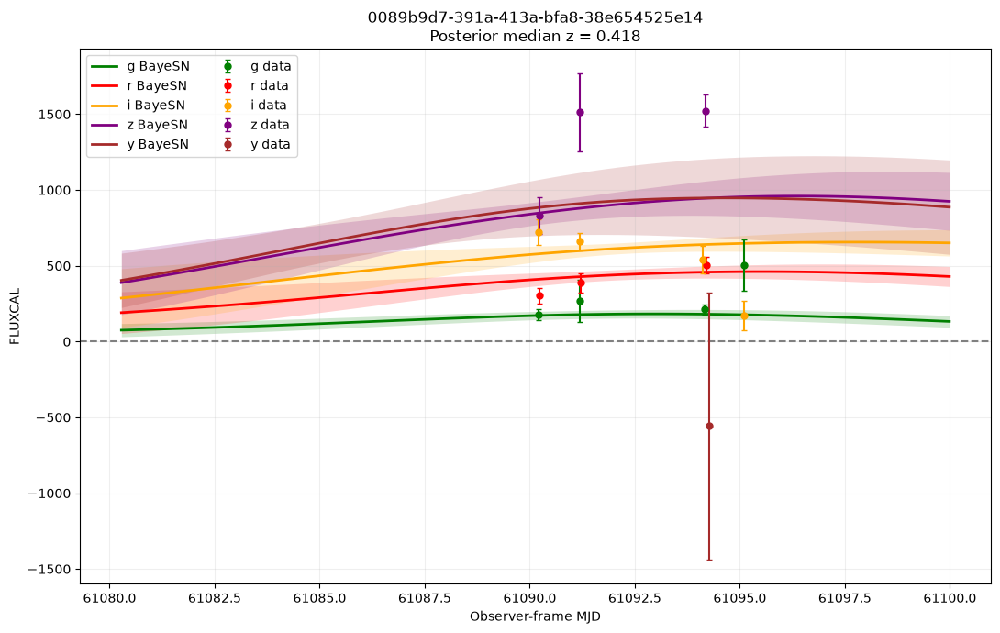

In [29]:
snid = "0089b9d7-391a-413a-bfa8-38e654525e14"
plot_fit(snid, batch_0[snid]["samples"], mjd_min=61080, mjd_max=61100)

Getting photo-z posterior-predictive light curves from chains...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.60s/it]


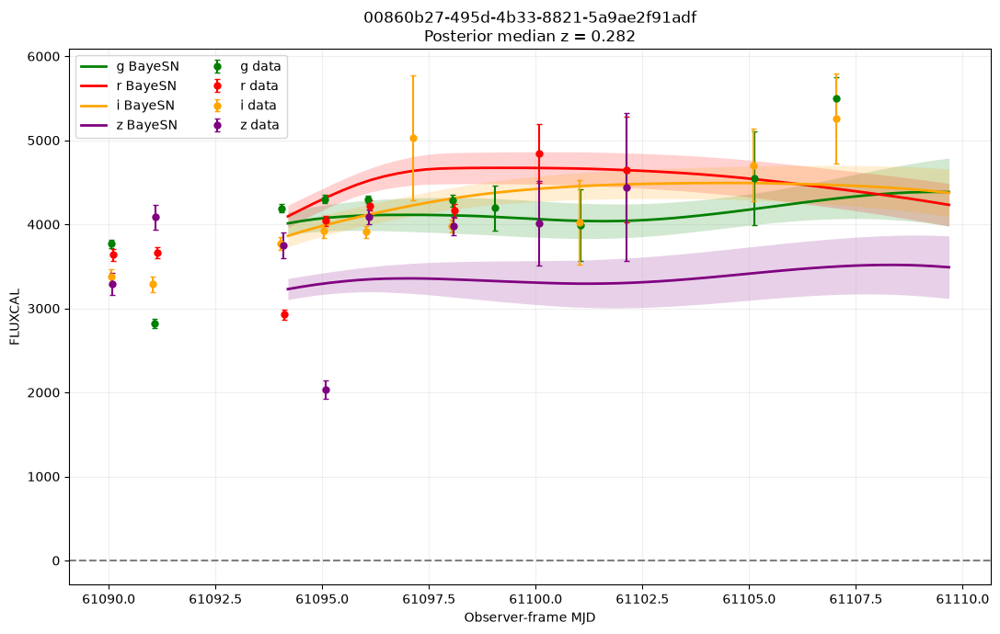

In [21]:
plot_fit("00860b27-495d-4b33-8821-5a9ae2f91adf", batch_0["00860b27-495d-4b33-8821-5a9ae2f91adf"]["samples"], mjd_min=61090, mjd_max=61110)

In [30]:
import pickle
from pathlib import Path

batch_path = Path("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks/fit_results/batch_0001.pkl")

with open(batch_path, "rb") as f:
    batch_0 = pickle.load(f)

print(f"{len(batch_0)} fits in this batch:")
for snid in batch_0:
    print(" ", snid)

8 fits in this batch:
  008bd9a3-dd65-4ead-8fcb-7f5edc7b836c
  0091b1a6-ea09-4467-b959-d7954dbe9a9b
  00922a45-1965-4664-a2ec-8ce4039cf41c
  00948fac-2ec0-438c-8de0-29f6ea6a2eda
  00949e23-371b-4db3-b01e-1808eb80a058
  00973674-021e-48ea-b302-26bb9ce1a194
  00984738-9756-4be0-94fa-6a832a65ecb7
  009cc0d2-430f-4c05-b04d-cbe80c59f9a3


Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.21s/it]


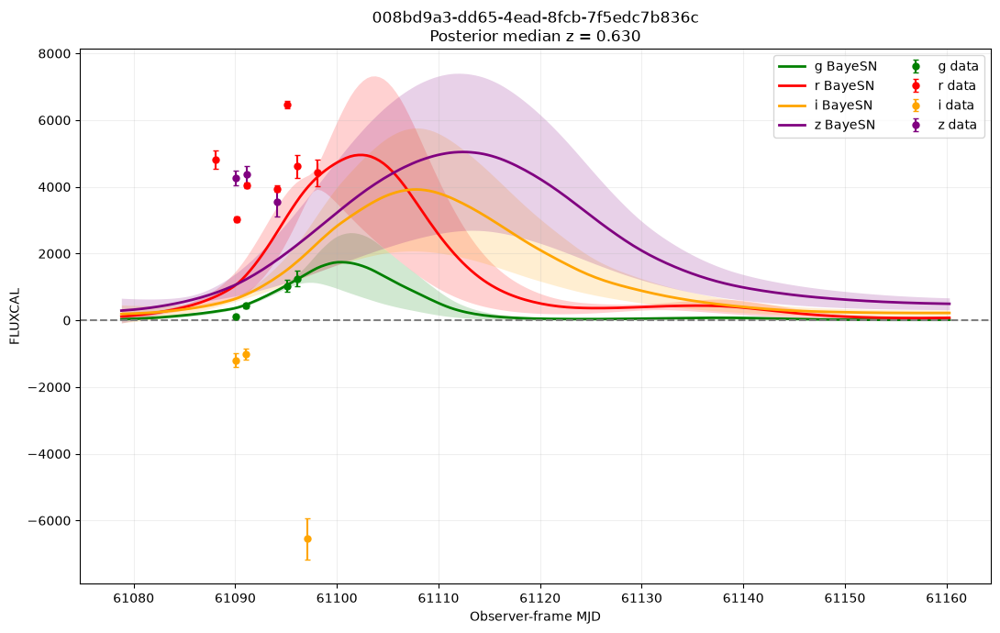

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.06s/it]


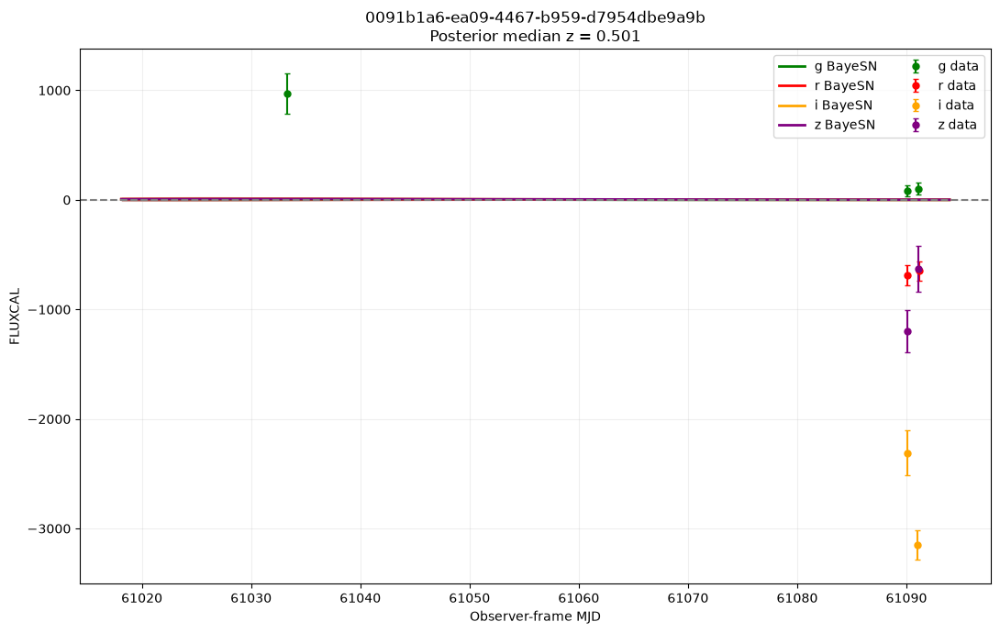

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.24s/it]


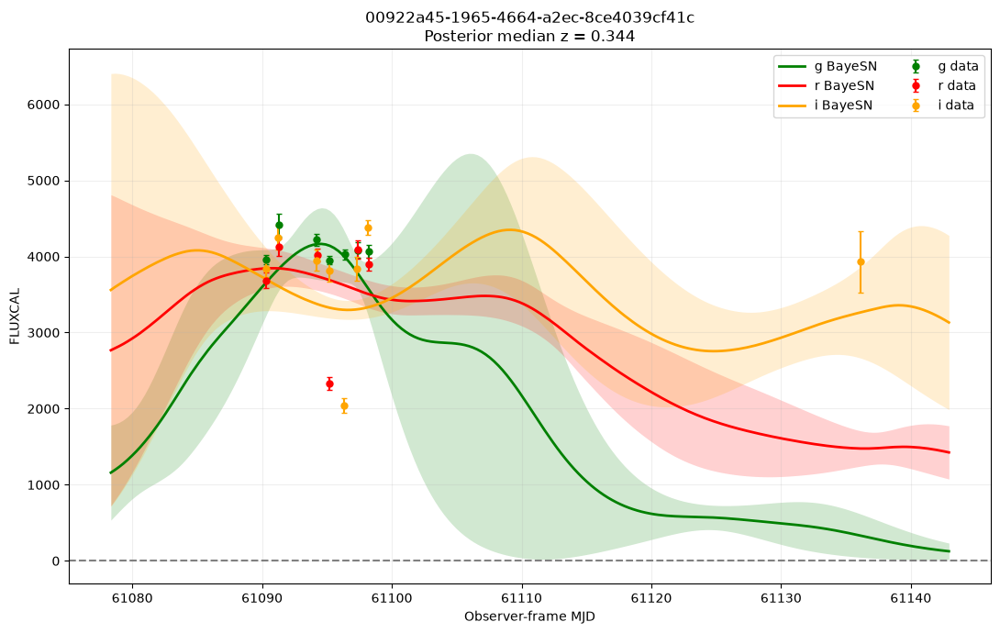

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.67s/it]


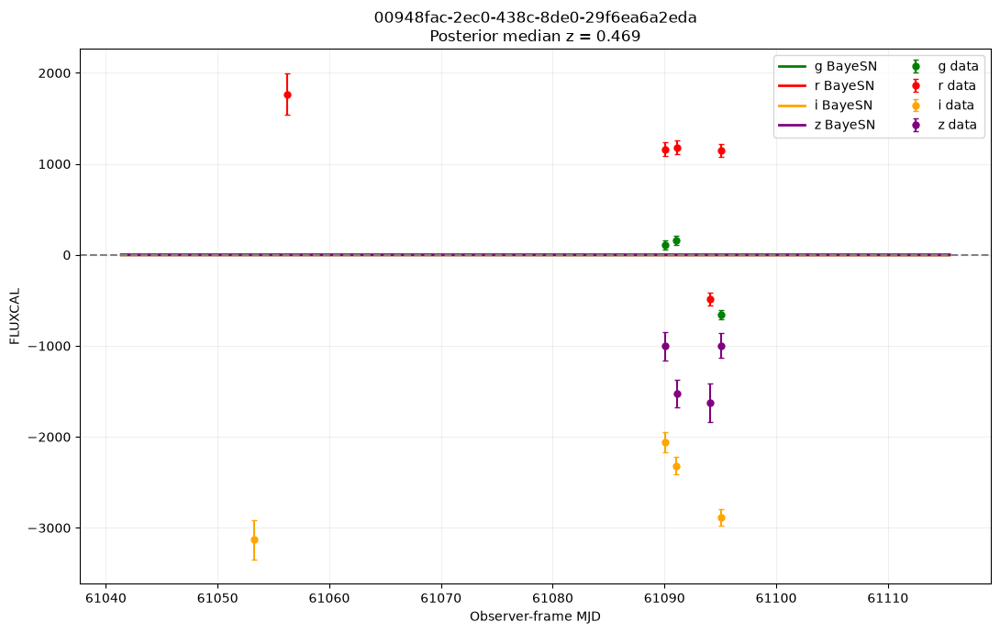

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.12s/it]


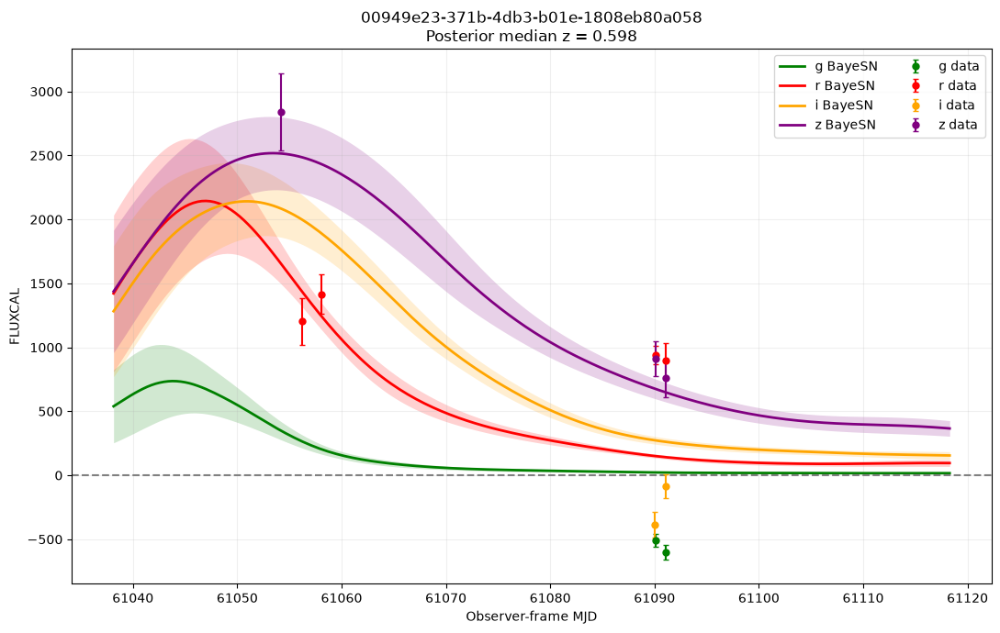

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.07s/it]


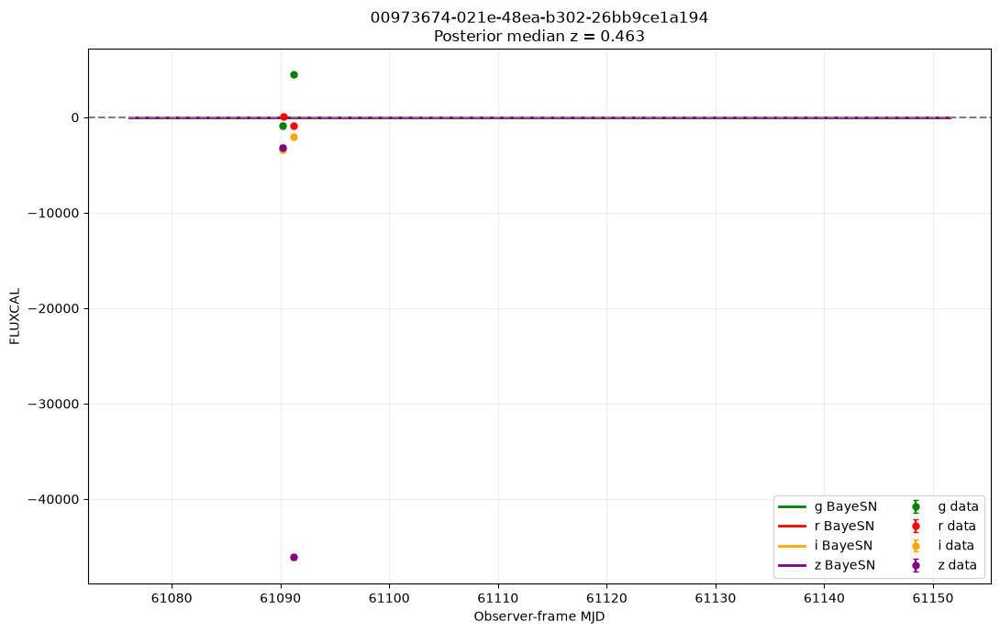

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.94s/it]


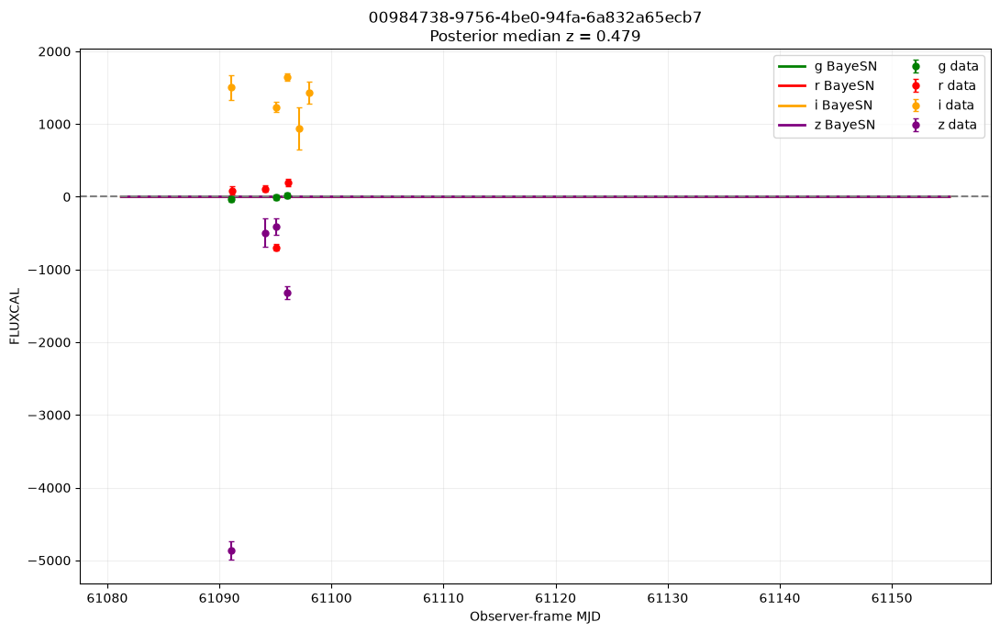

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:03<00:00,  3.77s/it]


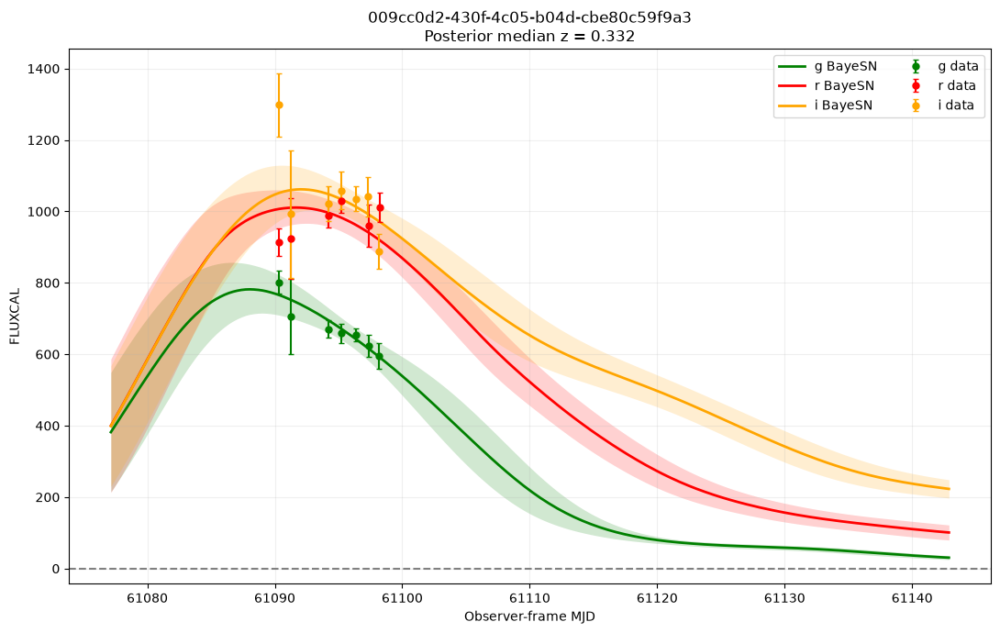

In [31]:
for snid, result in batch_0.items():
    plot_fit(snid, result["samples"])

7 fits in this batch:
  009d94ce-0e90-4925-ad23-68aac553fa41
  009e6f5e-fb23-40a3-9966-6ae8e8a132b8
  009f8216-838c-4441-aa11-35bb16613318
  00a15a39-0950-46ff-b6d9-6409448b74d5
  00a2843f-3370-4a2a-98b6-f5ce7528f948
  00a6f58b-158f-4eec-a603-3e01d8b8c498
  00a89971-25a8-4837-b361-ce32e1cf207c
Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.23s/it]


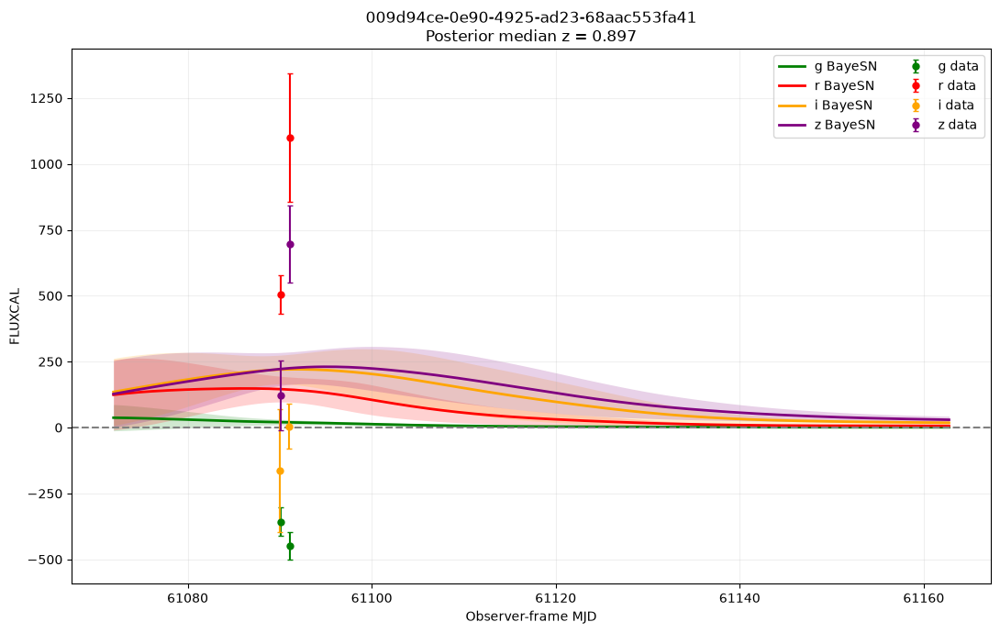

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:08<00:00,  8.44s/it]


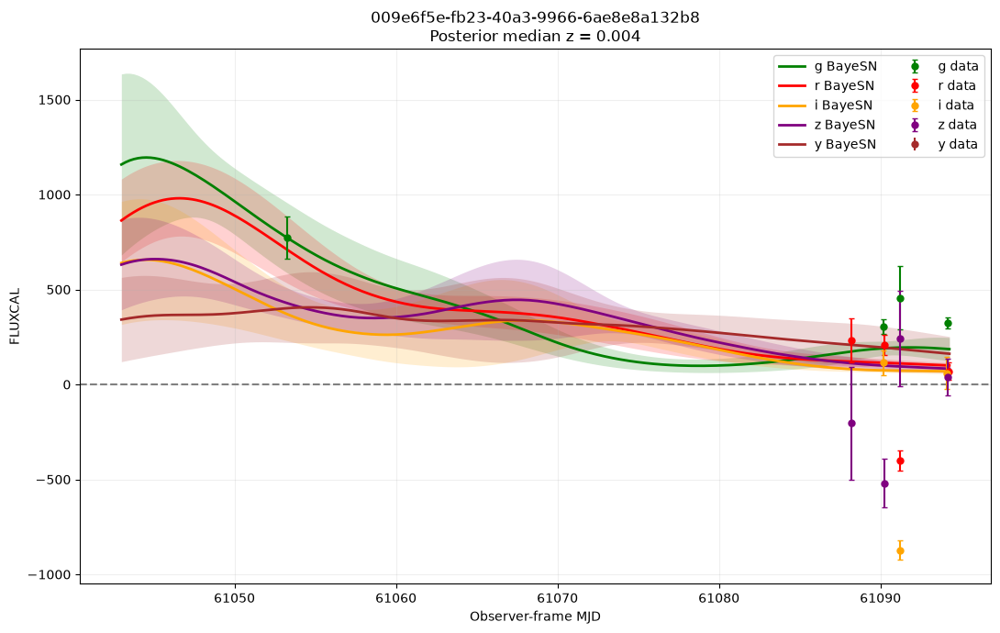

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.37s/it]


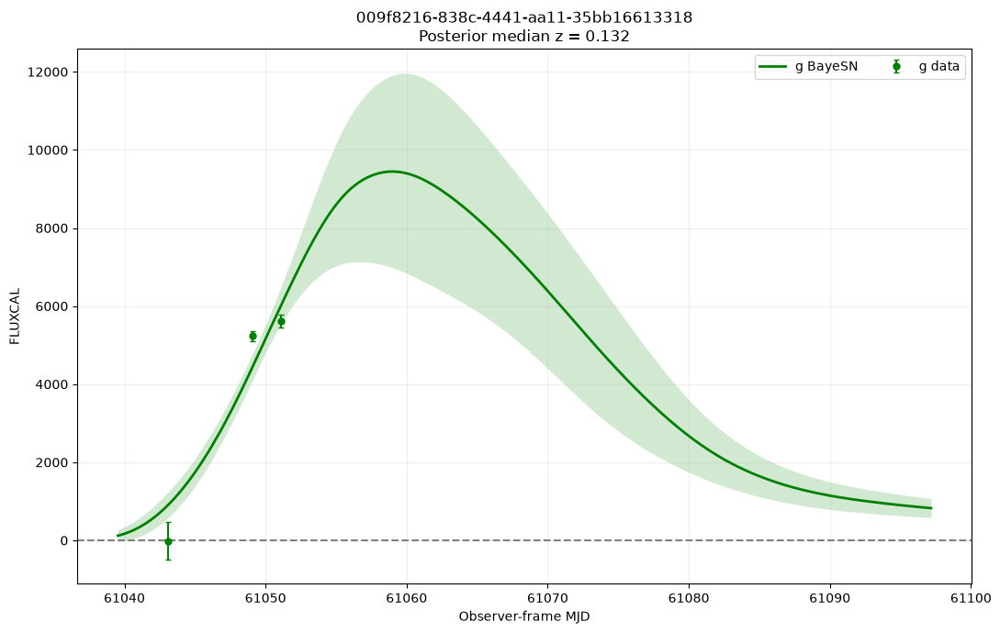

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.04s/it]


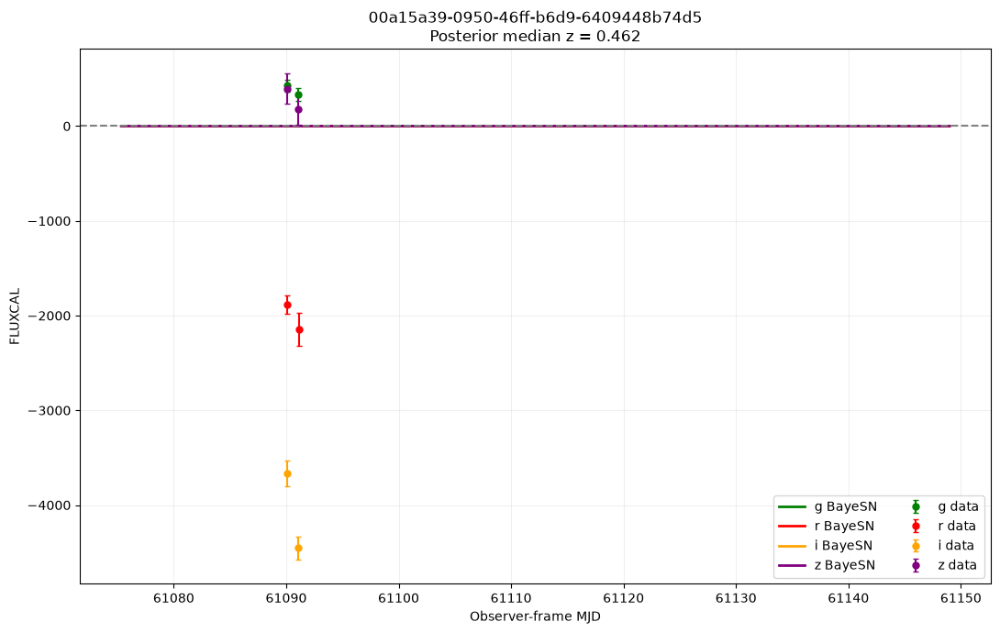

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:04<00:00,  4.52s/it]


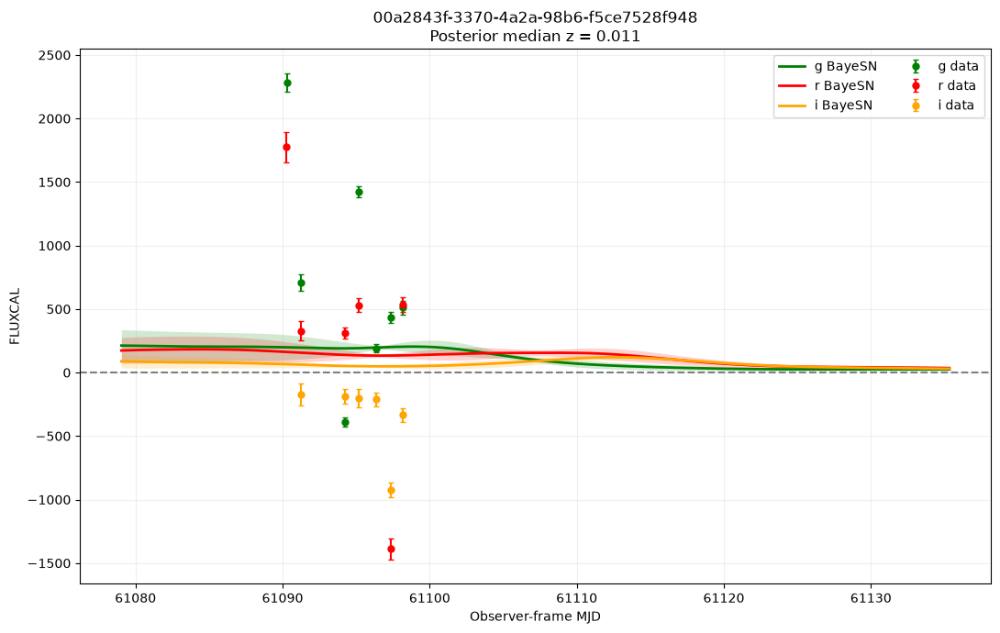

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.22s/it]


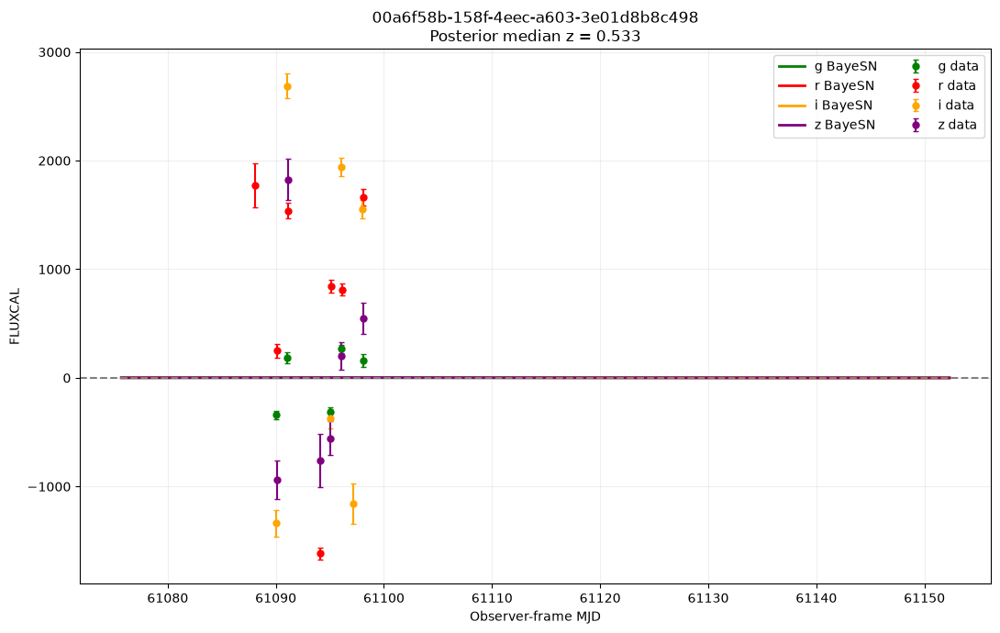

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:04<00:00,  4.69s/it]


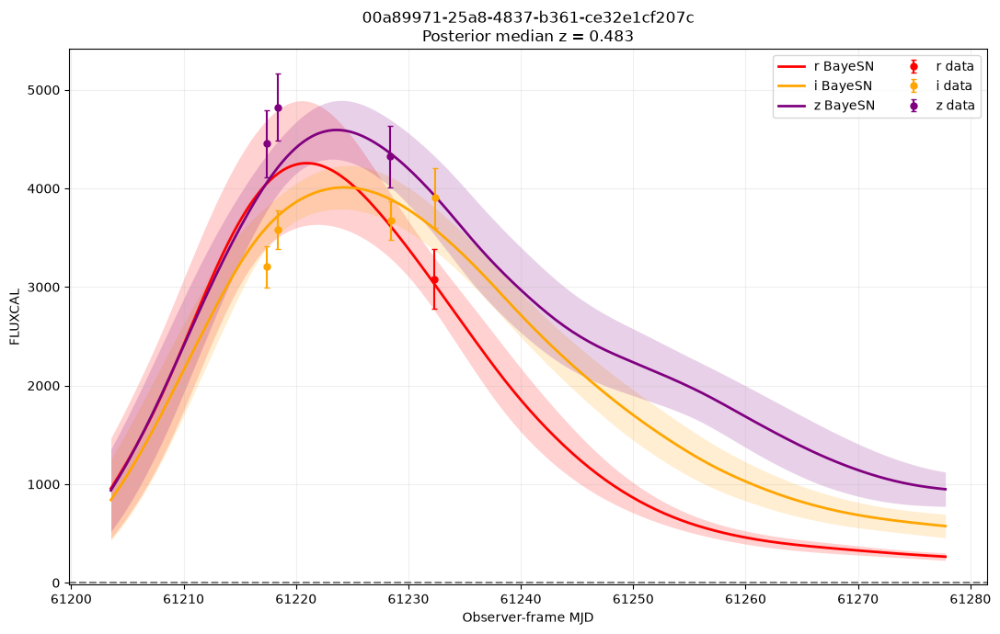

In [32]:
import pickle
from pathlib import Path

batch_path = Path("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks/fit_results/batch_0002.pkl")

with open(batch_path, "rb") as f:
    batch_0 = pickle.load(f)

print(f"{len(batch_0)} fits in this batch:")
for snid in batch_0:
    print(" ", snid)

for snid, result in batch_0.items():
    plot_fit(snid, result["samples"])

9 fits in this batch:
  00a8a4b8-dfcb-4ee1-9812-71d5b21225d7
  00a9316f-4fd8-4d97-87f0-50851fb1627c
  00aa2a94-7ebb-45c0-a048-f91ff601a529
  00aa3407-9693-4e50-b643-d56135992995
  00b06dc7-d286-41ce-b227-b6a1ce29e68d
  00b43d92-a460-4056-a01d-2c5669ecbfd3
  00b43f24-dc7c-4697-a6be-e3c234707091
  00b6ef14-d917-49e7-a0e9-dcf90c9dc74c
  00b8b530-ef76-4679-99f5-d1e2c3feb79a
Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:09<00:00,  9.20s/it]


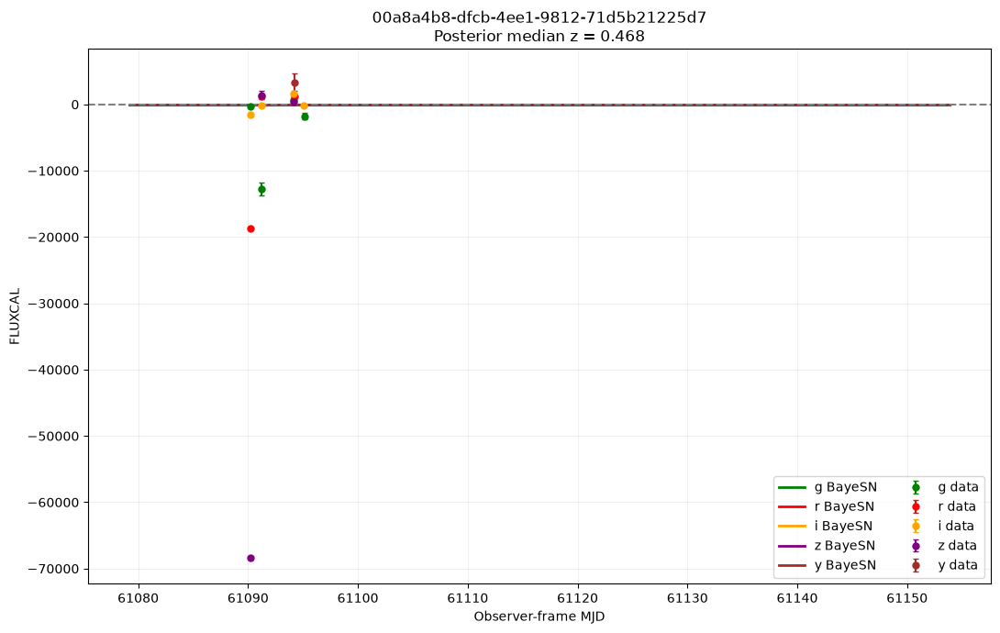

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.16s/it]


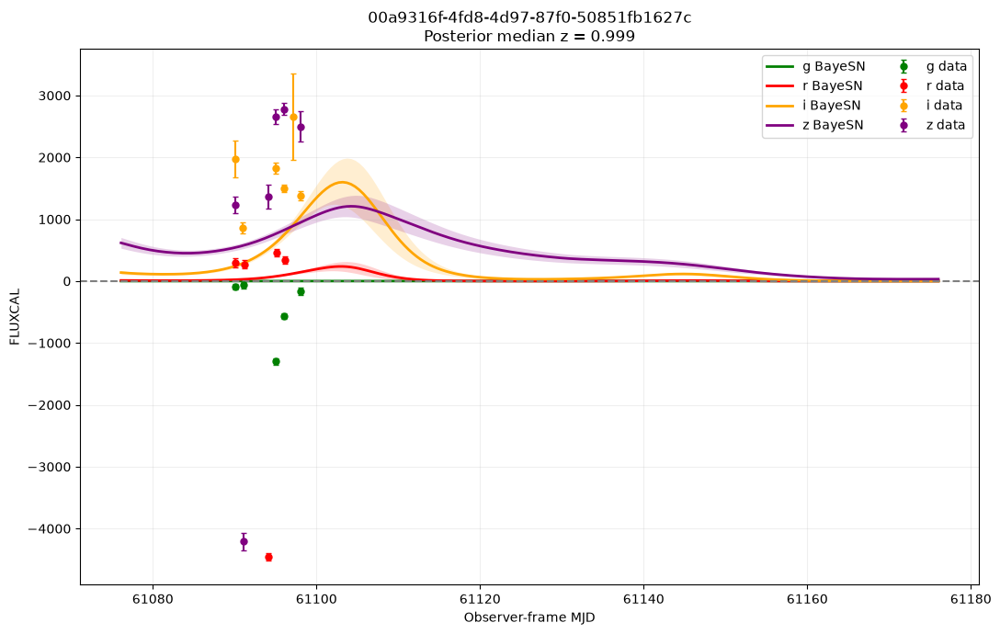

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.24s/it]


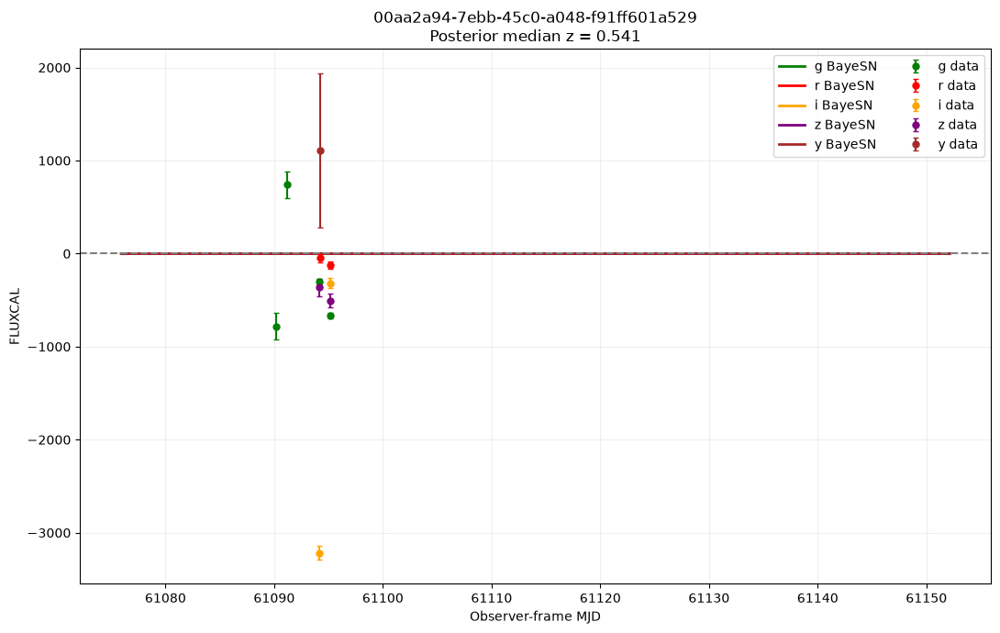

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:04<00:00,  4.29s/it]


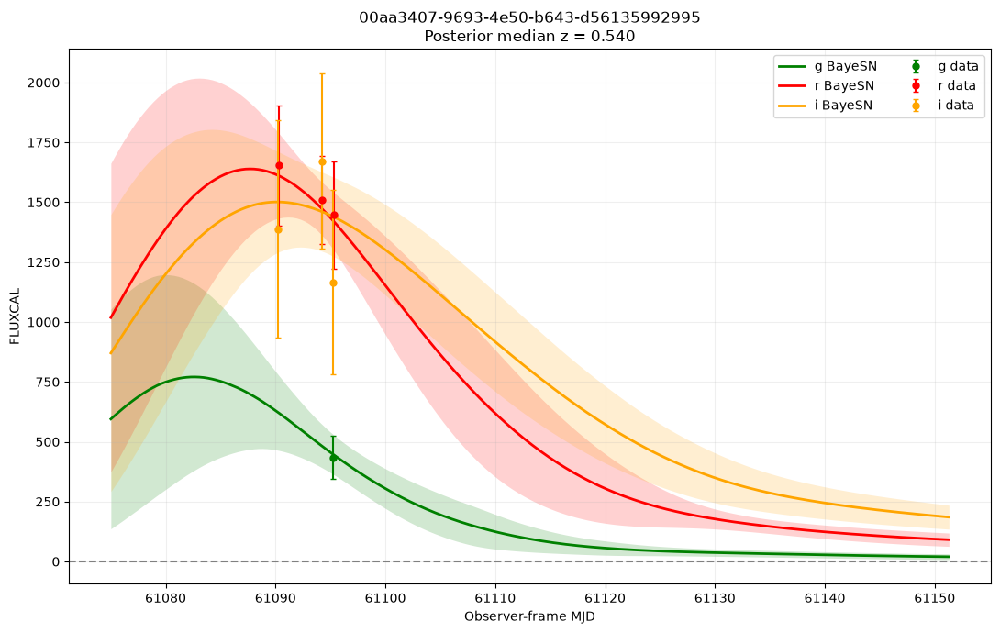

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.23s/it]


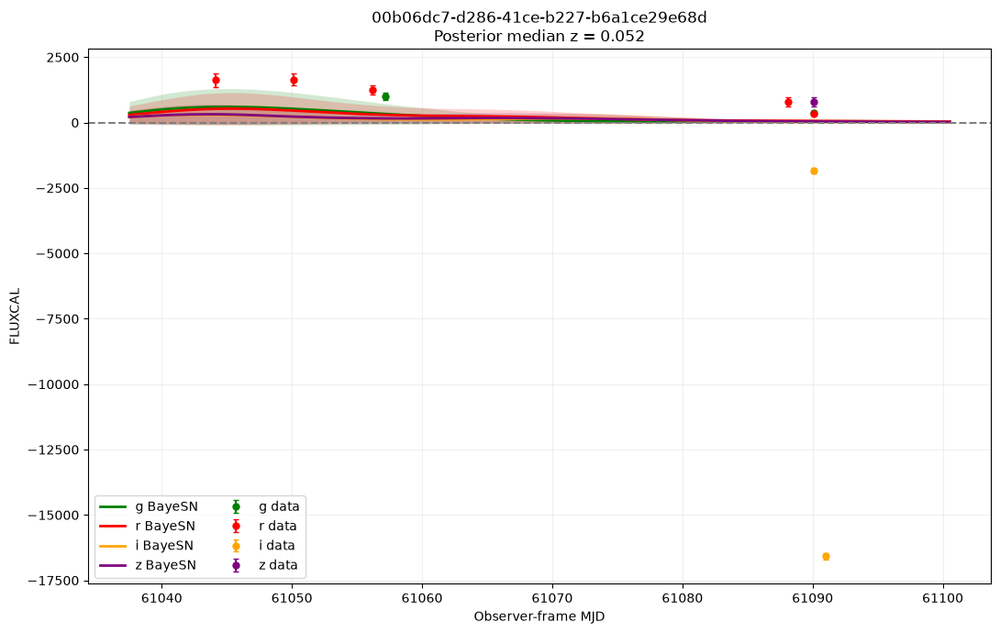

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.67s/it]


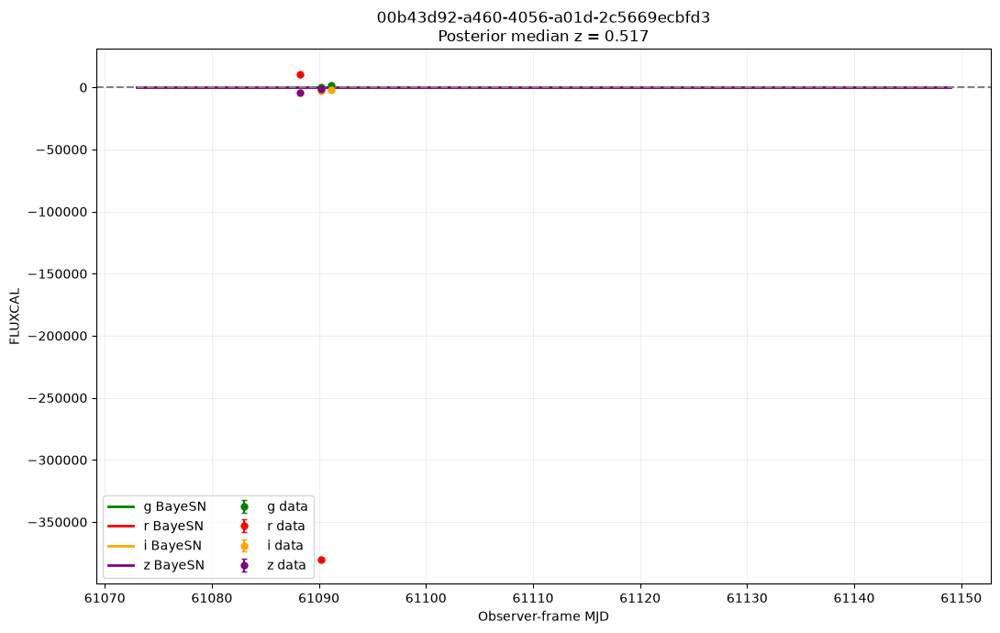

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.31s/it]


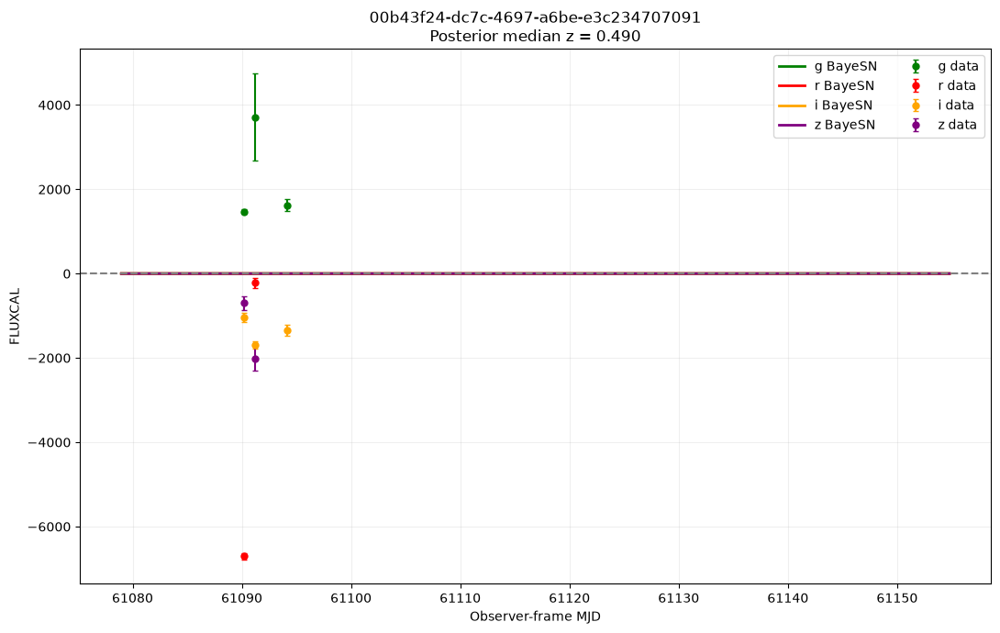

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.68s/it]


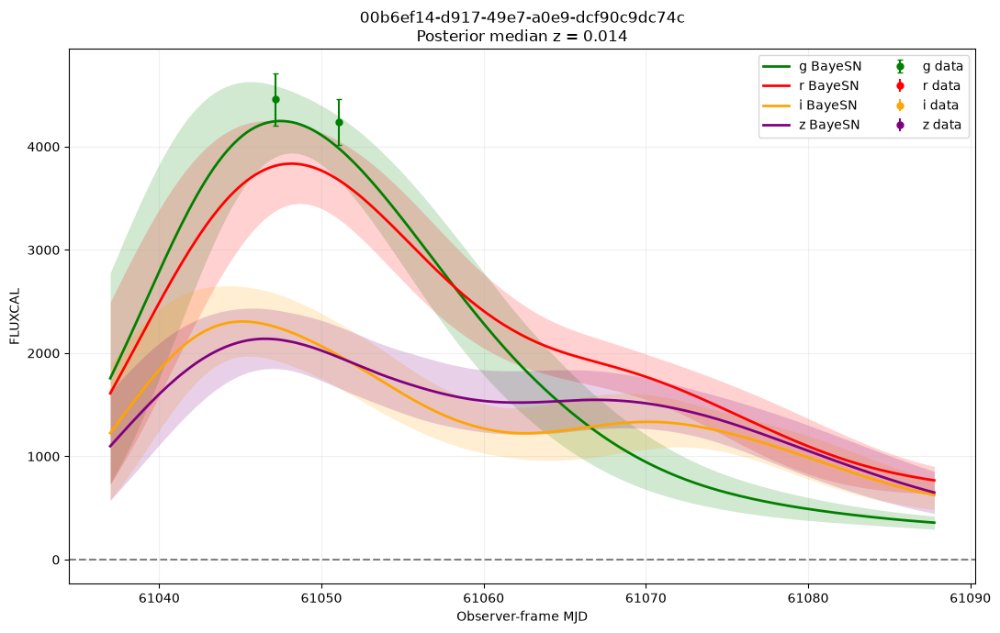

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.42s/it]


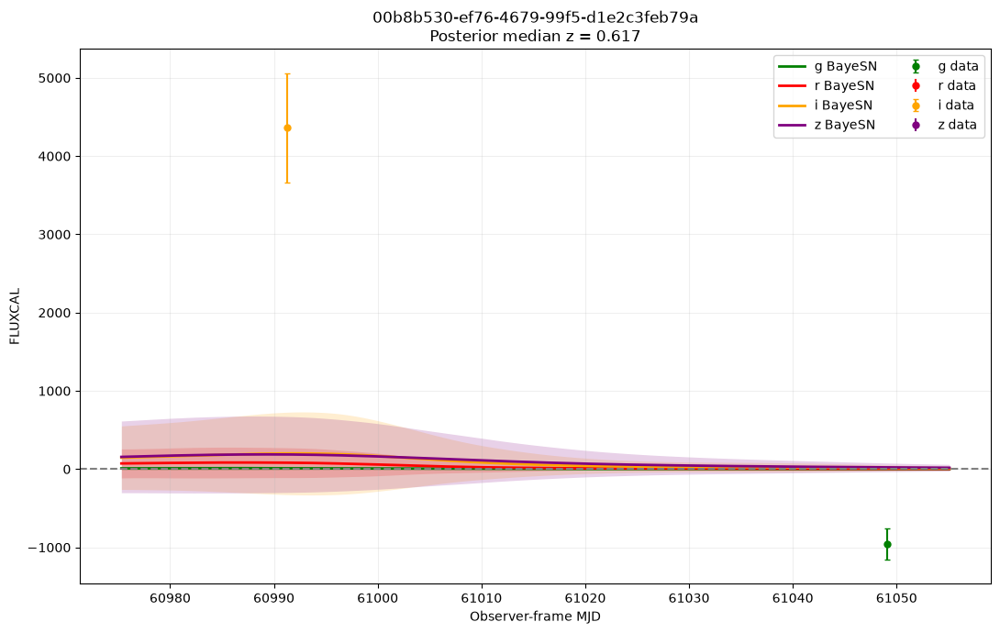

In [33]:
import pickle
from pathlib import Path

batch_path = Path("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks/fit_results/batch_0003.pkl")

with open(batch_path, "rb") as f:
    batch_0 = pickle.load(f)

print(f"{len(batch_0)} fits in this batch:")
for snid in batch_0:
    print(" ", snid)

for snid, result in batch_0.items():
    plot_fit(snid, result["samples"])

In [11]:
idx = np.flatnonzero(
    np.char.strip(head_data["SNID"].astype(str)) == "0083a0d8-0767-41d6-91ed-3c82e681c2be"
)[0]
head_row = head_data[idx]

print("PTROBS_MIN:", head_row["PTROBS_MIN"])
print("PTROBS_MAX:", head_row["PTROBS_MAX"])
print("NOBS:", head_row["NOBS"] if "NOBS" in head_data.dtype.names else "n/a")

lc = get_lightcurve(head_row, phot_data)
print(lc.shape)
print(lc[["MJD", "BAND", "FLUXCAL", "FLUXCALERR"]].sort_values("MJD").to_string())

PTROBS_MIN: 18
PTROBS_MAX: 29
NOBS: 12
(12, 21)
           MJD BAND       FLUXCAL  FLUXCALERR
0   61090.2997    i   6246.600098  313.899994
1   61090.3265    r  -2422.600098  225.979996
2   61090.3266    g   1942.400024  139.699997
3   61091.2463    i   1983.300049  235.720001
4   61091.2552    g   3156.399902  158.130005
5   61091.2642    r   1003.799988  158.220001
6   61094.2111    i   5769.100098  143.789993
7   61094.2233    g   1056.500000   97.936996
8   61094.2360    r -14130.000000  114.019997
9   61095.1693    i -26131.000000  215.220001
10  61095.1782    g   1051.300049  144.100006
11  61095.1851    r  -2209.000000  200.660004


In [12]:
print(lc.dtype.names if hasattr(lc, "dtype") else lc.columns.tolist())
print(lc[["MJD", "BAND", "FLUXCAL", "FLUXCALERR", "PHOTFLAG"]].to_string())

['MJD', 'BAND', 'DETNUM', 'IMGNUM', 'FIELD', 'PHOTFLAG', 'PHOTPROB', 'FLUXCAL', 'FLUXCALERR', 'PSF_SIG1', 'PSF_SIG2', 'PSF_RATIO', 'SKY_SIG', 'SKY_SIG_T', 'RDNOISE', 'ZEROPT', 'ZEROPT_ERR', 'TEXPOSE', 'GAIN', 'XPIX', 'YPIX']
           MJD BAND       FLUXCAL  FLUXCALERR  PHOTFLAG
0   61090.2997    i   6246.600098  313.899994         1
1   61090.3265    r  -2422.600098  225.979996         1
2   61090.3266    g   1942.400024  139.699997         1
3   61091.2463    i   1983.300049  235.720001         1
4   61091.2552    g   3156.399902  158.130005         1
5   61091.2642    r   1003.799988  158.220001         1
6   61094.2111    i   5769.100098  143.789993         1
7   61094.2233    g   1056.500000   97.936996         1
8   61094.2360    r -14130.000000  114.019997         1
9   61095.1693    i -26131.000000  215.220001         1
10  61095.1782    g   1051.300049  144.100006         1
11  61095.1851    r  -2209.000000  200.660004         1


5 fits in this batch:
  00bb81c9-c68e-47d1-821c-52eaba04822d
  00bb9981-e7fe-4d20-b2c5-48c905281c9b
  00bed8fa-a614-4eba-9a31-af412ea89a4a
  00c50771-a72e-441a-83e1-755e7b90bece
  00c84221-6bfd-4fc5-a9eb-8dac32e5a4cb
Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:10<00:00, 10.96s/it]


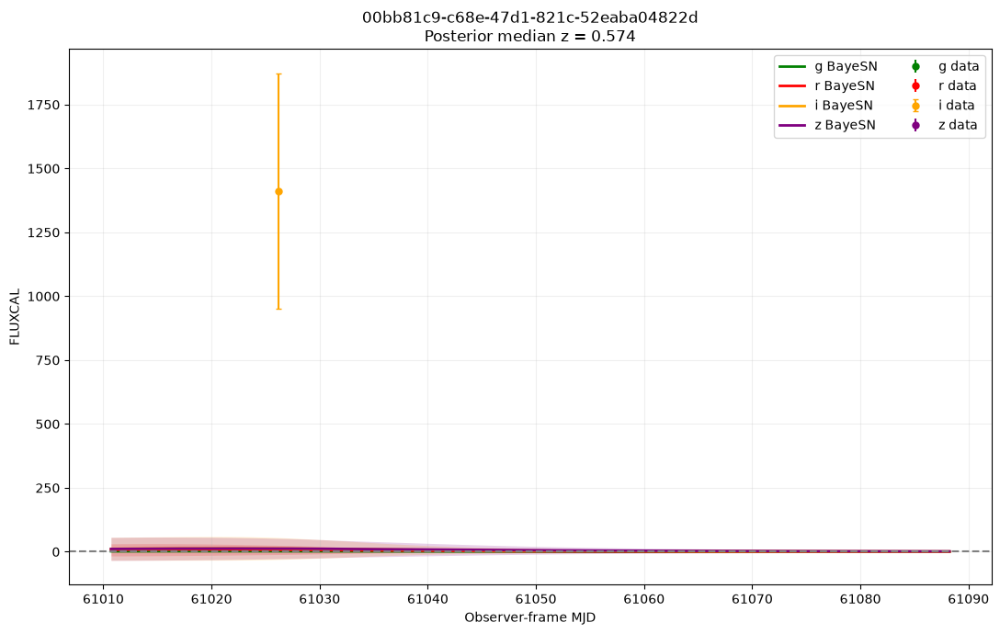

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.44s/it]


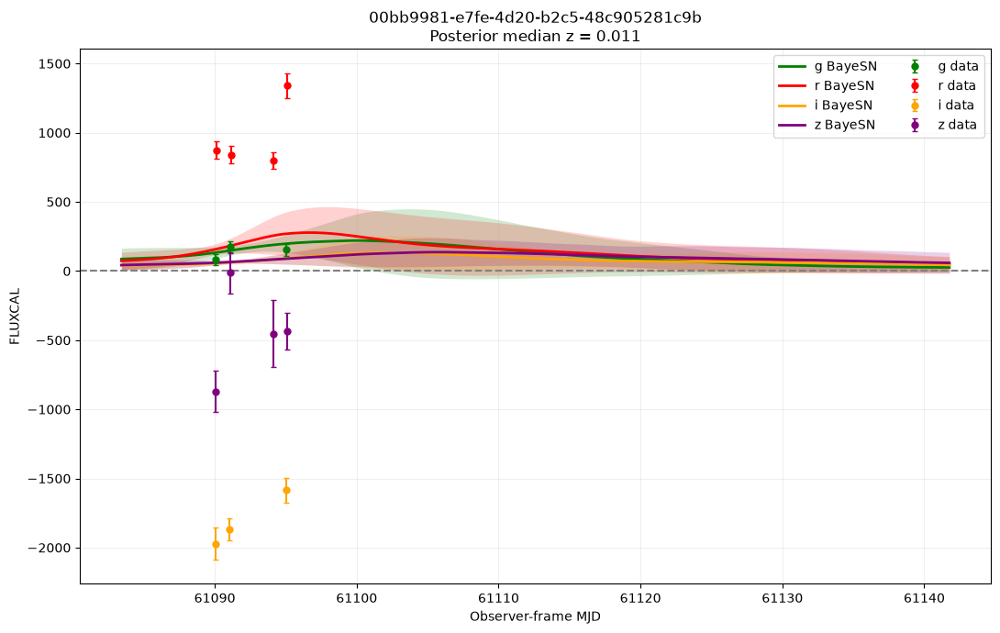

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.42s/it]


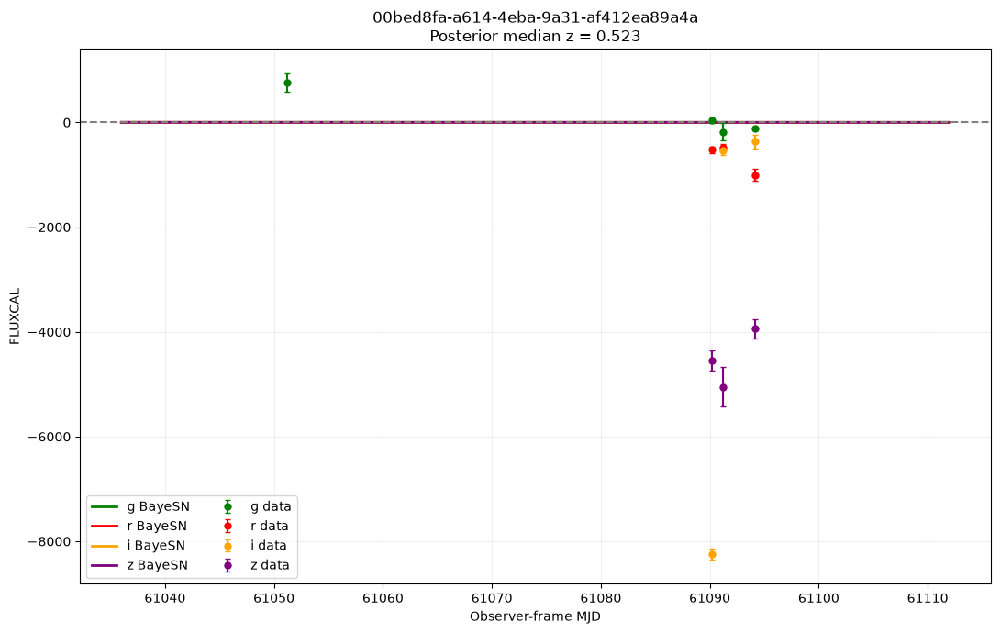

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.22s/it]


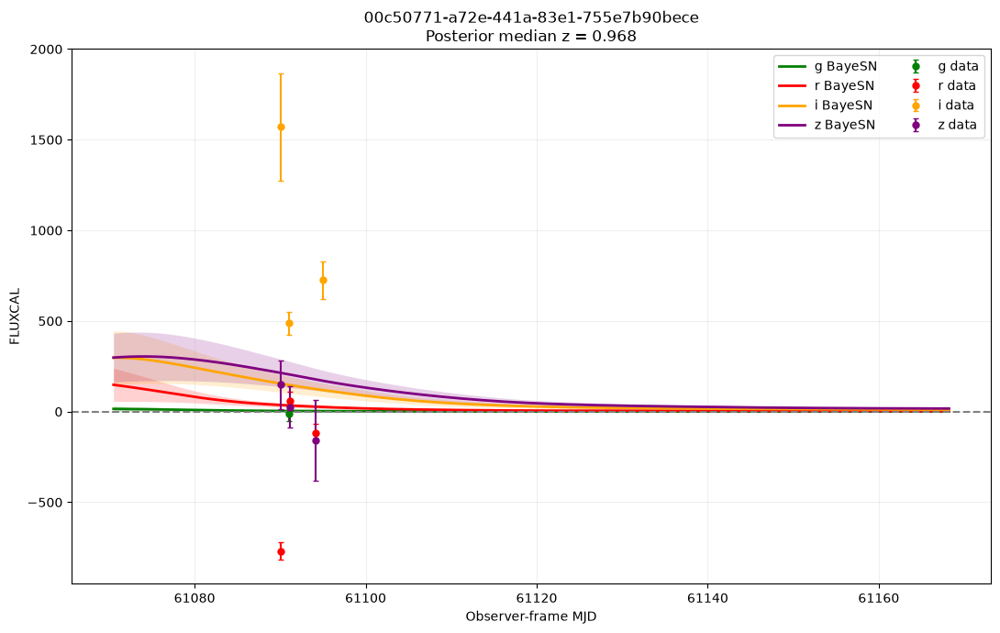

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.30s/it]


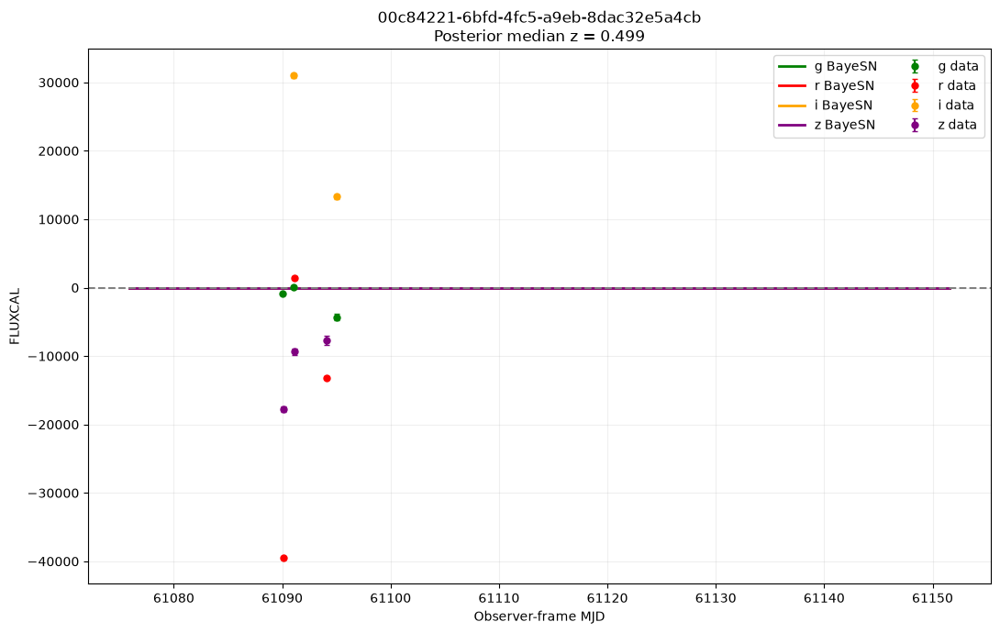

In [35]:
batch_path = Path("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks/fit_results/batch_0004.pkl")

with open(batch_path, "rb") as f:
    batch_0 = pickle.load(f)

print(f"{len(batch_0)} fits in this batch:")
for snid in batch_0:
    print(" ", snid)

for snid, result in batch_0.items():
    plot_fit(snid, result["samples"])

9 fits in this batch:
  00cf8aff-74c7-4252-a139-245b0453f7ea
  00d07183-a62a-4e6c-8f7b-2f99059f62eb
  00d0e7ff-fb5e-4576-8acb-5fde67881efb
  00d194c4-d2a9-4b1a-9fd0-c49a84180d59
  00d35f55-a6ea-4bff-a1c3-8daa4ac2ea04
  00d36207-f887-461a-b387-690972bb6119
  00d3b8be-86bd-4d21-b598-262a1bb94ef7
  00d7ae61-5afb-4647-97e9-aa5aac3c362f
  00d92916-5353-4ffd-9735-65481188757a
Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.83s/it]


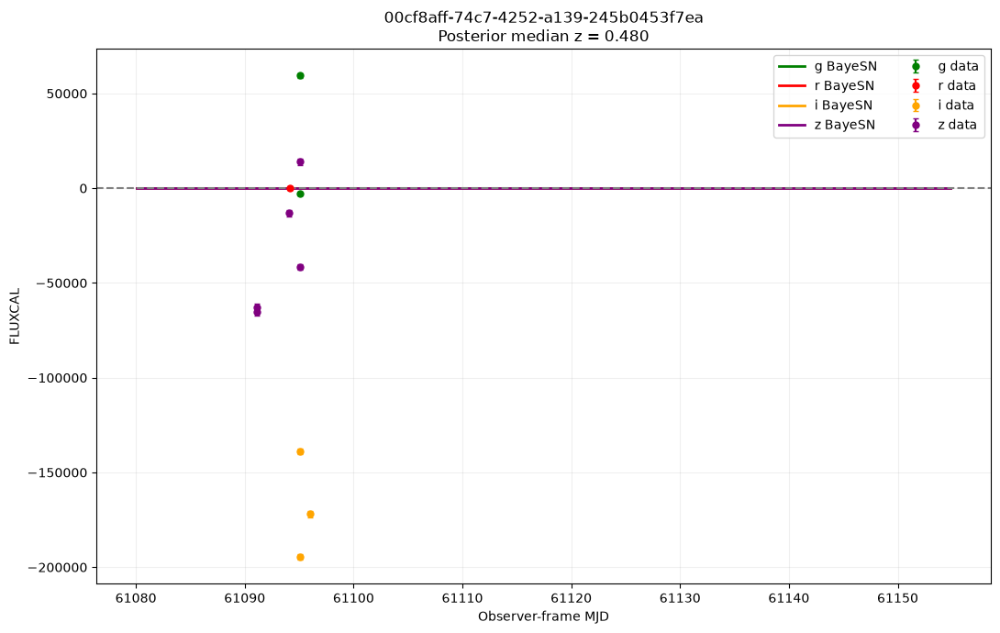

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.23s/it]


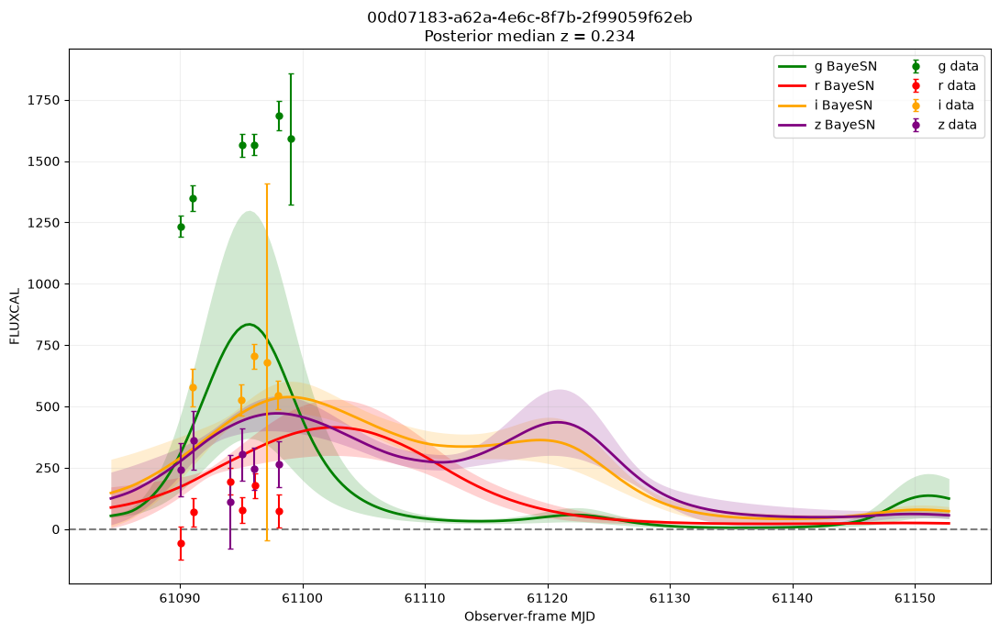

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.31s/it]


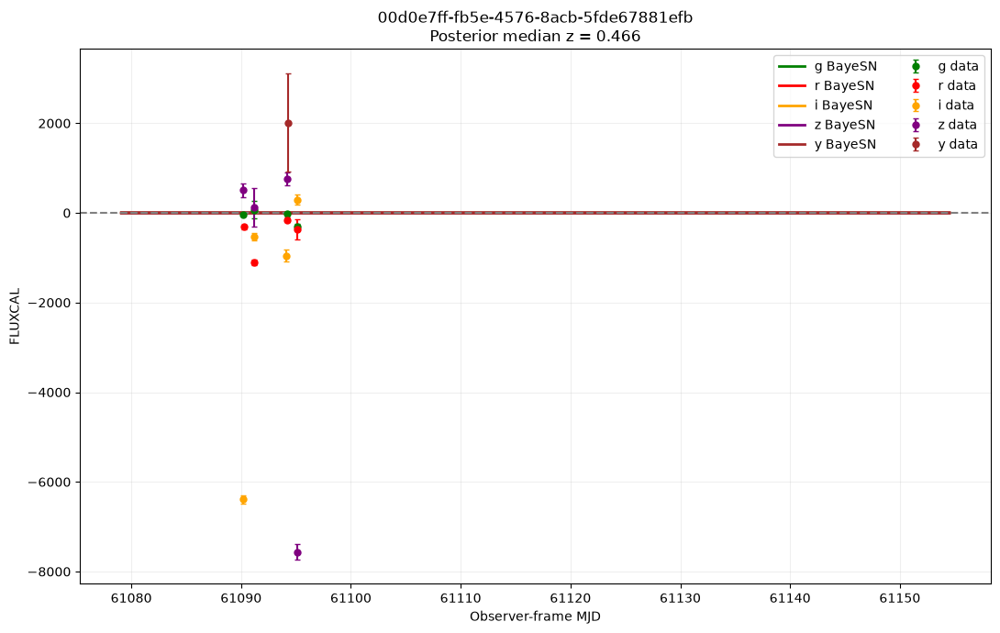

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:04<00:00,  4.44s/it]


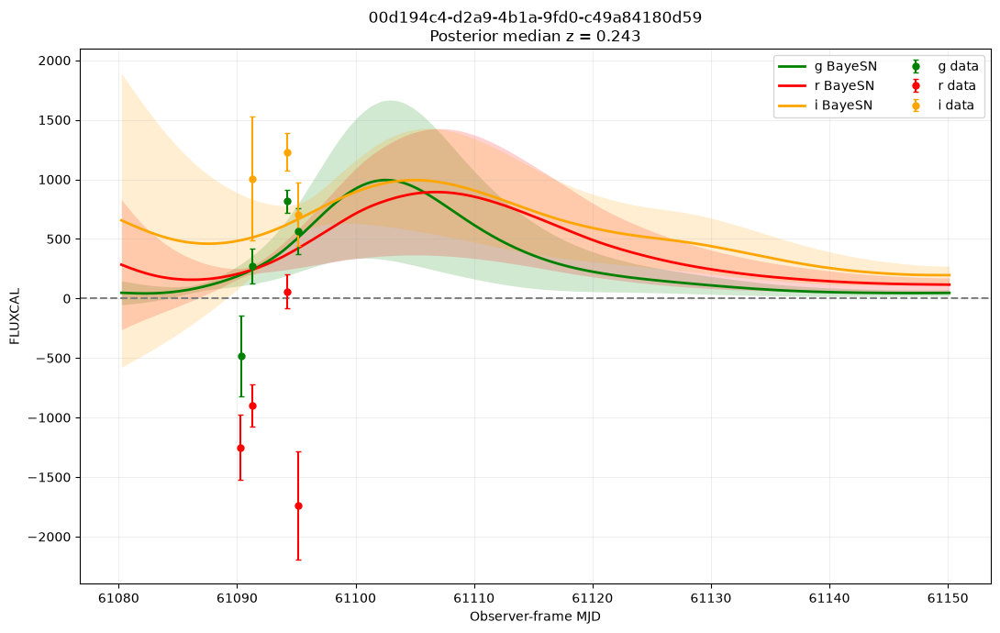

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.50s/it]


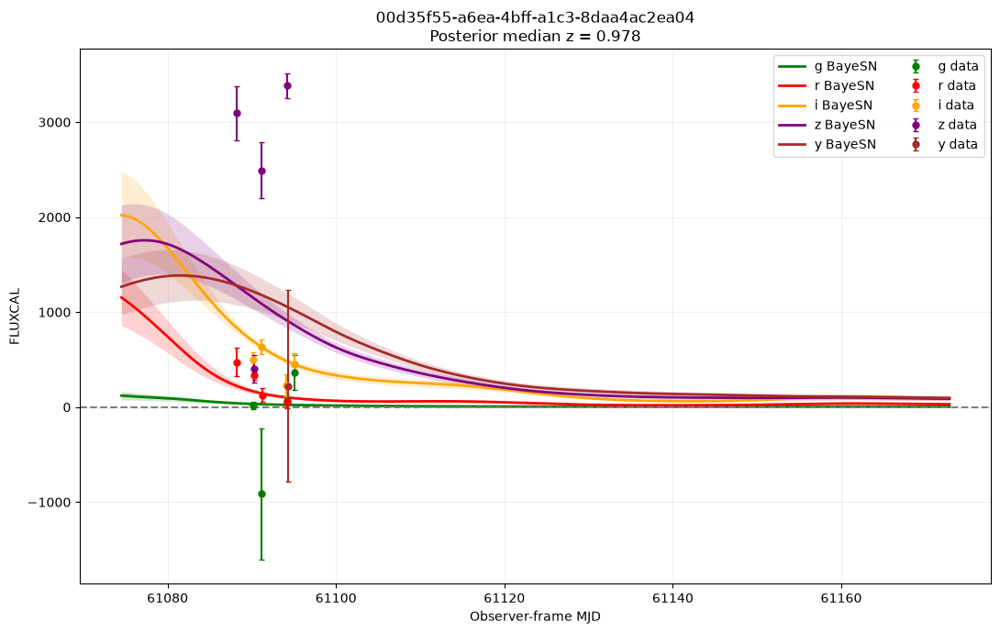

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.52s/it]


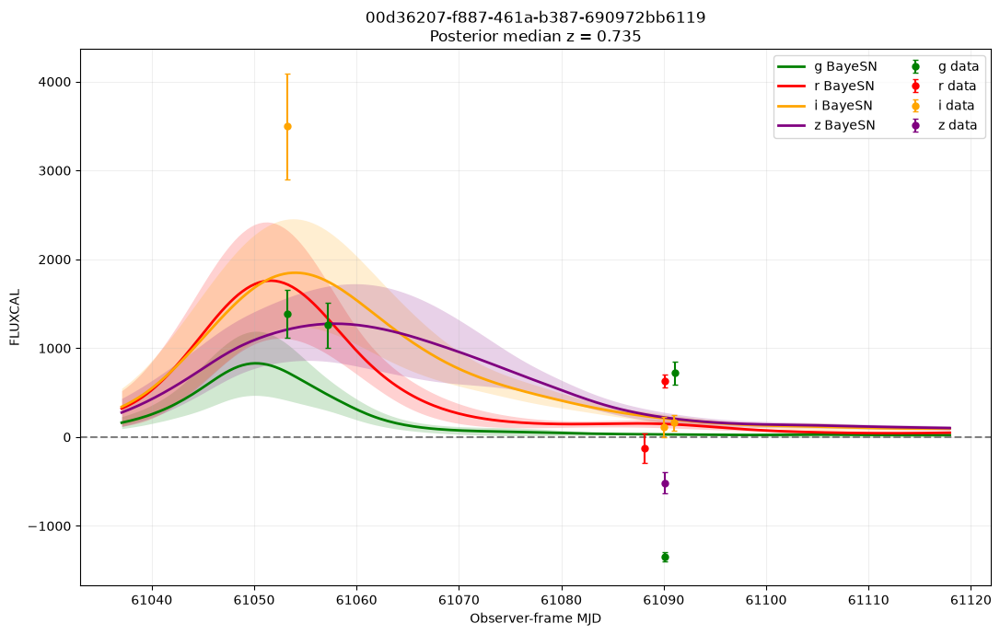

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.73s/it]


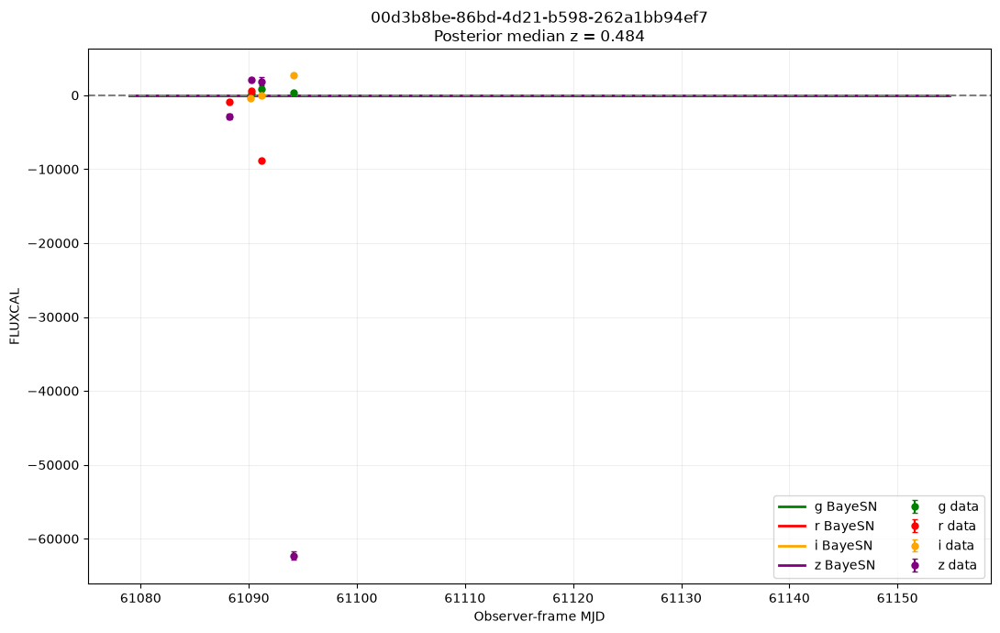

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.54s/it]


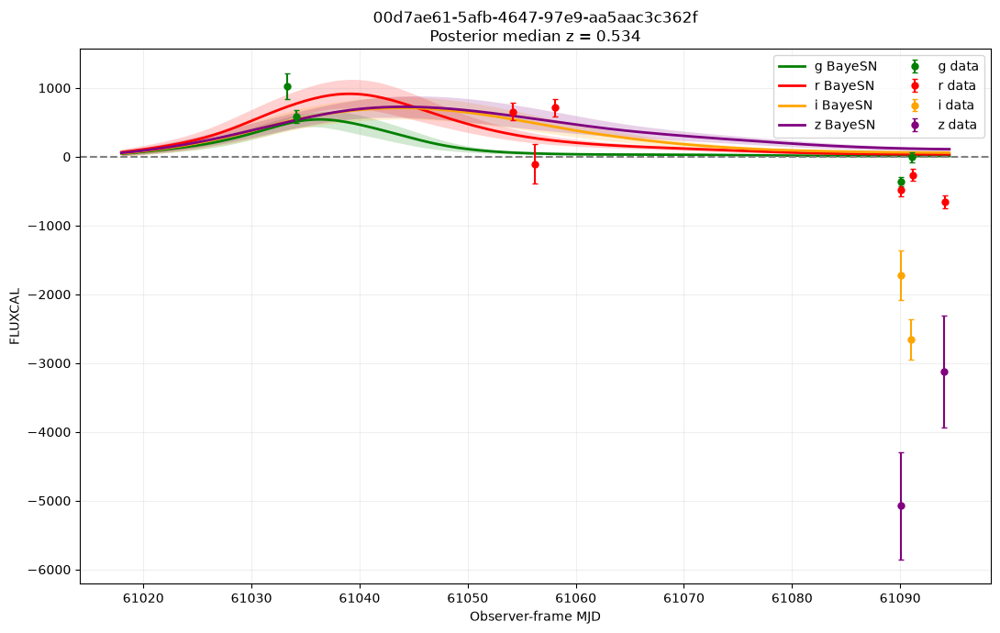

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:04<00:00,  4.18s/it]


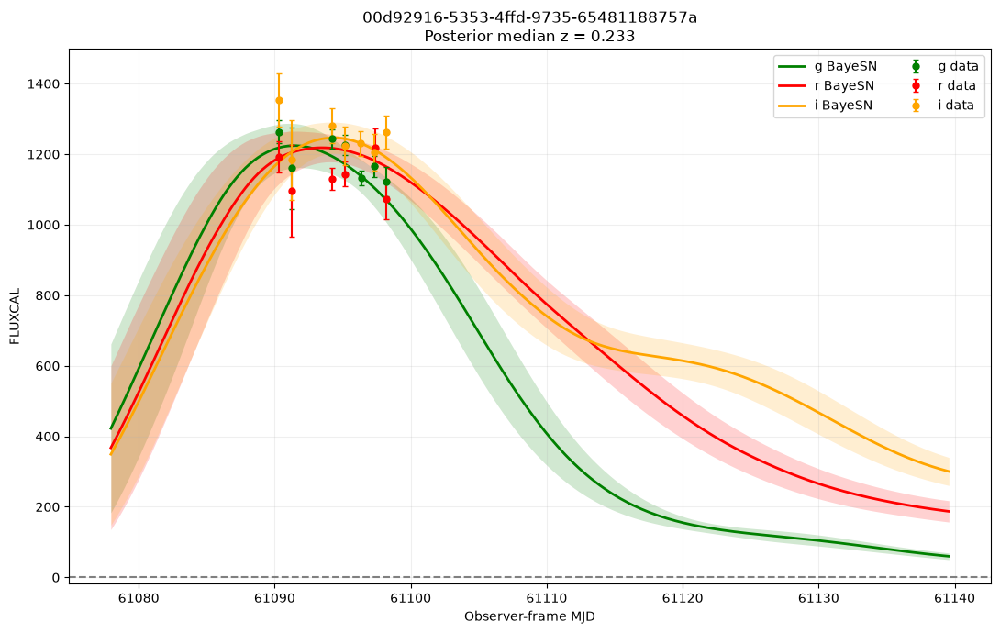

In [39]:
batch_path = Path("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks/fit_results/batch_0005.pkl")

with open(batch_path, "rb") as f:
    batch_0 = pickle.load(f)

print(f"{len(batch_0)} fits in this batch:")
for snid in batch_0:
    print(" ", snid)

for snid, result in batch_0.items():
    plot_fit(snid, result["samples"])

7 fits in this batch:
  00d9ed4e-7b61-4297-8dad-9145f6c14670
  00da947d-ea64-4af1-80cd-0dda14ae28af
  00dd1749-c404-4676-acf4-5217b1009a64
  00dd19ba-43ae-4c02-8e89-34f1d0060a23
  00e0a6b9-e893-41de-be65-9583fd9d34b8
  00e32771-960e-4b13-bdd0-615b89602135
  00e3502d-d319-4669-b6af-e28432f03b74
Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.99s/it]


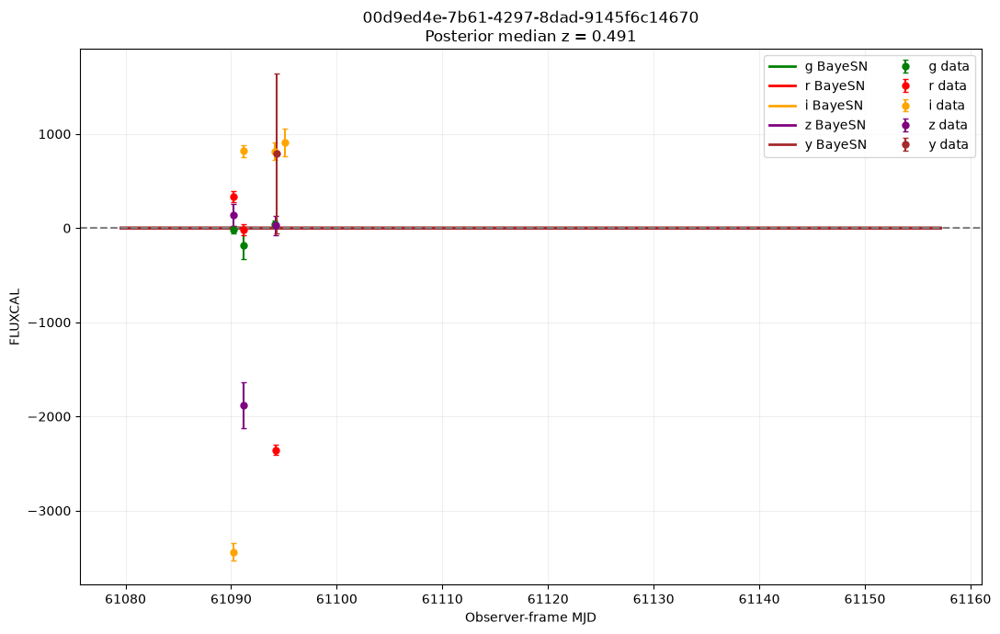

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.61s/it]


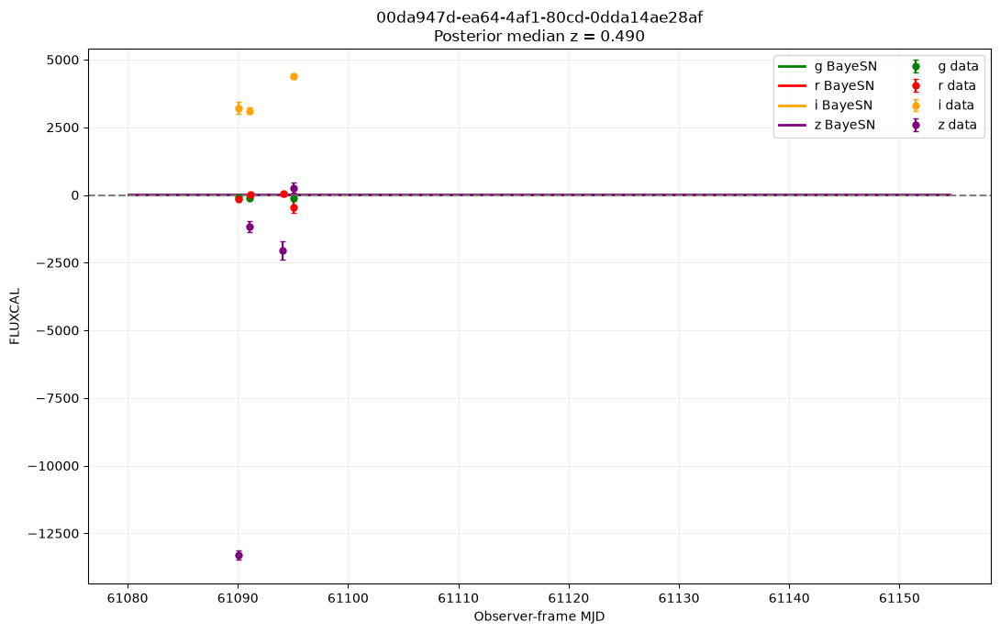

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:10<00:00, 10.25s/it]


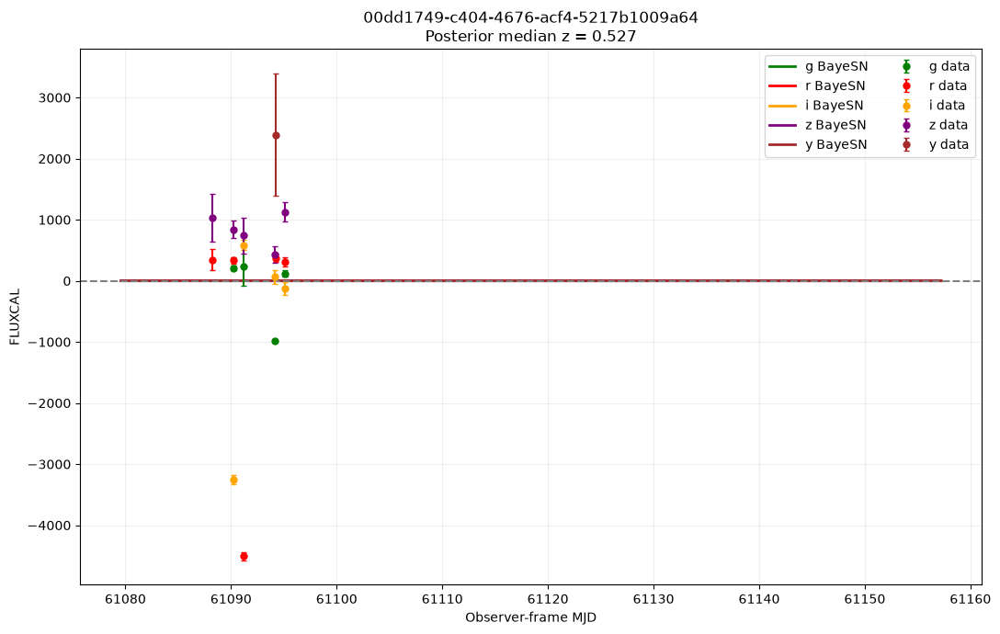

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.12s/it]


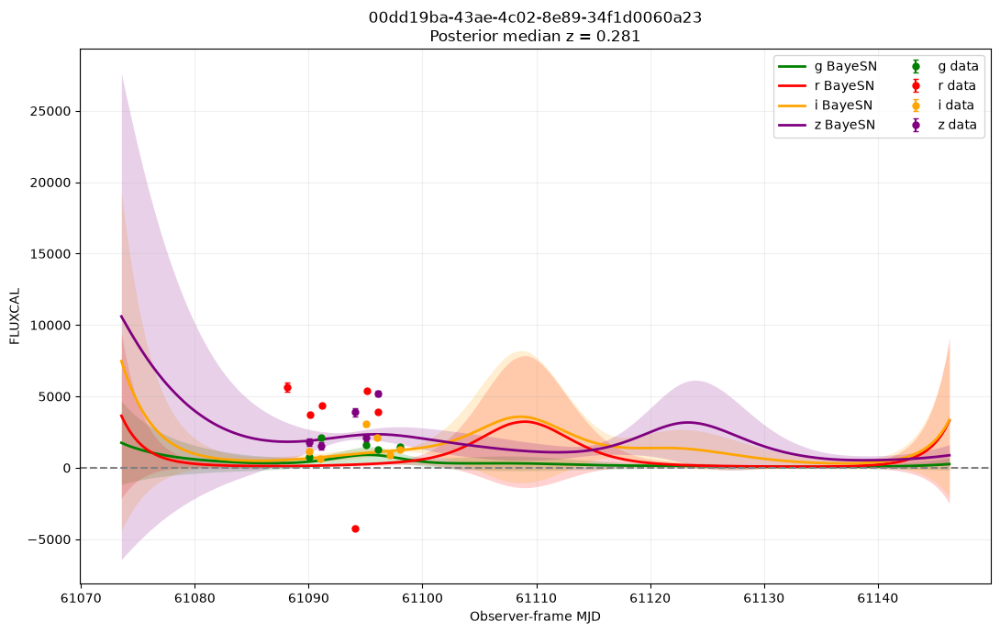

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:10<00:00, 10.73s/it]


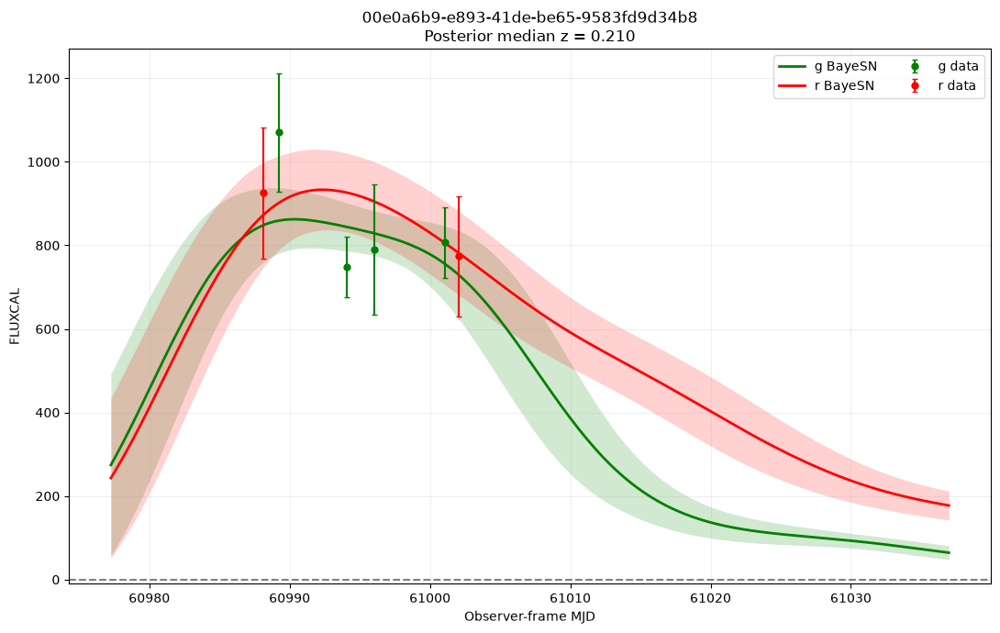

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.80s/it]


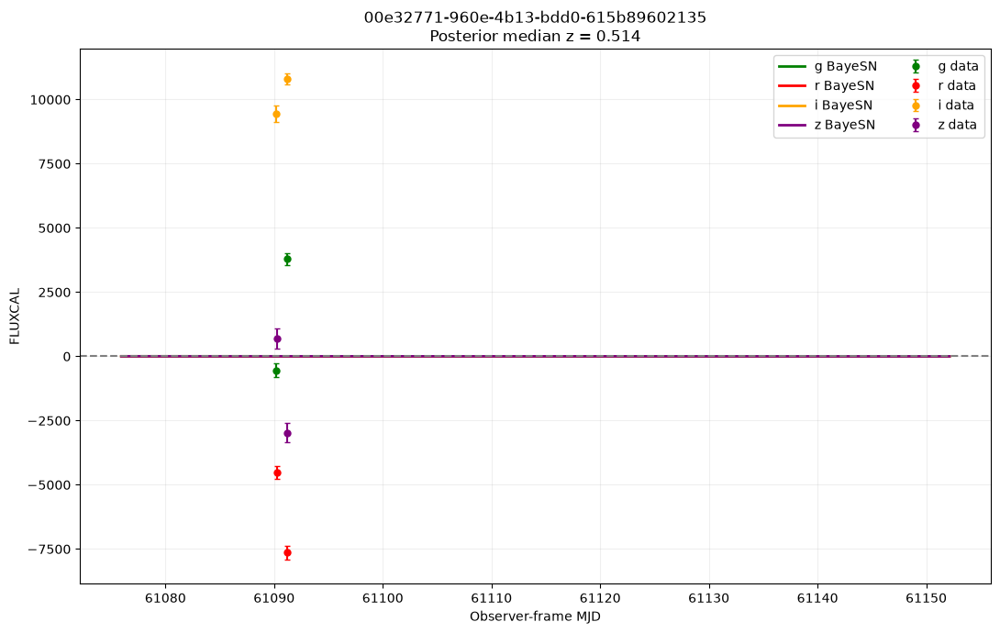

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:10<00:00, 10.40s/it]


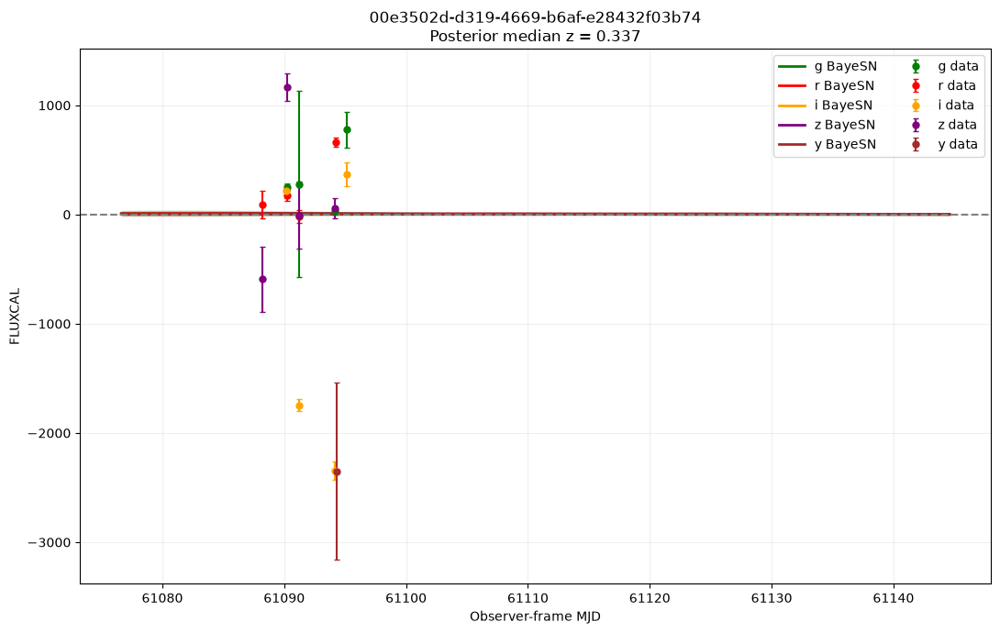

In [37]:
batch_path = Path("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks/fit_results/batch_0006.pkl")

with open(batch_path, "rb") as f:
    batch_0 = pickle.load(f)

print(f"{len(batch_0)} fits in this batch:")
for snid in batch_0:
    print(" ", snid)

for snid, result in batch_0.items():
    plot_fit(snid, result["samples"])

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.59s/it]


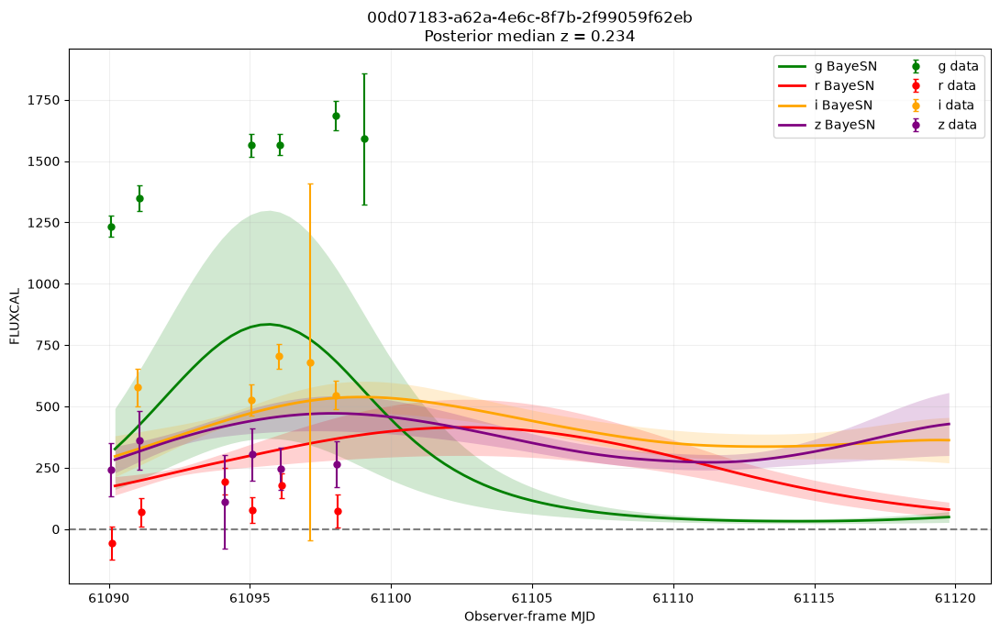

In [41]:
snid = "00d07183-a62a-4e6c-8f7b-2f99059f62eb"
plot_fit(snid, batch_0[snid]["samples"], mjd_min=61090, mjd_max=61120) 


In [42]:
snid = "00d07183-a62a-4e6c-8f7b-2f99059f62eb"
samples = batch_0[snid]["samples"]

z_samples = np.asarray(samples["z"]).reshape(-1)
print("z: median =", np.median(z_samples), " std =", np.std(z_samples), " range =", z_samples.min(), "-", z_samples.max())

# how many total MCMC draws are there?
print("n samples:", z_samples.shape)


z: median = 0.23418902599857114  std = 0.241342846108323  range = 0.19307518025140166 - 0.8279150904208272
n samples: (1000,)


In [43]:
print(list(batch_0.keys()).index(snid))  # position in the dict
print(snid in batch_0)  # sanity check key exists

1
True


6 fits in this batch:
  00e6cf5a-6516-4963-8ab8-a85f6507d124
  00eaced6-3b10-4d5f-804a-4d98cc3c9cbf
  00ec1a2c-b8df-496f-8777-398ffb81a24b
  00f2e3aa-9469-4a25-bbe8-5347b39af723
  00f4d9c6-88c1-4843-a320-b10f6a8f80b3
  00f7187d-5f76-4c3c-9df0-4f1775559e33
Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:10<00:00, 10.46s/it]


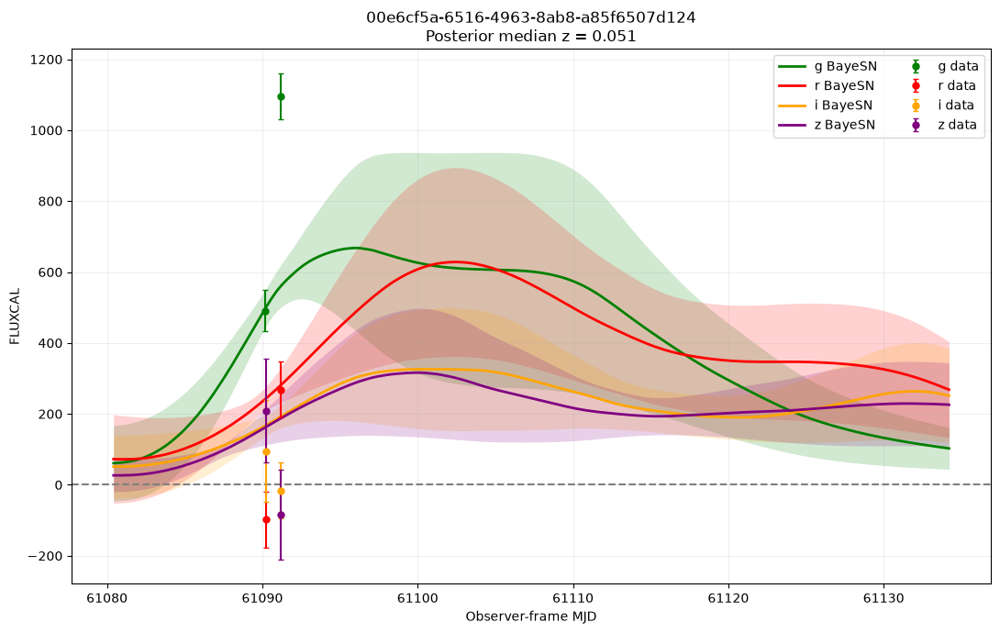

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.22s/it]


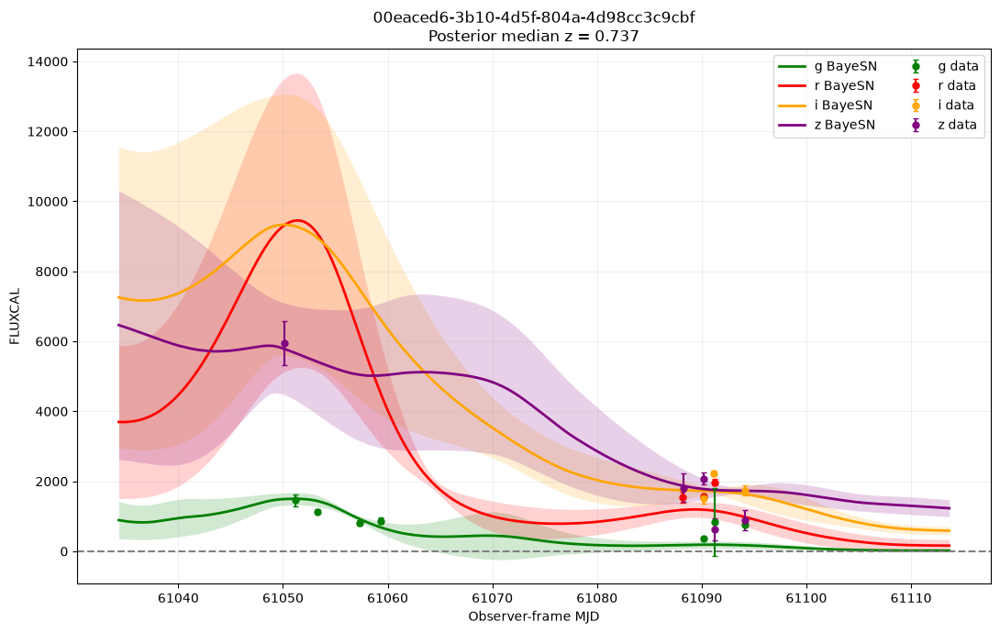

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.94s/it]


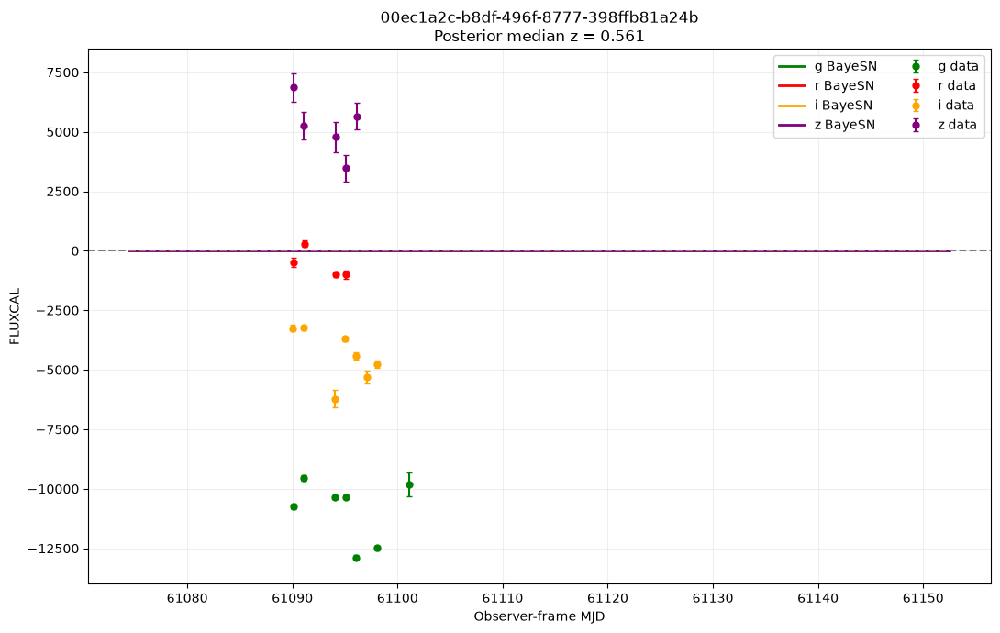

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:04<00:00,  4.96s/it]


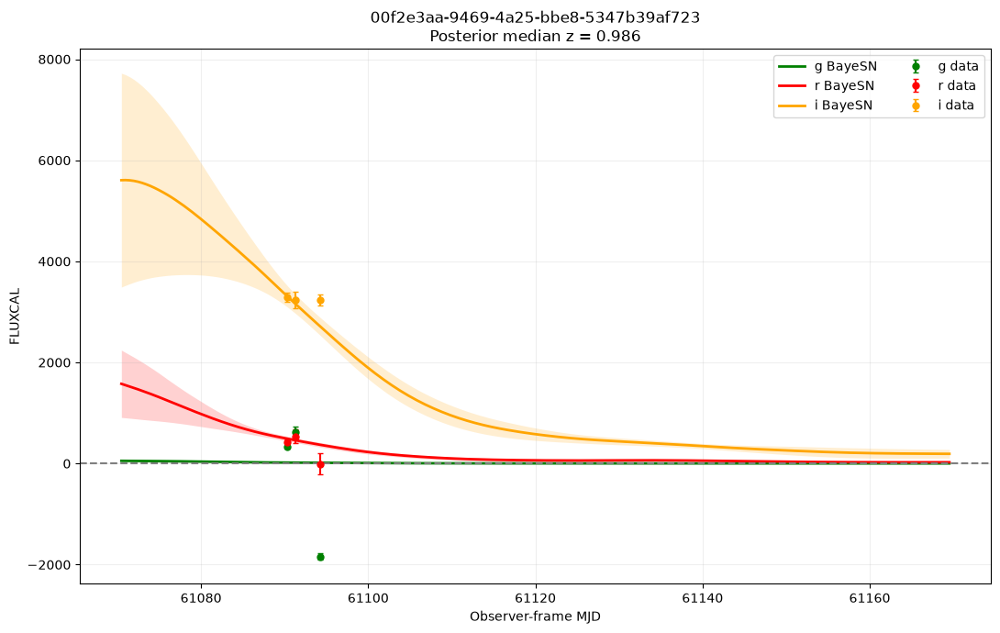

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.07s/it]


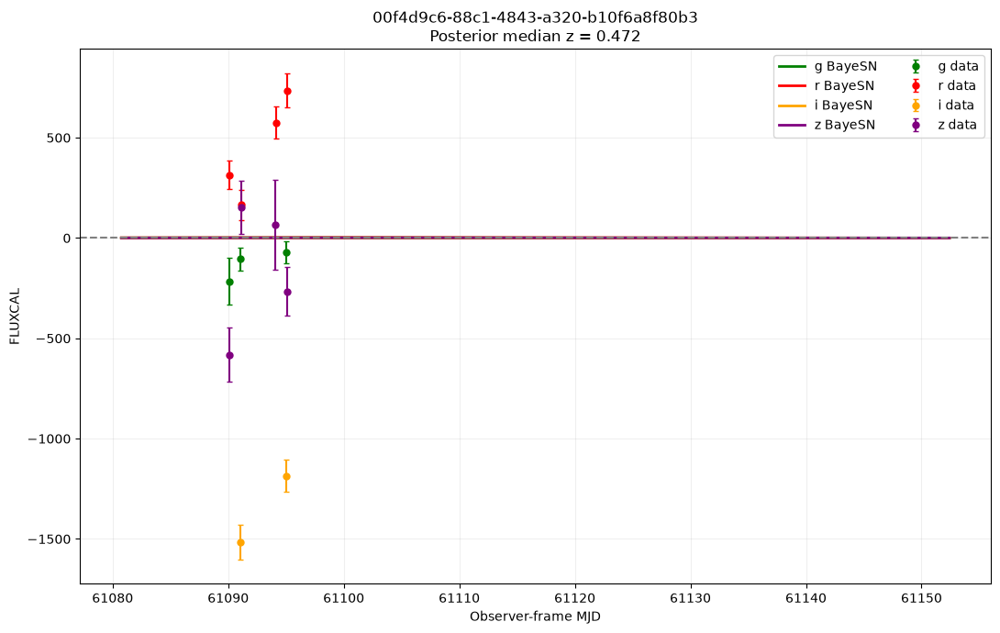

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:08<00:00,  8.15s/it]


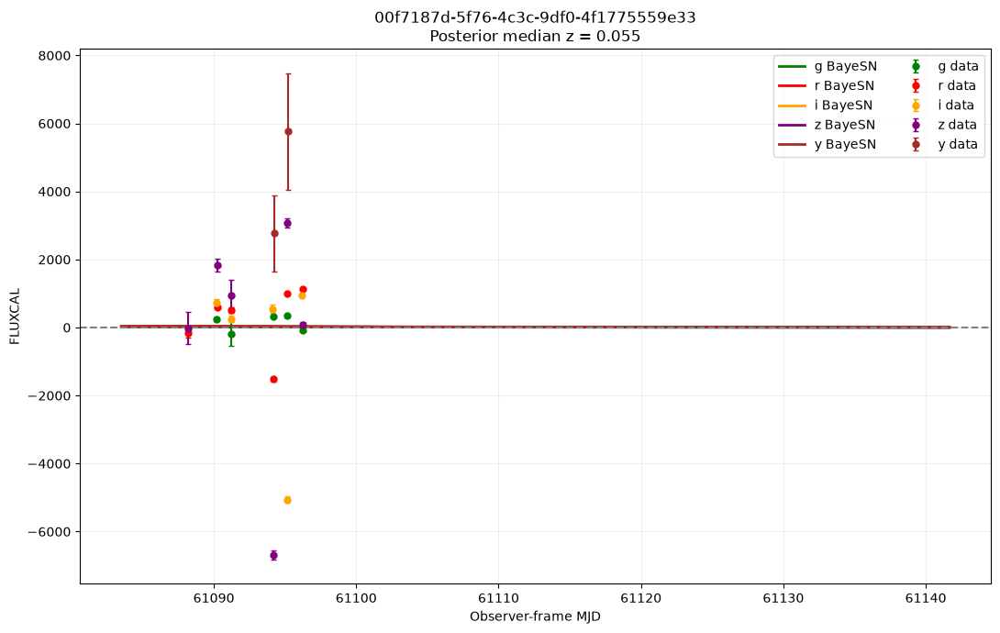

In [56]:
batch_path = Path("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks/fit_results/batch_0007.pkl")

with open(batch_path, "rb") as f:
    batch_0 = pickle.load(f)

print(f"{len(batch_0)} fits in this batch:")
for snid in batch_0:
    print(" ", snid)

for snid, result in batch_0.items():
    plot_fit(snid, result["samples"])

8 fits in this batch:
  00f99dc3-8cf0-4d04-b97e-6a49271f74f9
  00fc25c2-1c23-41c6-bcd8-54636a1f8ff9
  00ff5b2a-1ec5-4450-bdac-b4b92cee2da2
  01021b47-0d85-4d00-ada5-19fa1ee9a2c9
  0102e119-c5c0-472d-8a30-8815e873e7a3
  05917068-b7e7-4171-8773-0bf265e7d823
  05928c78-ec0e-44c3-b16c-61d7678f5300
  0595b387-e46c-4cba-a164-95e2792151af
Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.09s/it]


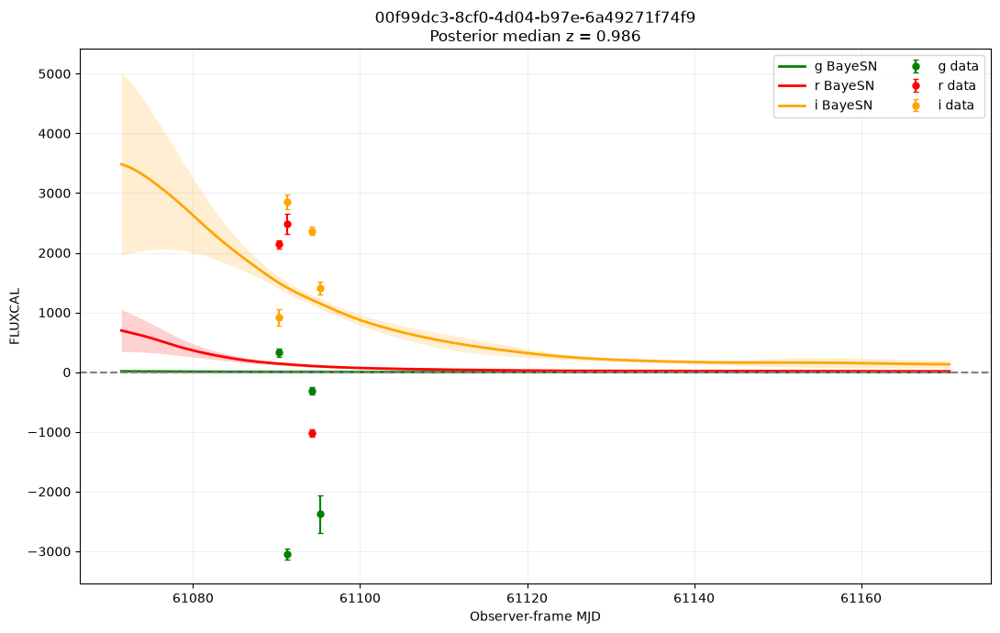

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:04<00:00,  4.59s/it]


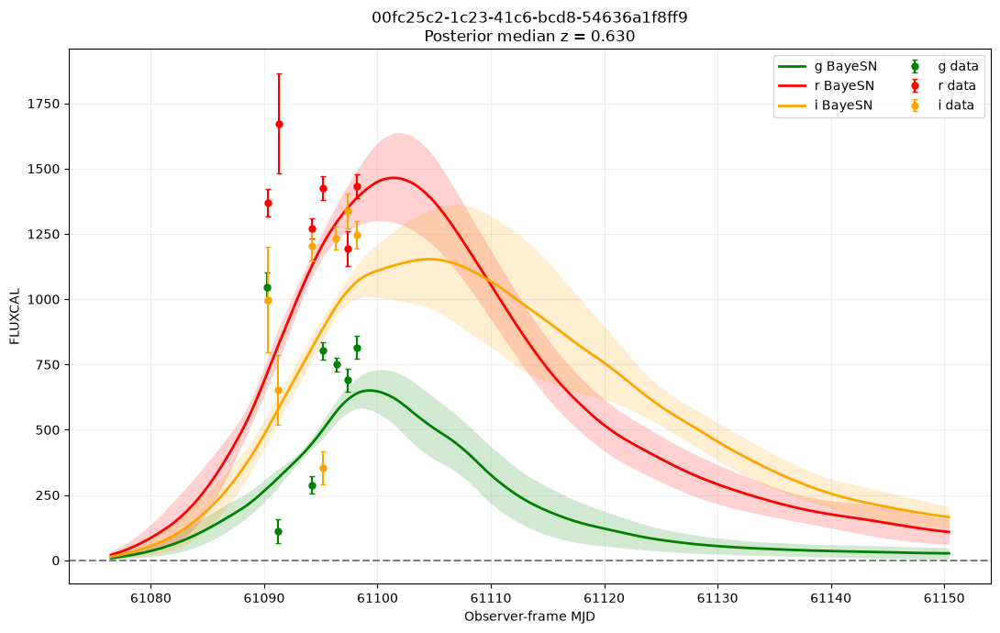

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:08<00:00,  8.16s/it]


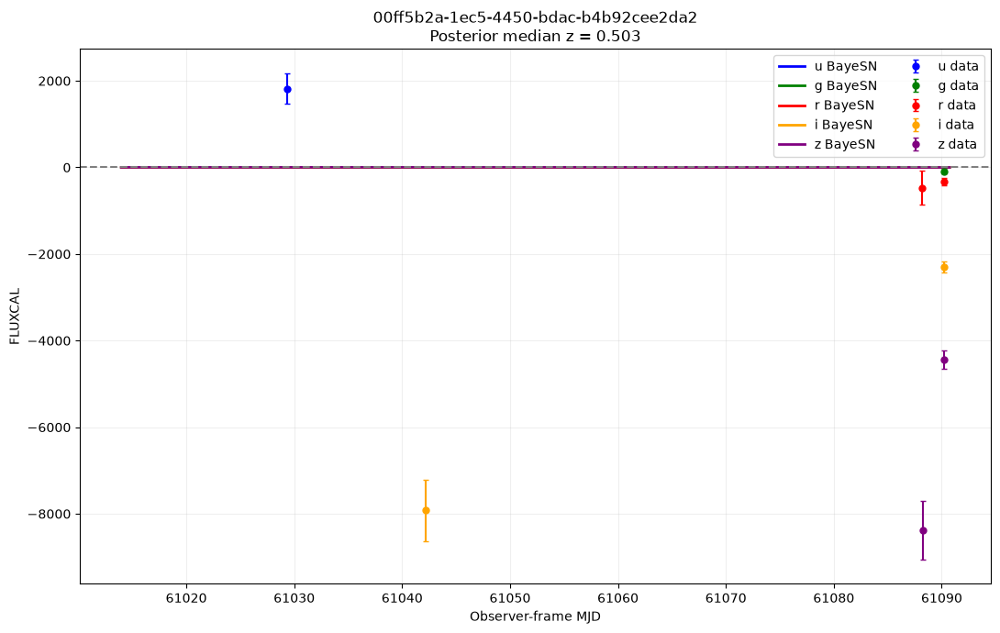

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.33s/it]


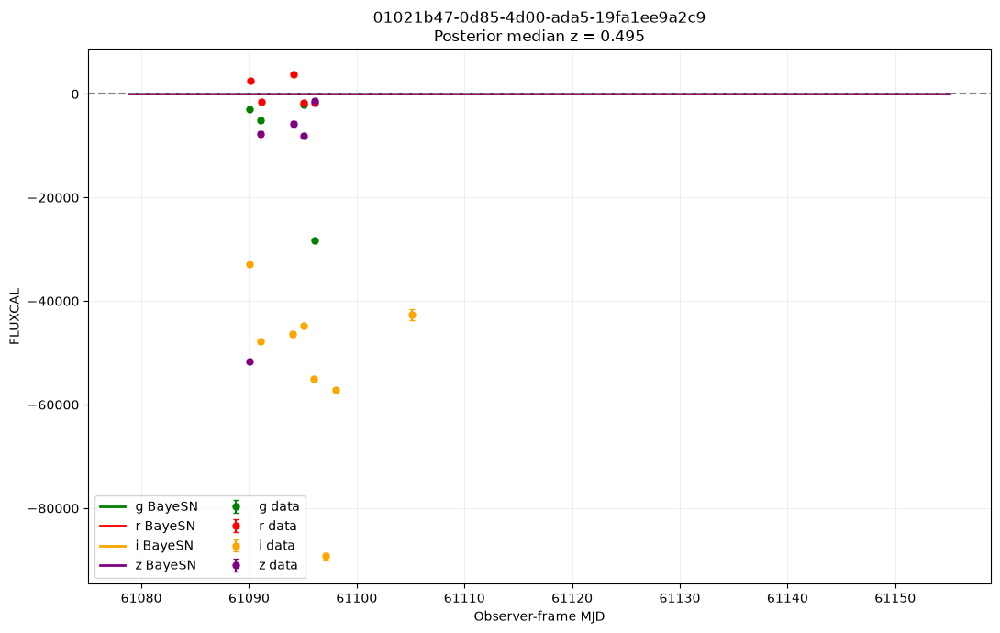

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.24s/it]


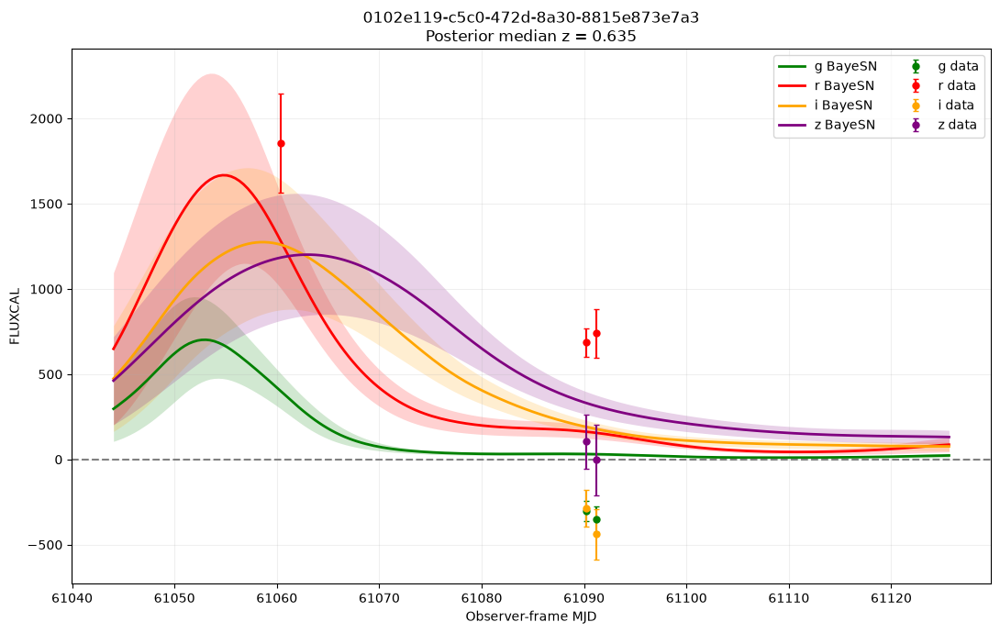

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:04<00:00,  4.72s/it]


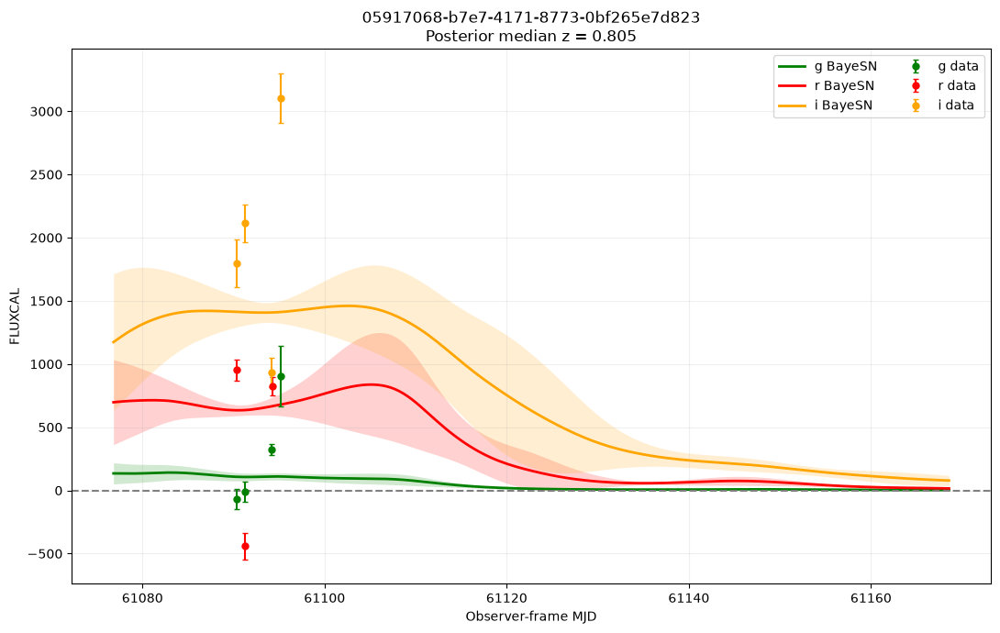

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.29s/it]


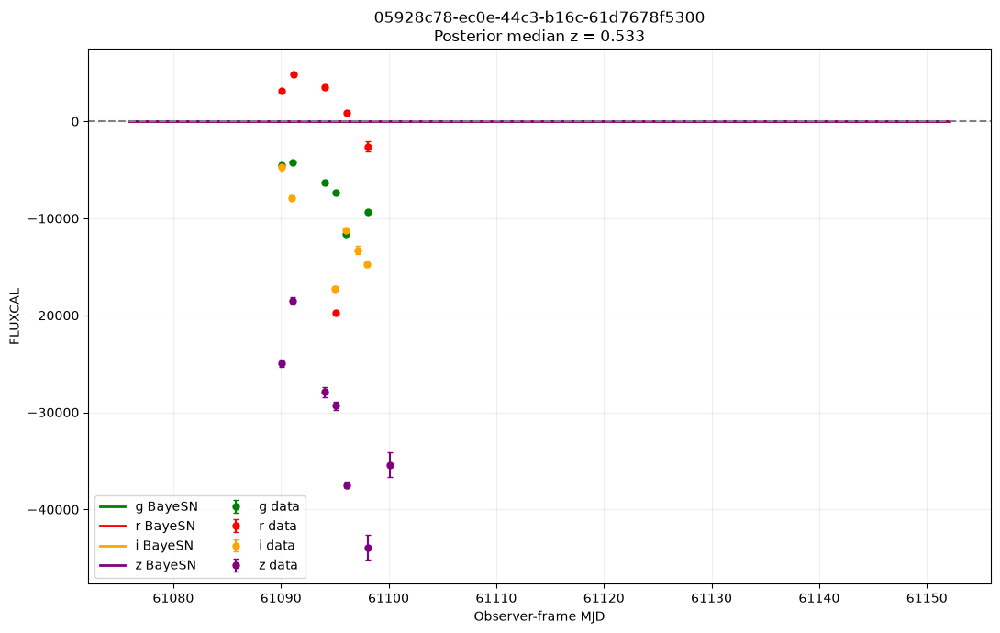

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:08<00:00,  8.01s/it]


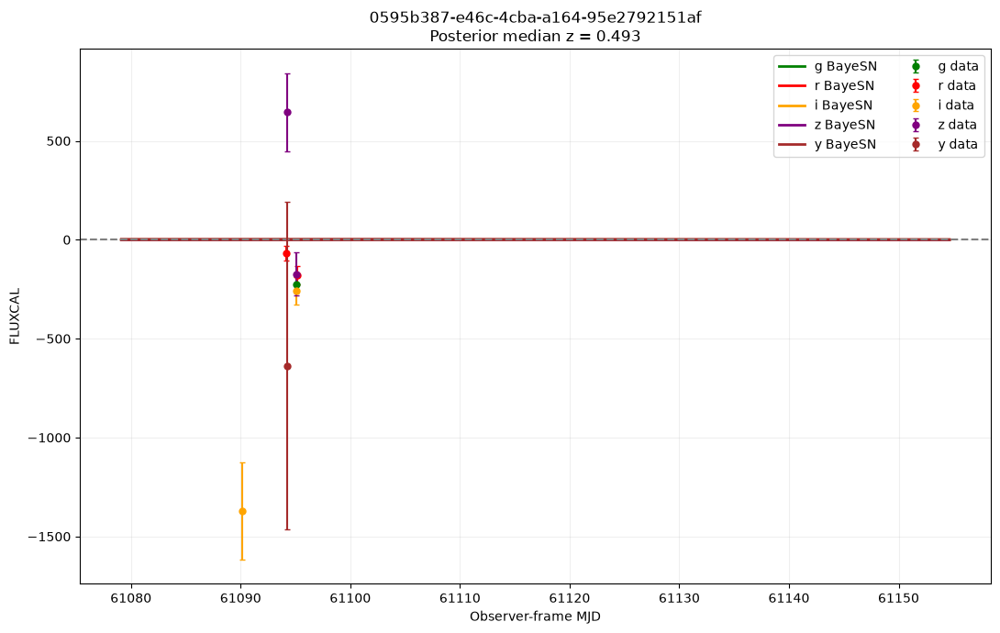

In [57]:
batch_path = Path("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks/fit_results/batch_0008.pkl")

with open(batch_path, "rb") as f:
    batch_0 = pickle.load(f)

print(f"{len(batch_0)} fits in this batch:")
for snid in batch_0:
    print(" ", snid)

for snid, result in batch_0.items():
    plot_fit(snid, result["samples"])

8 fits in this batch:
  00f99dc3-8cf0-4d04-b97e-6a49271f74f9
  00fc25c2-1c23-41c6-bcd8-54636a1f8ff9
  00ff5b2a-1ec5-4450-bdac-b4b92cee2da2
  01021b47-0d85-4d00-ada5-19fa1ee9a2c9
  0102e119-c5c0-472d-8a30-8815e873e7a3
  05917068-b7e7-4171-8773-0bf265e7d823
  05928c78-ec0e-44c3-b16c-61d7678f5300
  0595b387-e46c-4cba-a164-95e2792151af
Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.31s/it]


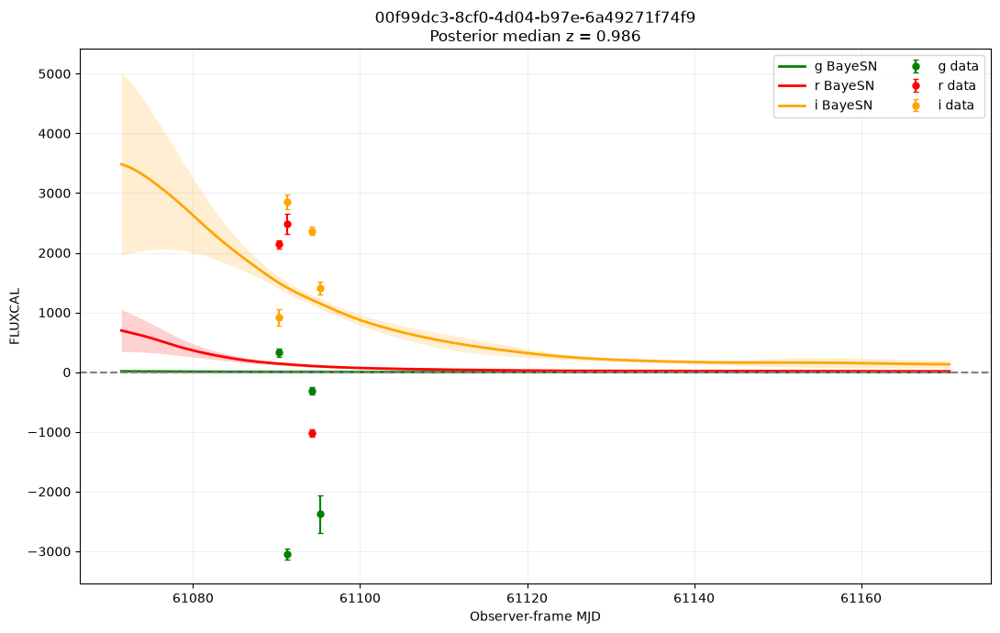

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.05s/it]


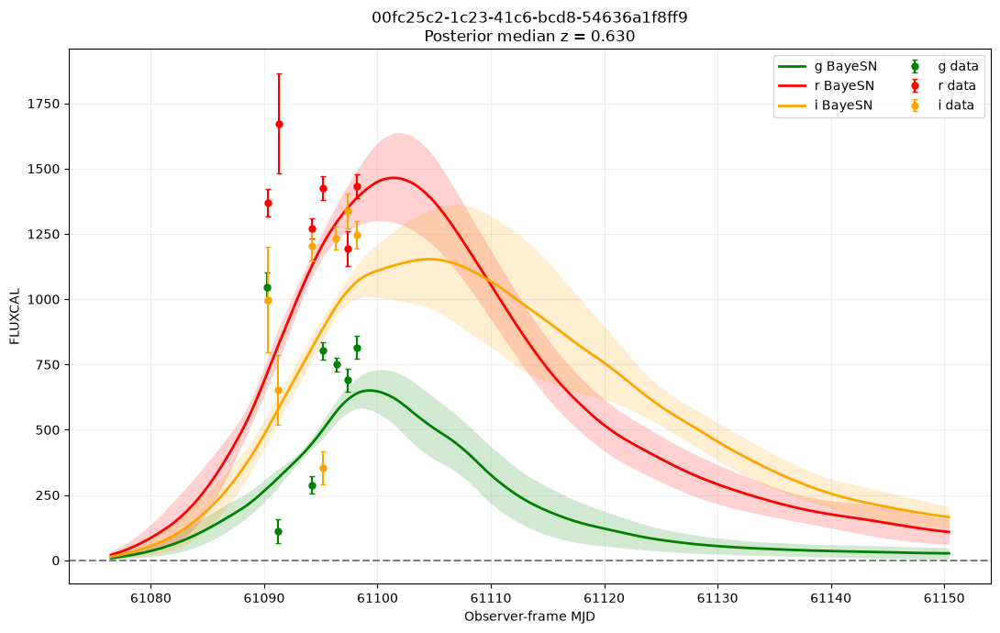

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:11<00:00, 11.64s/it]


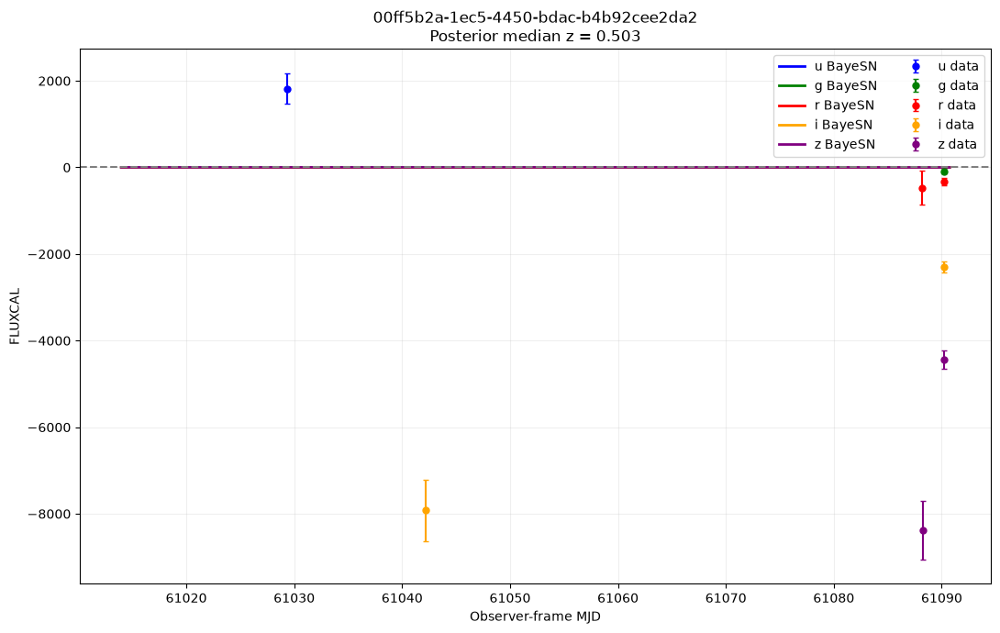

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.96s/it]


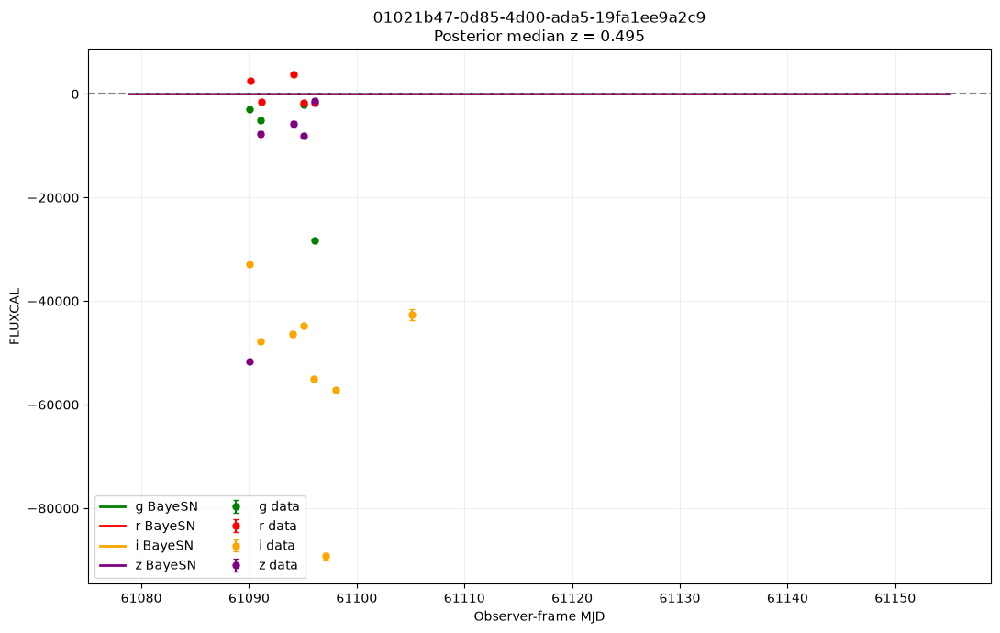

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.64s/it]


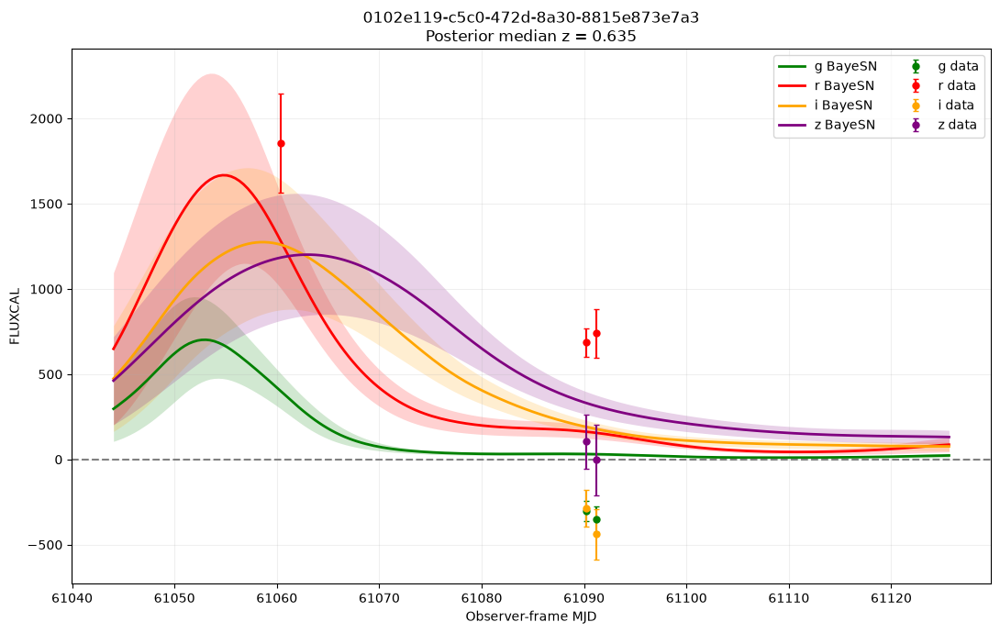

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.34s/it]


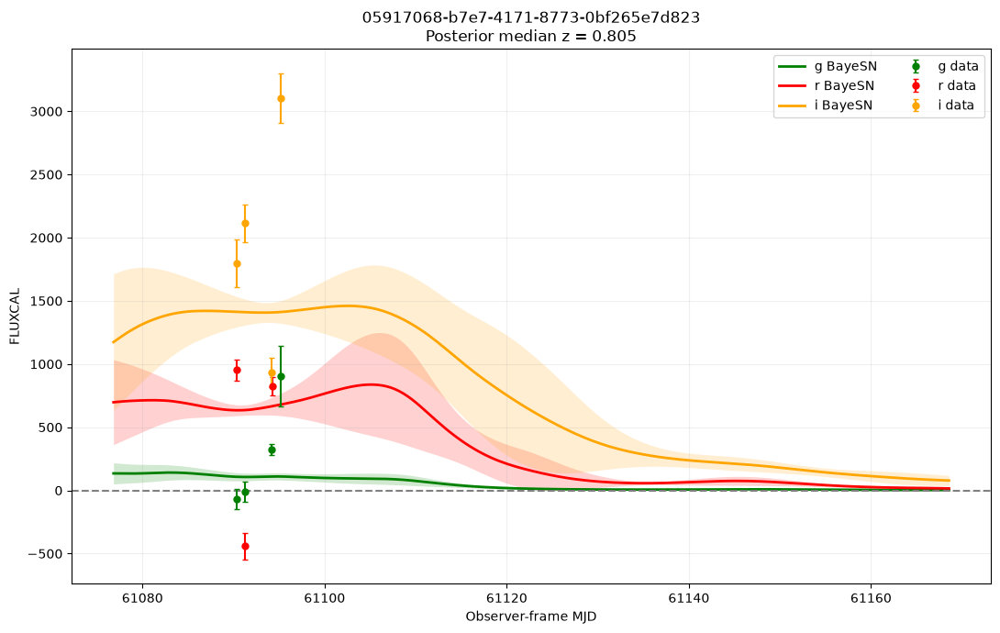

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.63s/it]


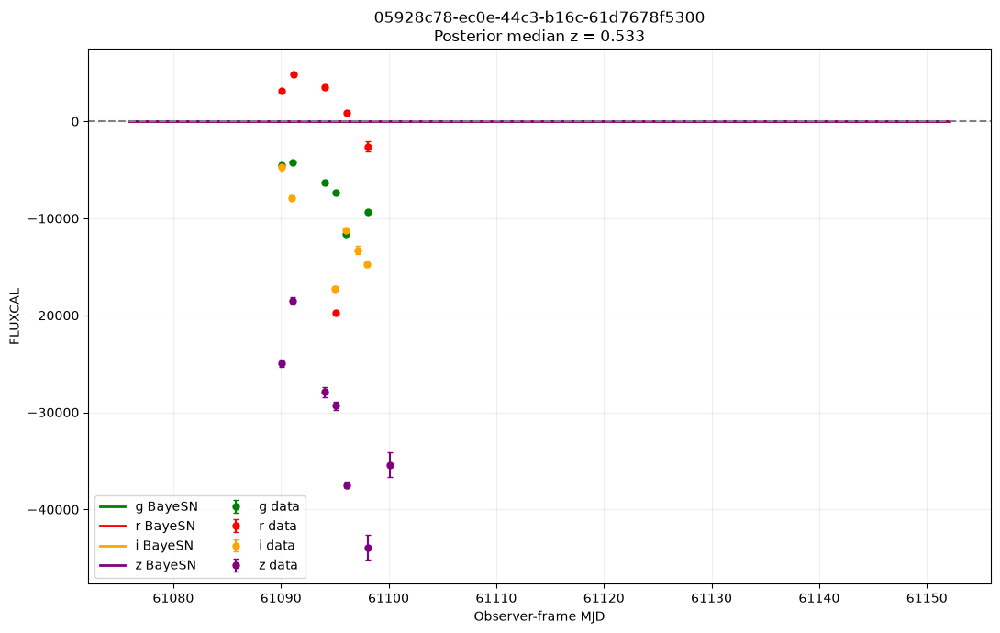

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:08<00:00,  8.28s/it]


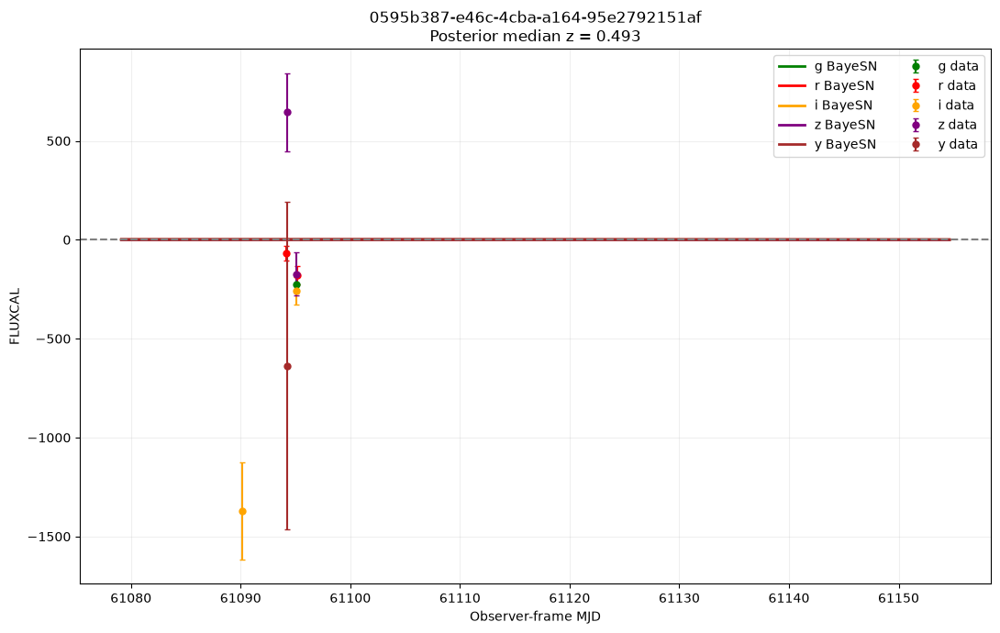

In [58]:
batch_path = Path("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks/fit_results/batch_0008.pkl")

with open(batch_path, "rb") as f:
    batch_0 = pickle.load(f)

print(f"{len(batch_0)} fits in this batch:")
for snid in batch_0:
    print(" ", snid)

for snid, result in batch_0.items():
    plot_fit(snid, result["samples"])

9 fits in this batch:
  059690db-9f0b-4548-99fa-60bf5937d10b
  0597c9de-991f-4b09-bccd-bc4c0f254978
  059848ab-aef2-46fc-9808-864a1d863719
  059a085a-23a8-4b6a-914f-222c77a73546
  059b31ca-b4cf-40a9-9655-16fd159622a0
  059b58e0-f720-41d5-8068-547c9bb4ea0d
  059bcf64-d8b3-4b99-9a99-2d93a0496a15
  059e0035-495f-4b39-915b-5aa6bf5ec6ec
  05a04867-5f97-486c-997c-2cb630862006
Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:08<00:00,  8.53s/it]


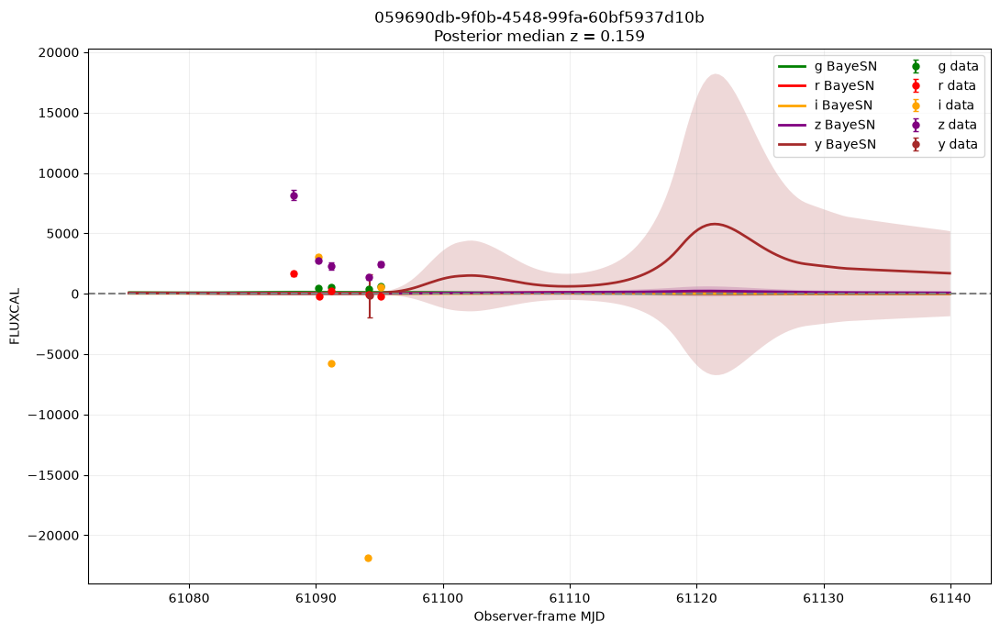

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.39s/it]


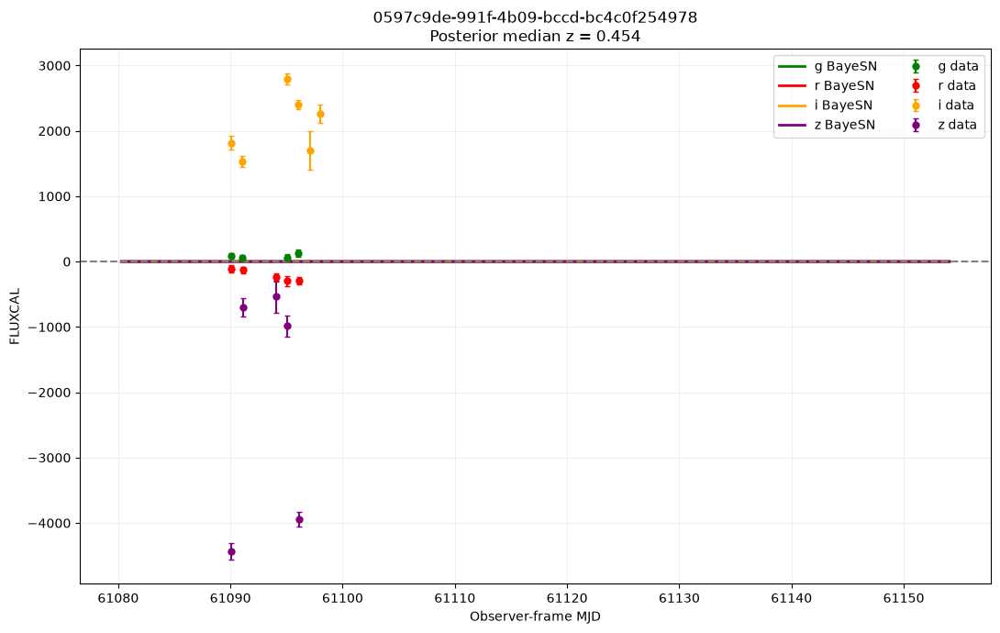

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:04<00:00,  4.73s/it]


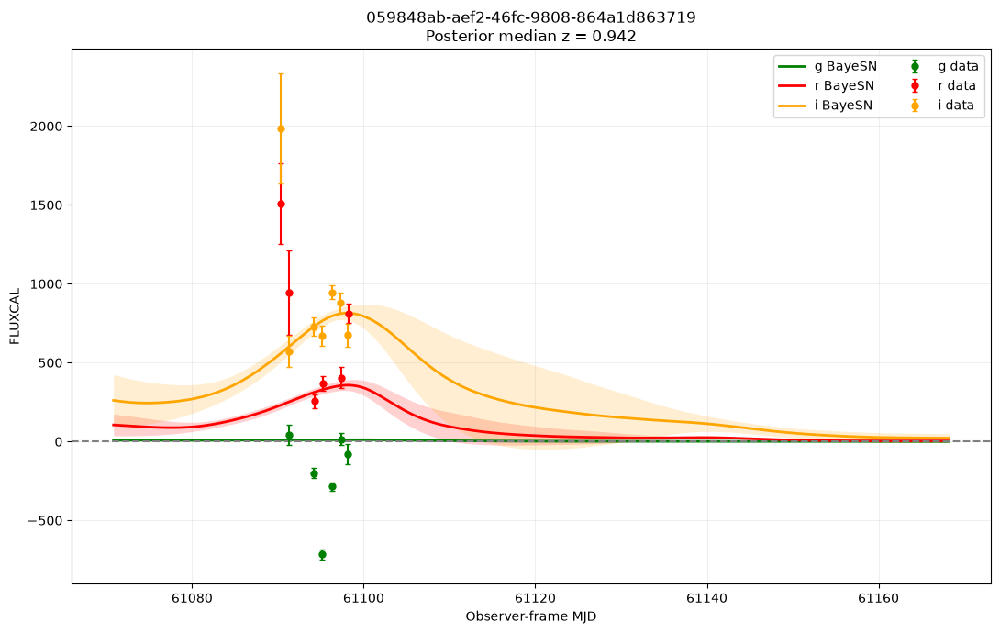

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.32s/it]


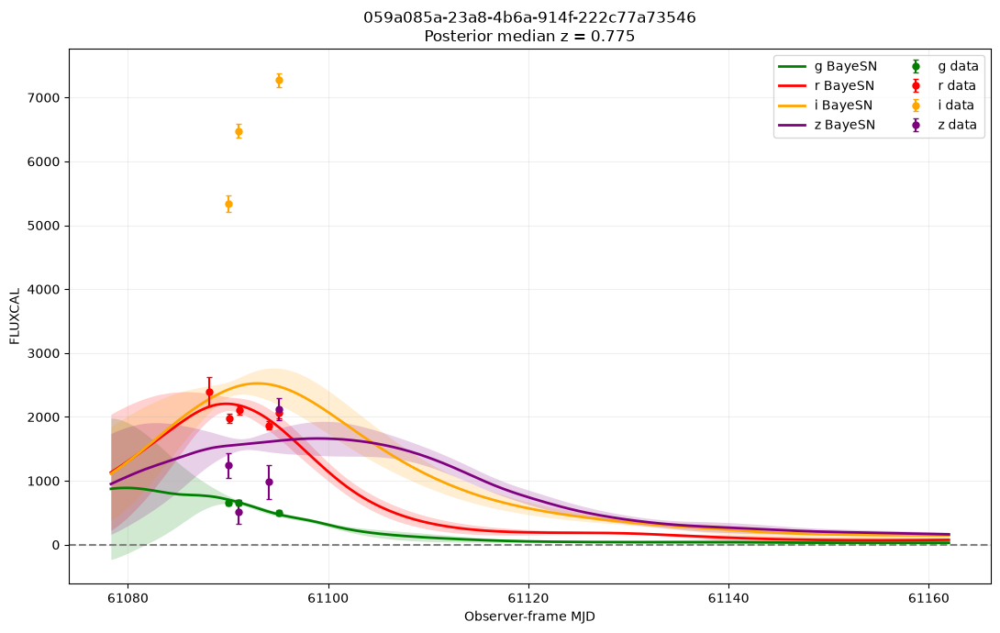

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.46s/it]


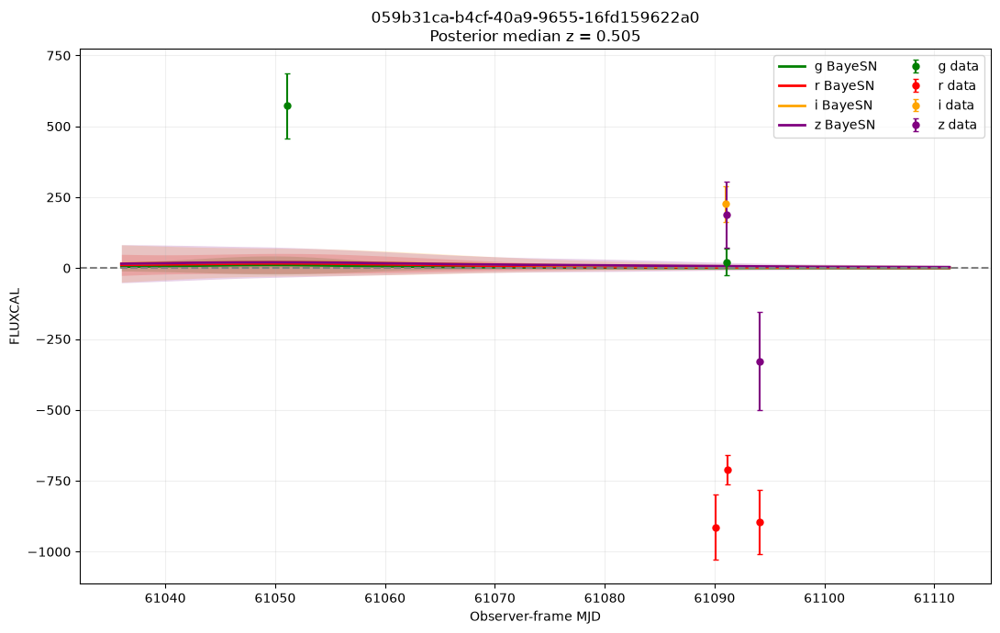

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.33s/it]


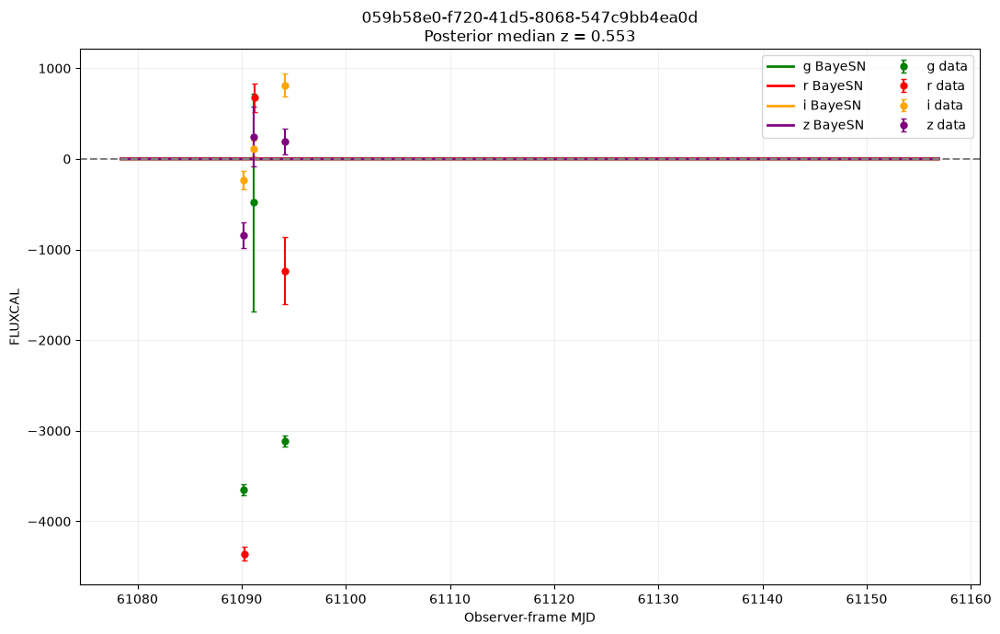

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.20s/it]


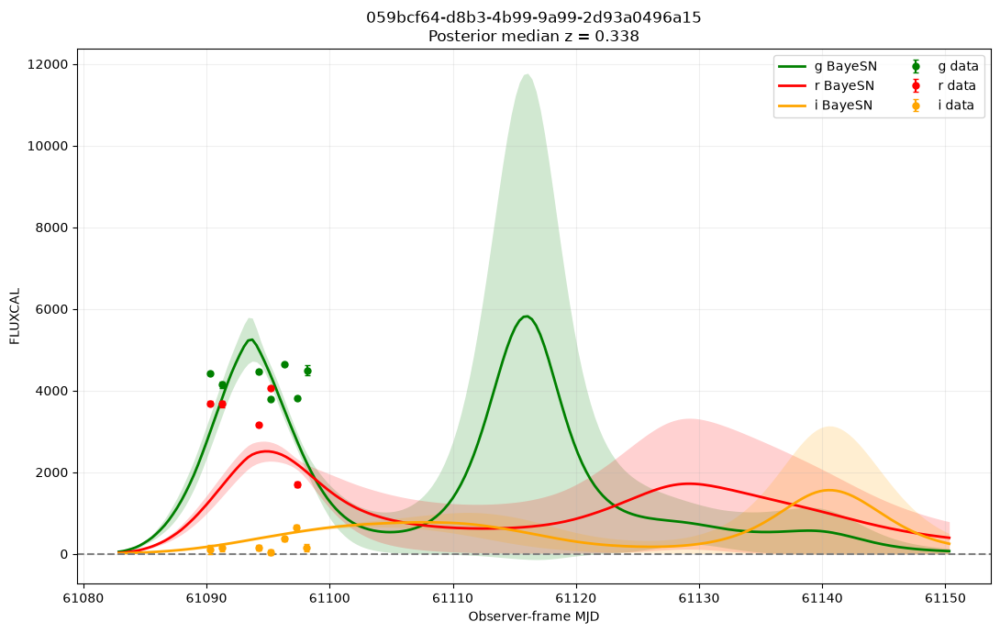

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.77s/it]


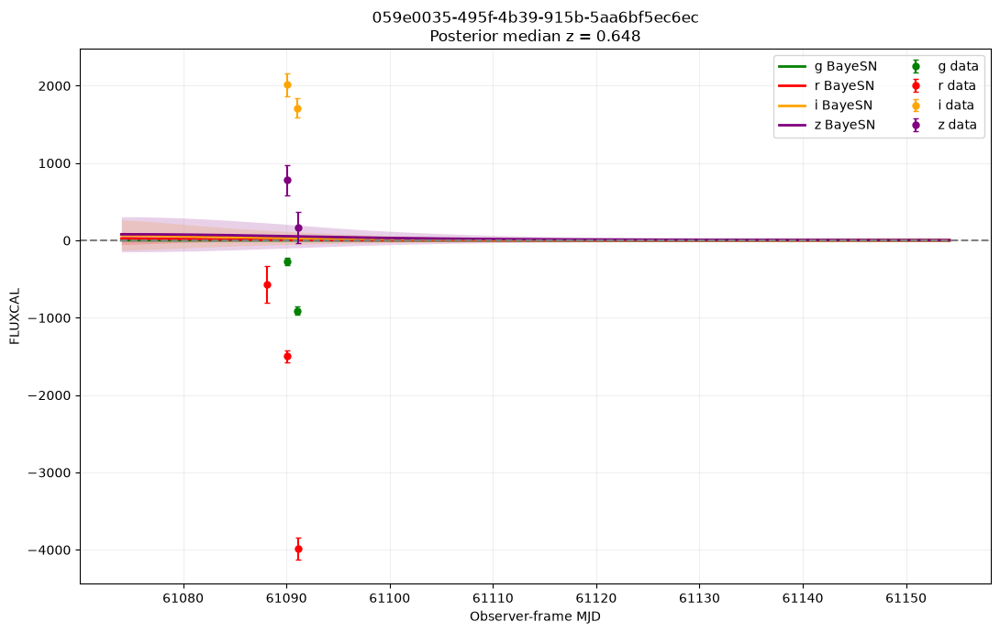

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:08<00:00,  8.37s/it]


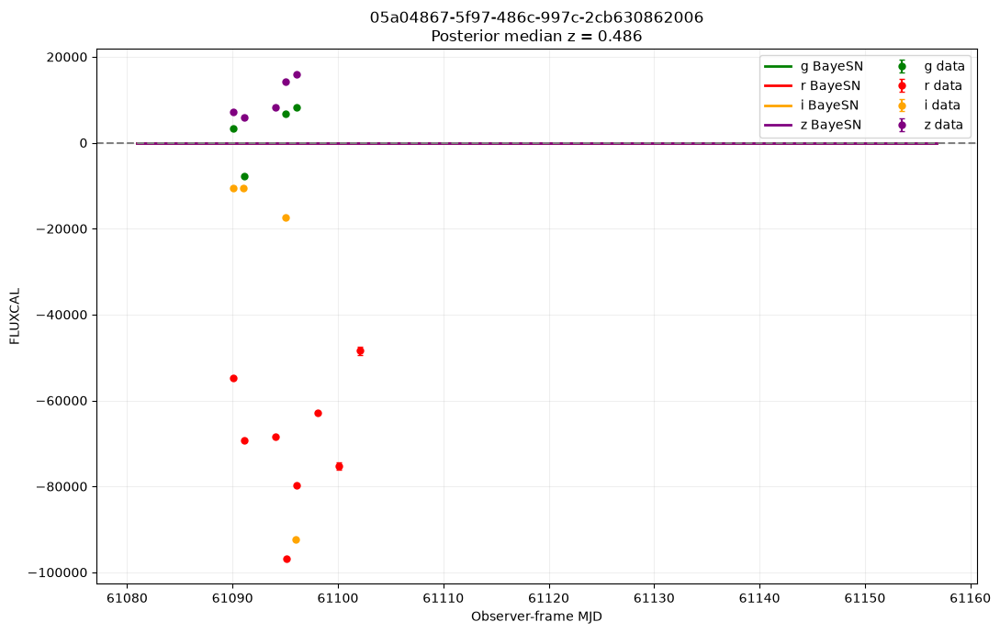

In [59]:
batch_path = Path("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks/fit_results/batch_0009.pkl")

with open(batch_path, "rb") as f:
    batch_0 = pickle.load(f)

print(f"{len(batch_0)} fits in this batch:")
for snid in batch_0:
    print(" ", snid)

for snid, result in batch_0.items():
    plot_fit(snid, result["samples"])

9 fits in this batch:
  05a53a48-1b73-488e-8eaf-20d43cd50f2c
  05a5c470-02c5-486b-9a53-21bc5555e846
  05a6caad-4582-40aa-99a4-31059bbc074e
  05a7c736-6076-48ef-af5e-e8e1ada0f431
  05a87b65-d02e-415b-a9fa-260dc88a3615
  05aa3254-bdb2-4c6f-9771-3fa91f5d448a
  05ab1d19-a56b-4e6d-93ed-9856c83ce45f
  05accd4a-fdc1-4de6-b397-905ed69ef7bd
  05aef011-76a8-4d2f-b067-fd429888b60c
Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:08<00:00,  8.35s/it]


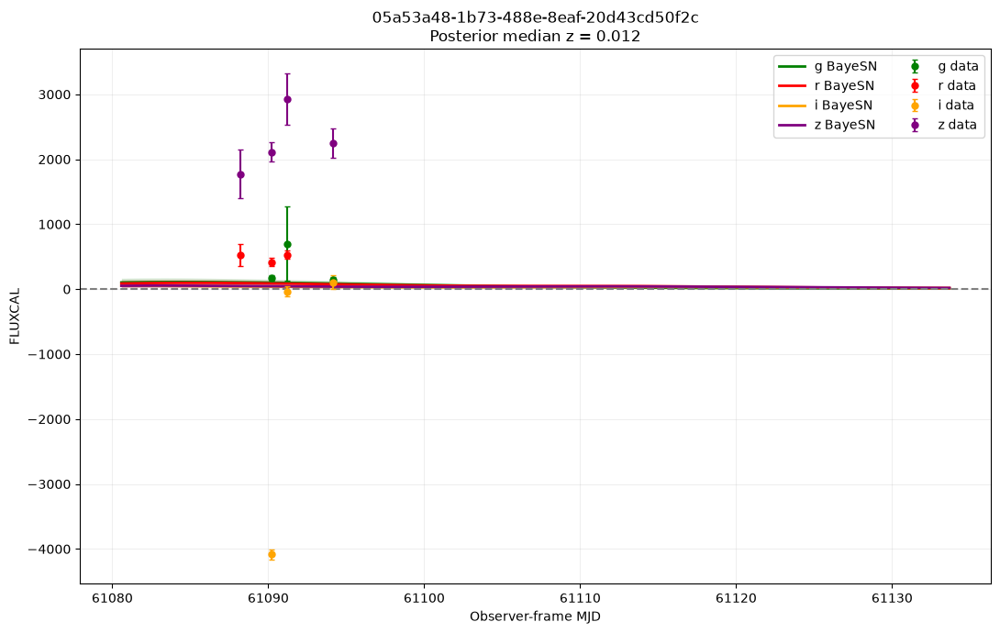

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.28s/it]


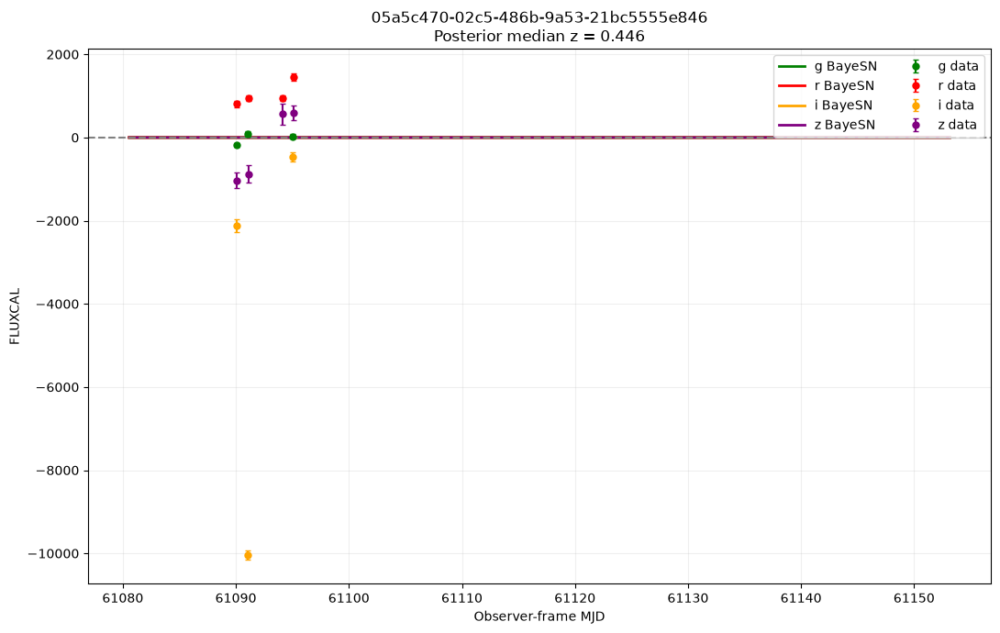

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:08<00:00,  8.12s/it]


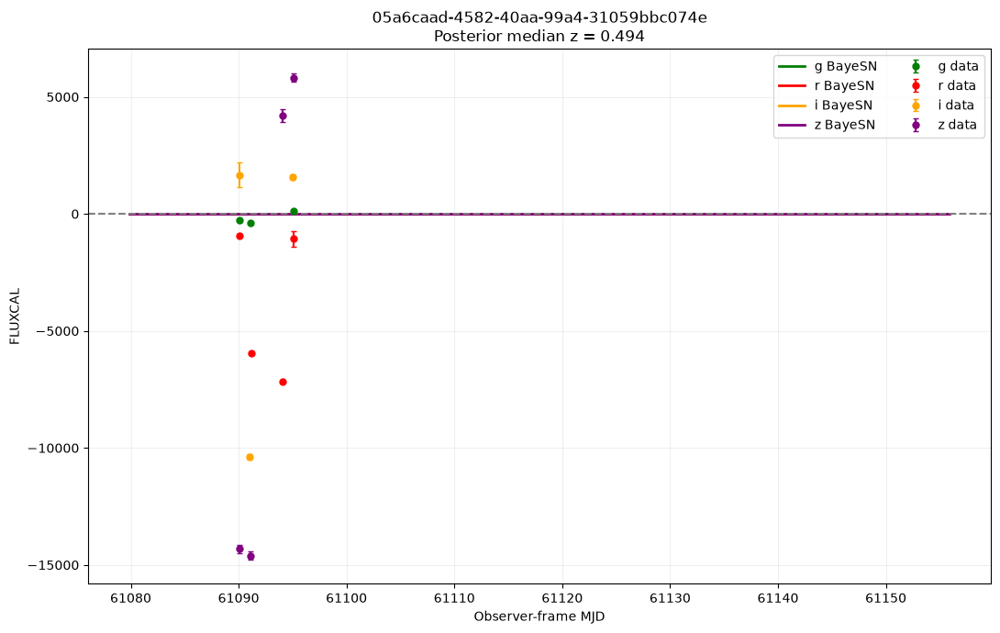

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.14s/it]


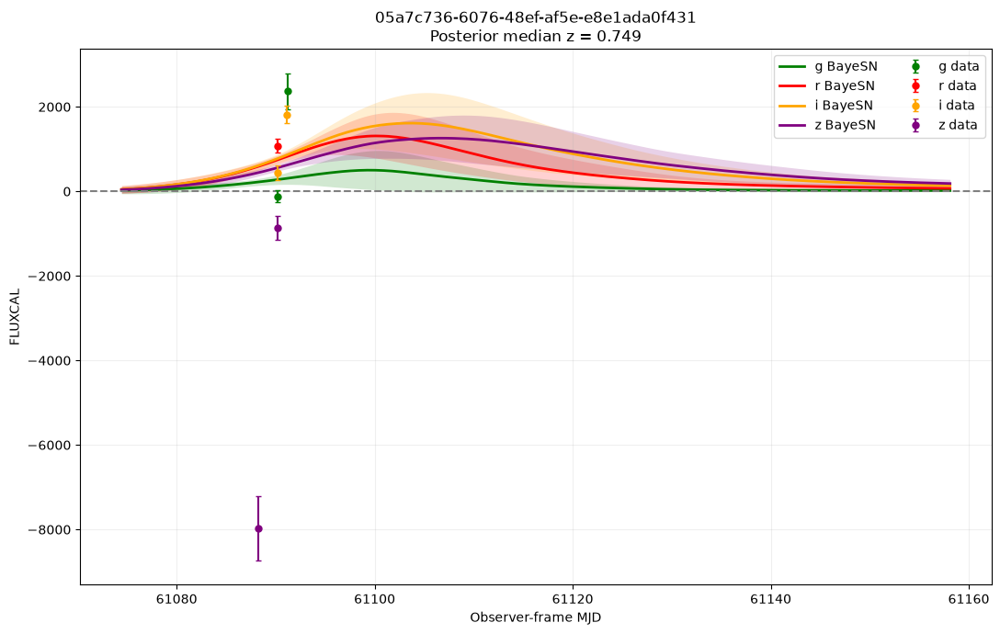

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.14s/it]


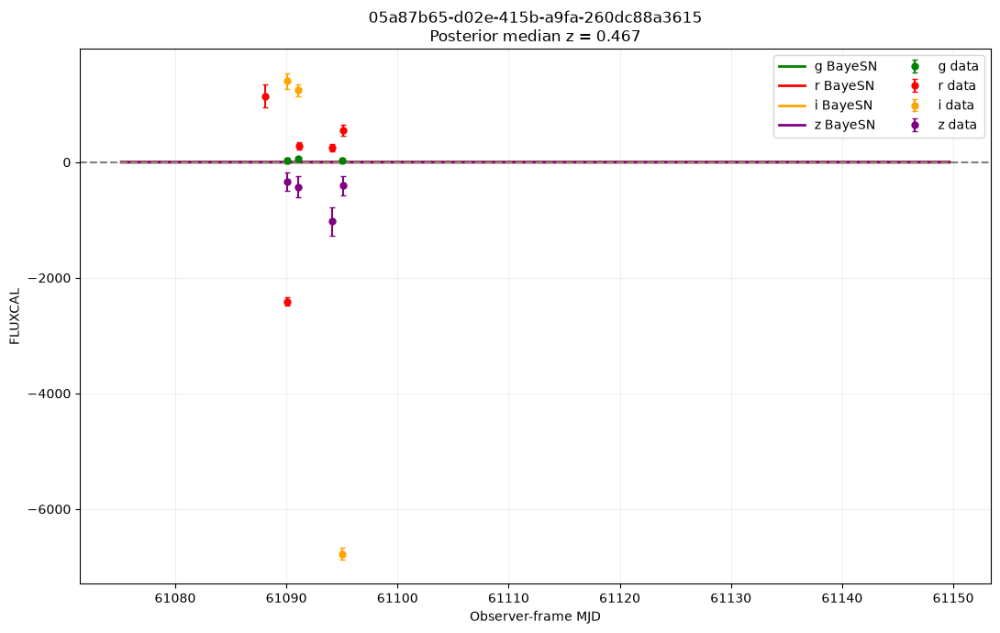

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.46s/it]


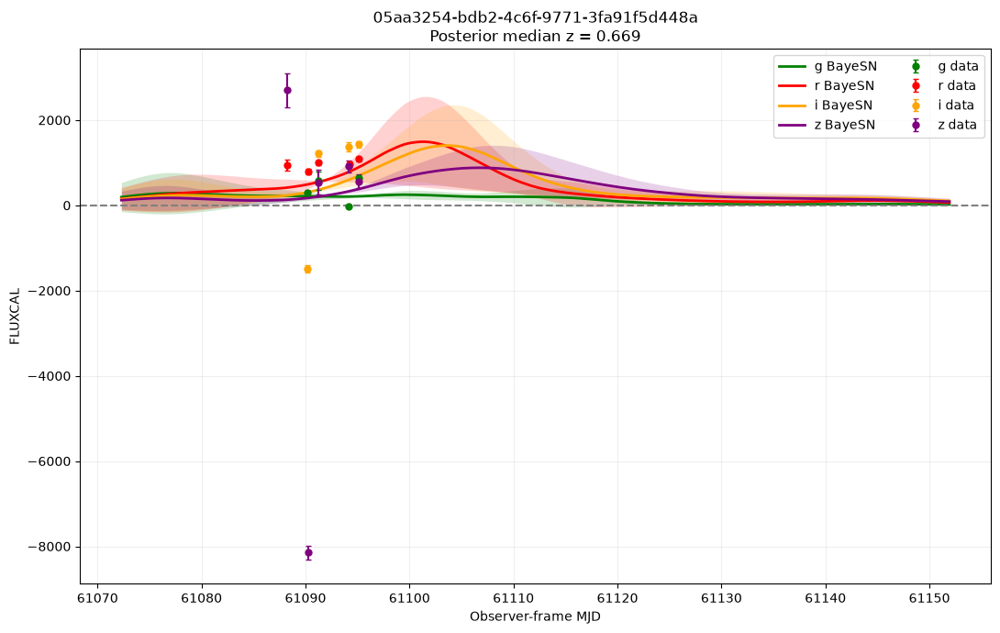

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:03<00:00,  3.95s/it]


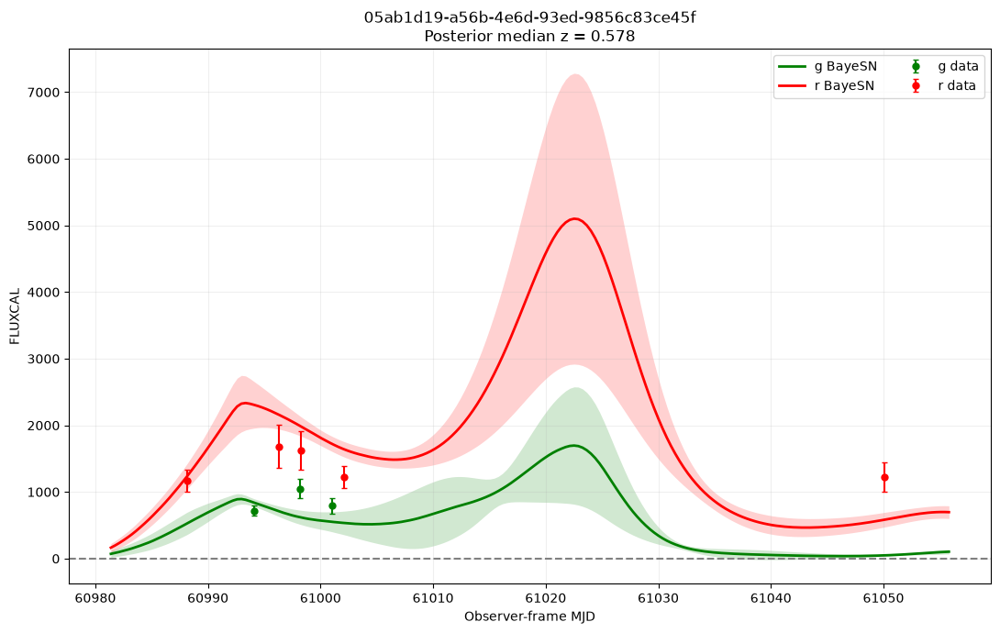

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.83s/it]


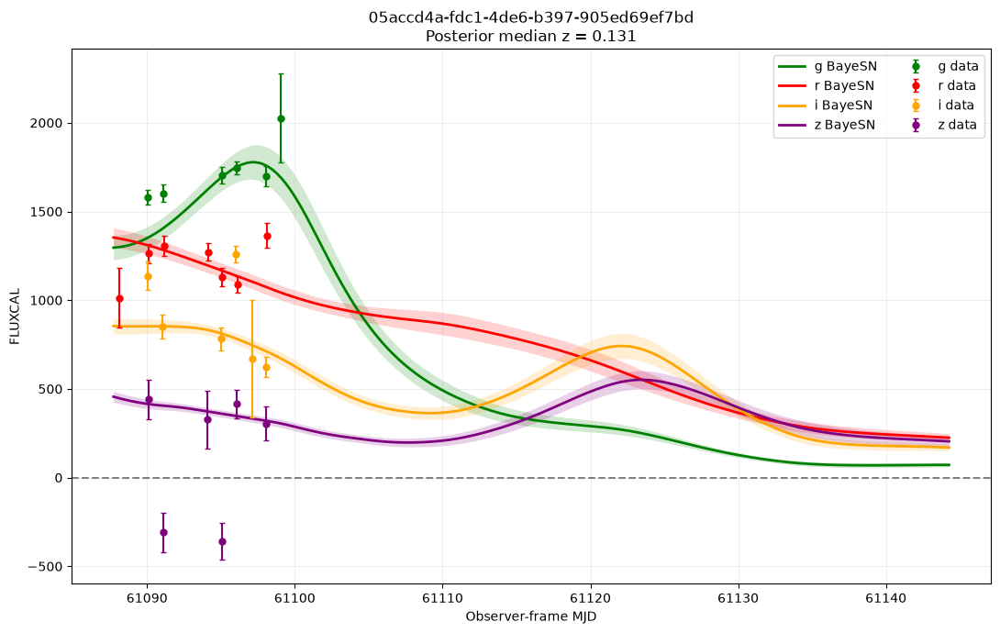

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:08<00:00,  8.59s/it]


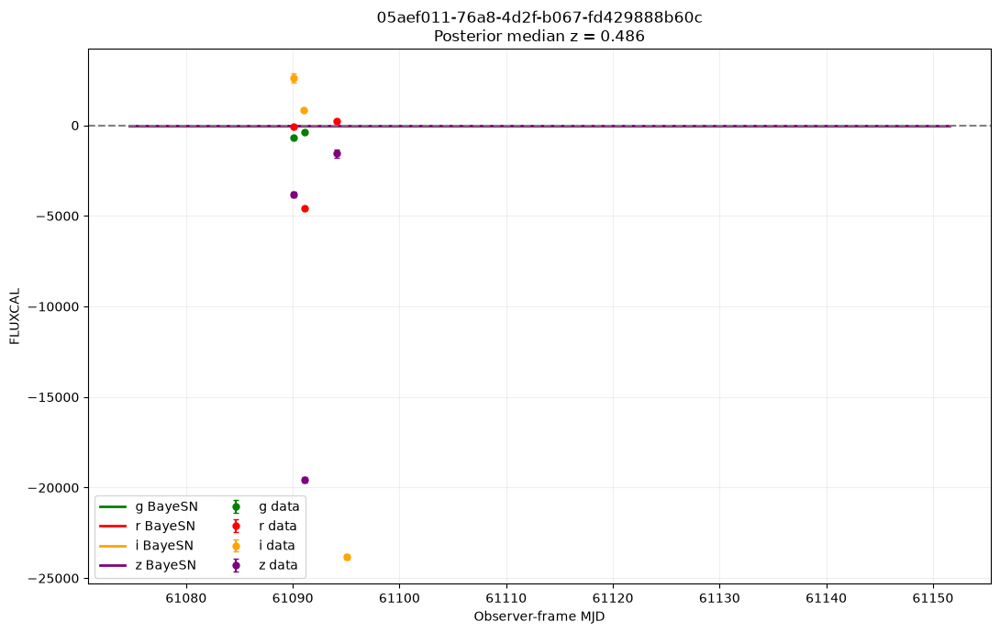

In [64]:
batch_path = Path("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks/fit_results/batch_0010.pkl")

with open(batch_path, "rb") as f:
    batch_0 = pickle.load(f)

print(f"{len(batch_0)} fits in this batch:")
for snid in batch_0:
    print(" ", snid)

for snid, result in batch_0.items():
    plot_fit(snid, result["samples"])

6 fits in this batch:
  05b531dd-8410-47b1-aff4-4ab393a7868b
  05b54352-c068-4789-aff2-f7ff55d54bb1
  05b7be3d-8714-4747-b863-7cceaff944a7
  05ba7972-f44e-4cdc-8582-c8d7f9f53230
  05bacf53-92ab-442a-8c6f-4f818a885a72
  05bb9596-88a7-40f3-bff4-be8e56952147
Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.20s/it]


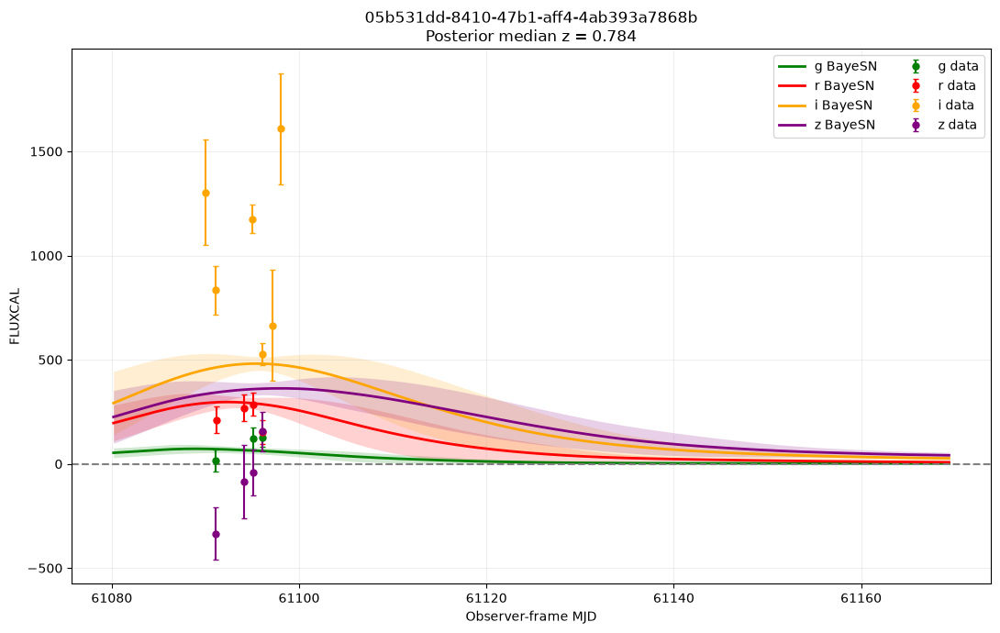

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.65s/it]


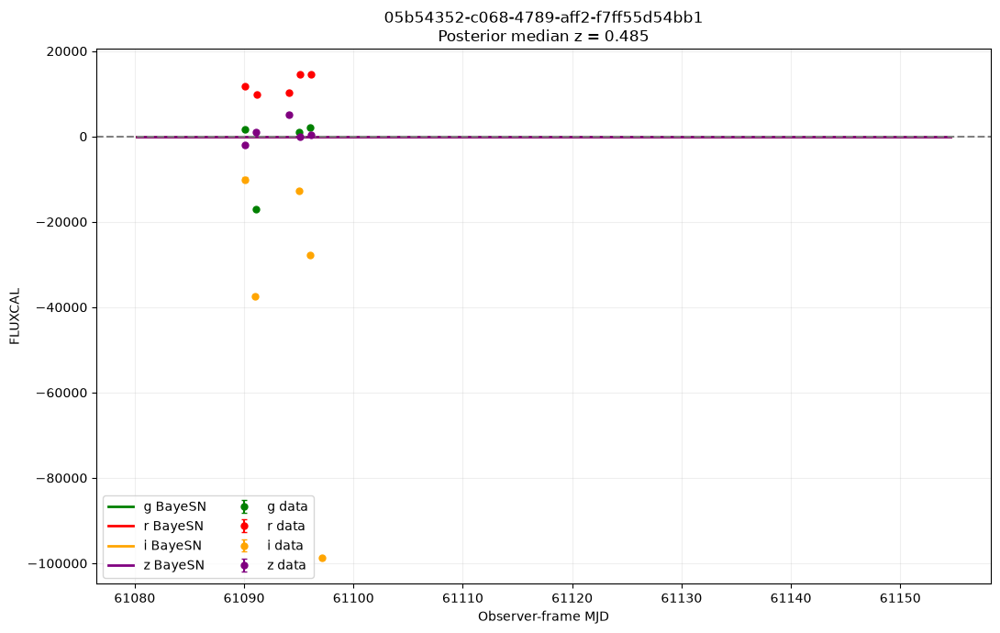

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.24s/it]


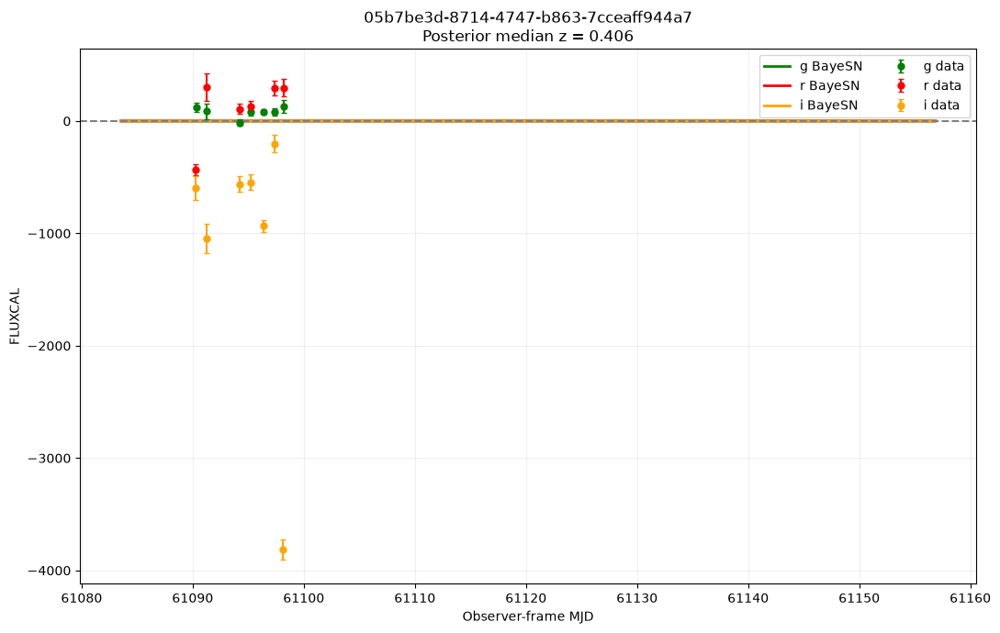

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:03<00:00,  3.12s/it]


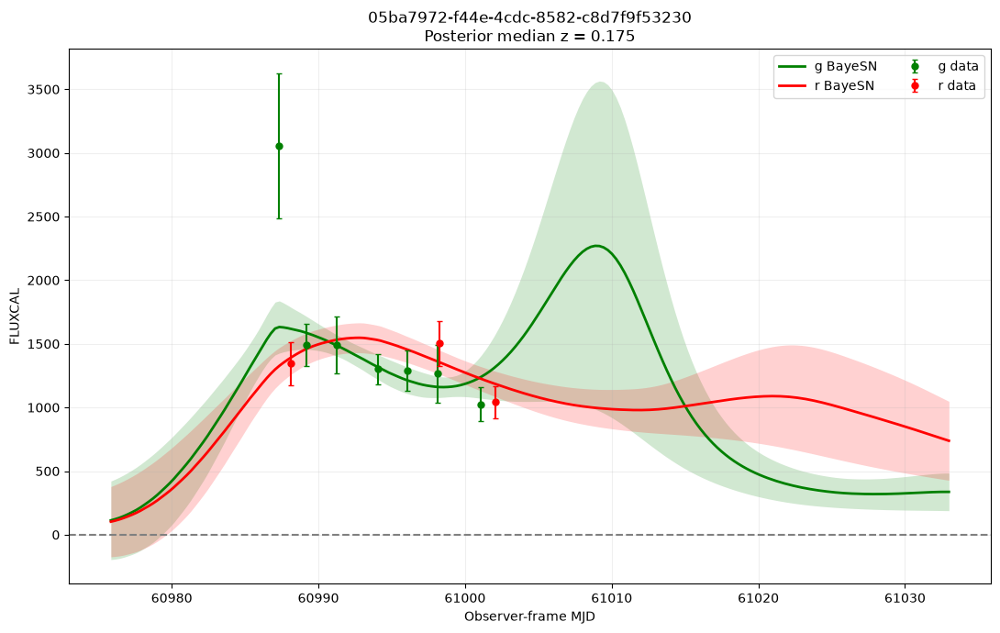

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.30s/it]


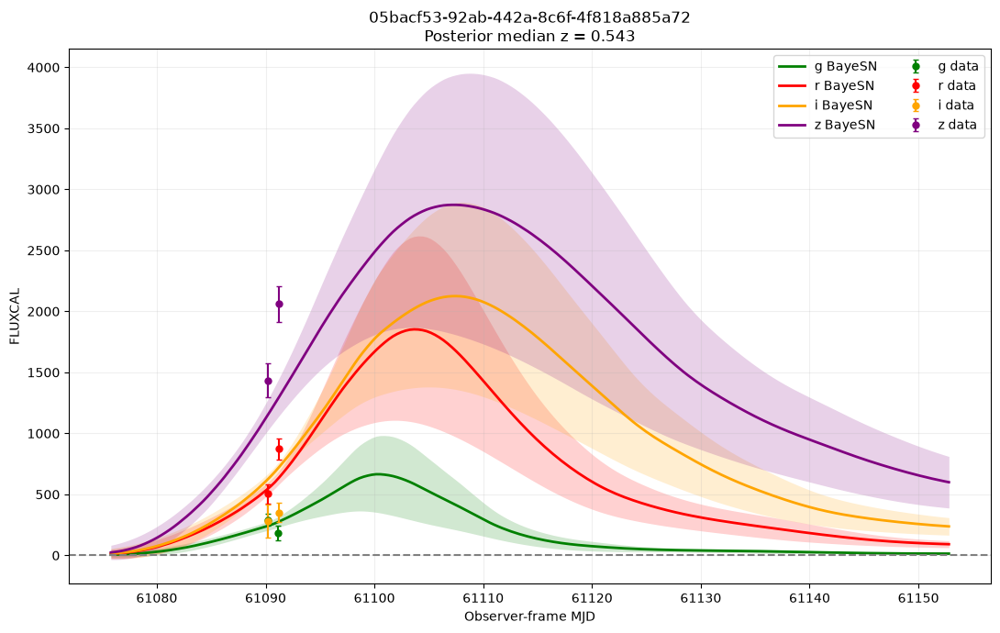

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:04<00:00,  4.81s/it]


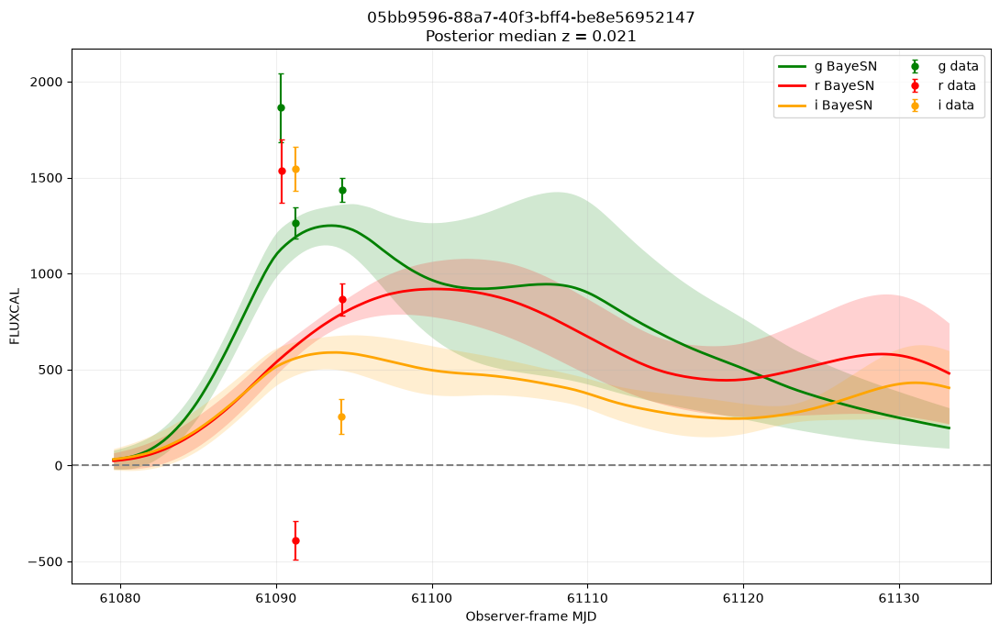

In [65]:
batch_path = Path("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks/fit_results/batch_0011.pkl")

with open(batch_path, "rb") as f:
    batch_0 = pickle.load(f)

print(f"{len(batch_0)} fits in this batch:")
for snid in batch_0:
    print(" ", snid)

for snid, result in batch_0.items():
    plot_fit(snid, result["samples"])

8 fits in this batch:
  05c08e77-90c7-4661-b9f2-2f00b2e1aef6
  05c0fee2-4cb7-424d-9fbf-d941a0497f0c
  05c1c8e0-8c7b-4948-8748-0db8d6b22517
  05c2b703-2063-4c7e-8ee9-2efd5605caea
  05c4f87a-88e8-459e-97b0-7efd523d1d31
  05c58877-73f0-40ec-8fcd-ee35aa14d593
  05c66ef0-c917-4077-a40c-9857a50d8337
  05c8ff8a-3999-4a36-8d17-c38fbf55ebb6
Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.84s/it]


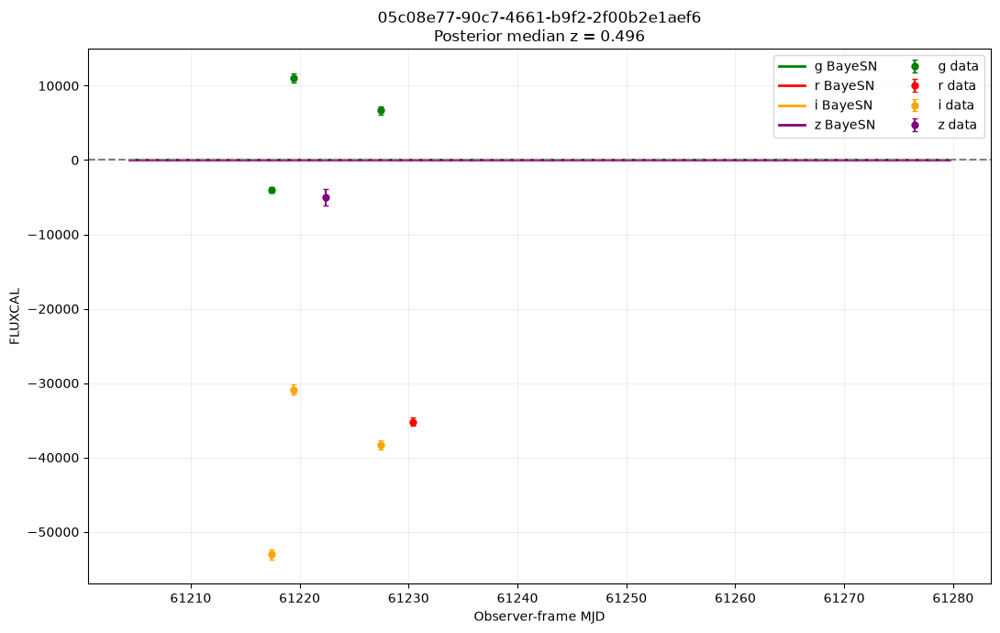

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.26s/it]


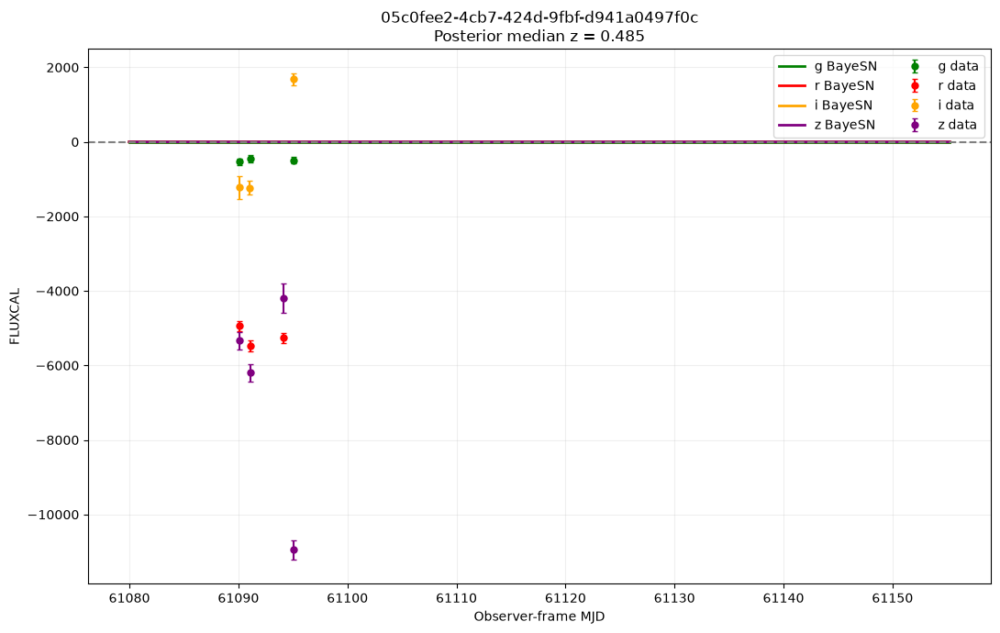

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:09<00:00,  9.88s/it]


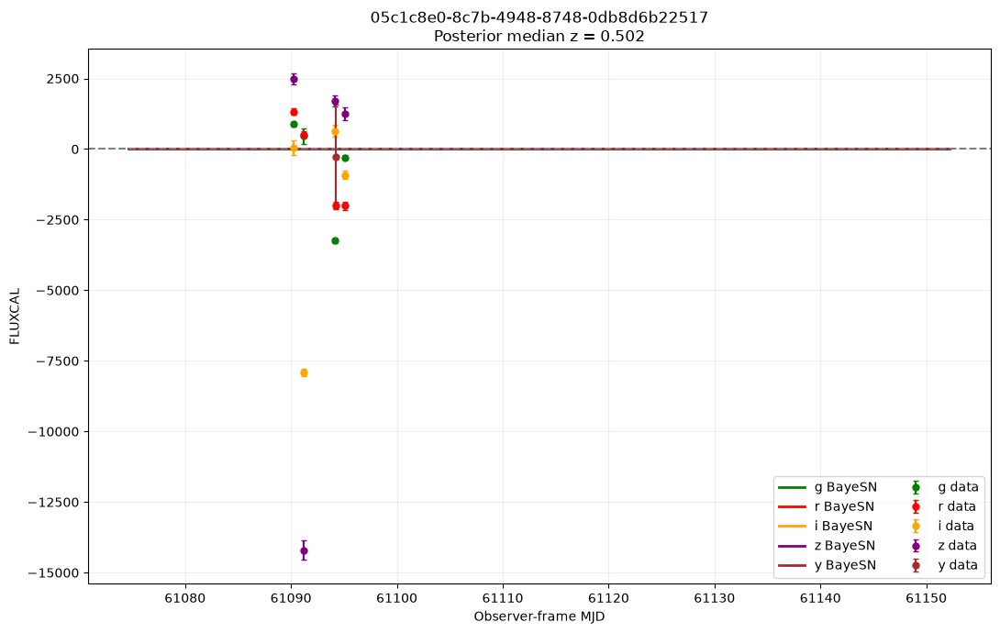

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.94s/it]


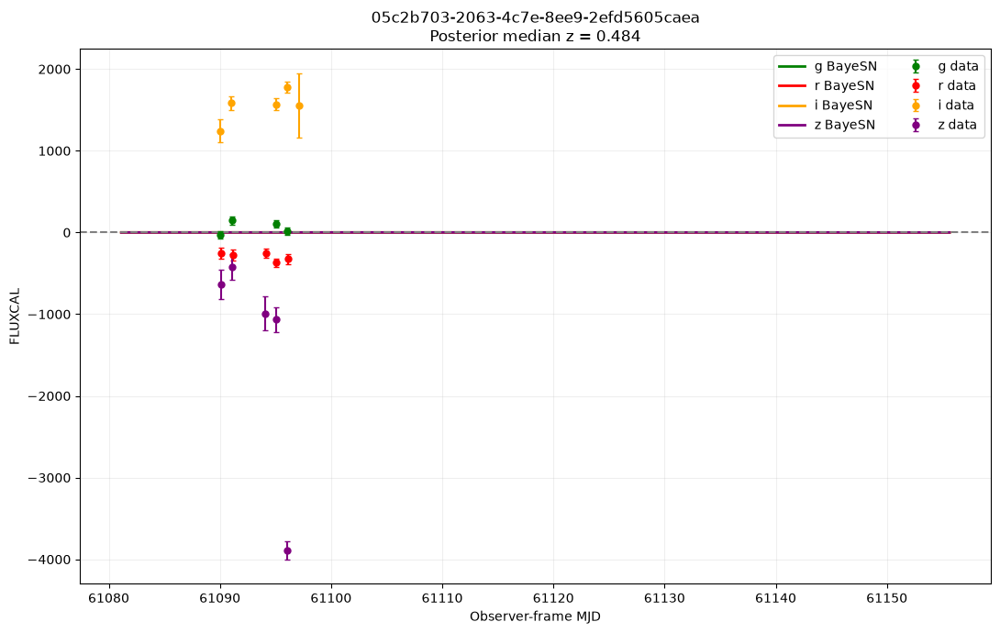

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:09<00:00,  9.90s/it]


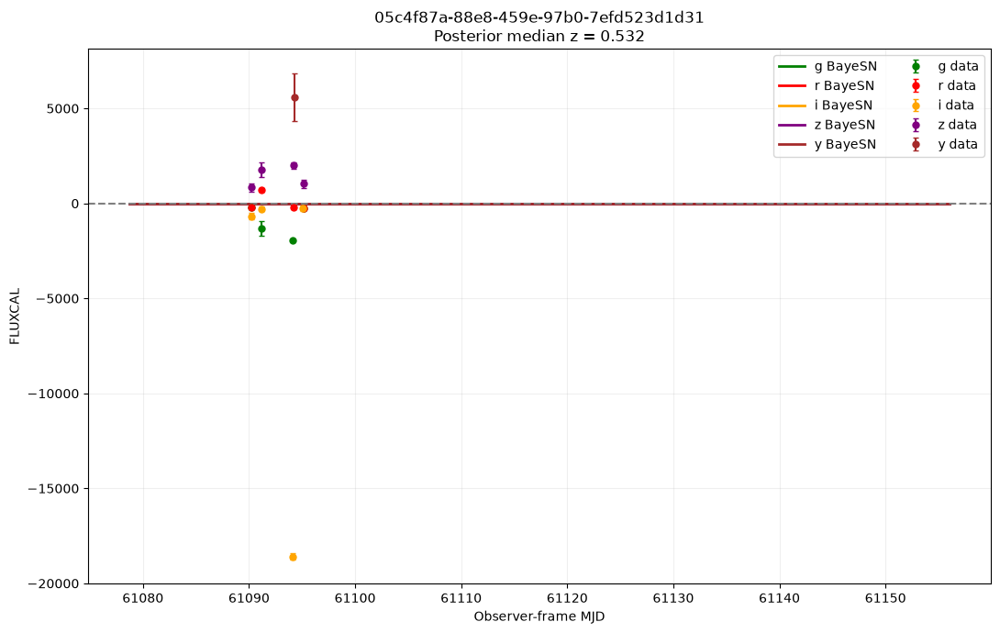

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.49s/it]


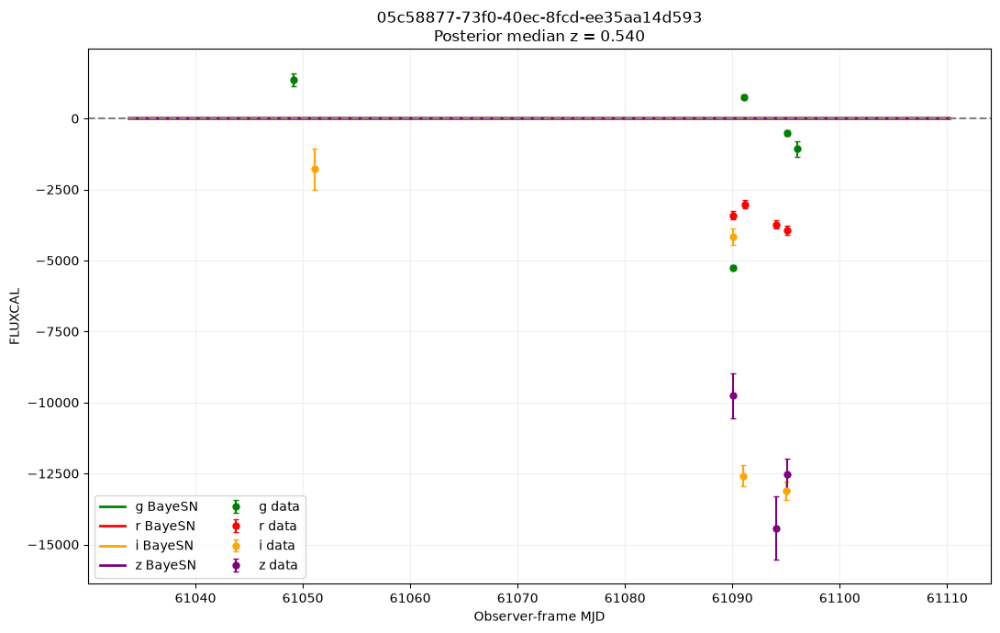

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.21s/it]


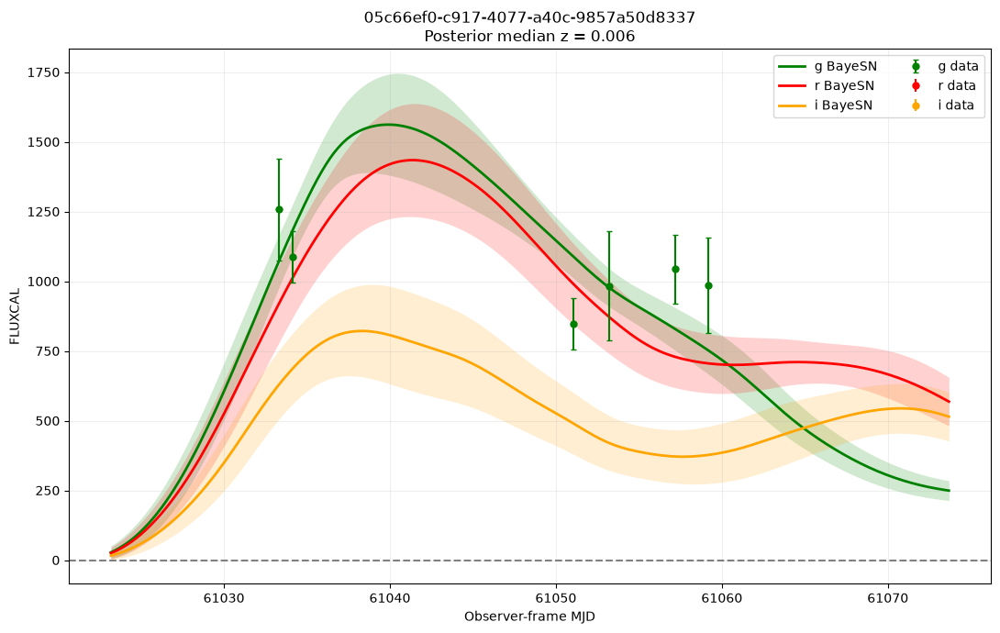

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.05s/it]


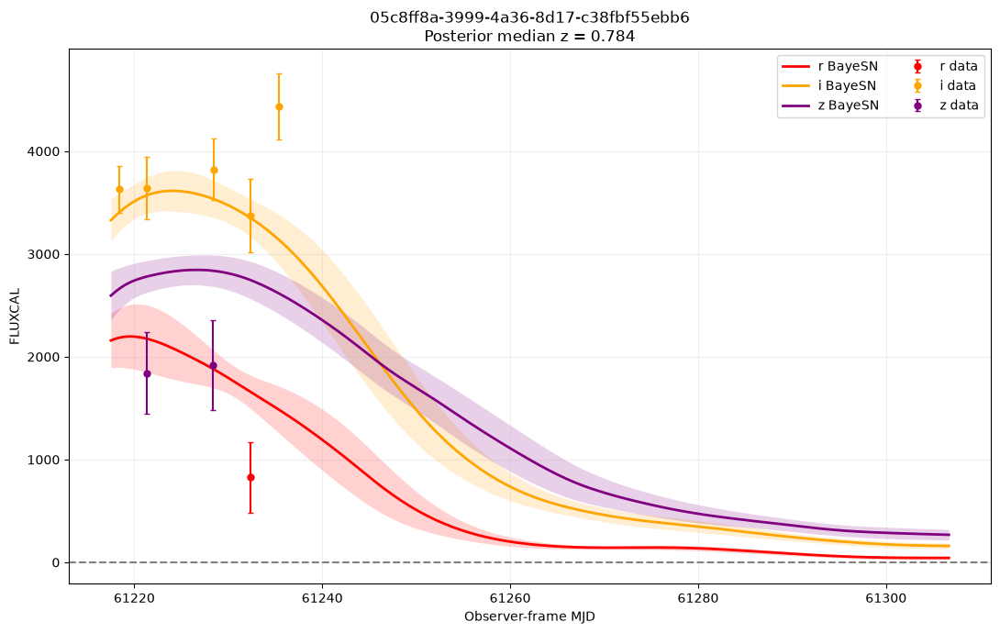

In [66]:
batch_path = Path("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks/fit_results/batch_0012.pkl")

with open(batch_path, "rb") as f:
    batch_0 = pickle.load(f)

print(f"{len(batch_0)} fits in this batch:")
for snid in batch_0:
    print(" ", snid)

for snid, result in batch_0.items():
    plot_fit(snid, result["samples"])

10 fits in this batch:
  05ca5aa5-56cc-453e-950a-ac80e4740ac4
  05caa623-1422-4abb-aa40-73cbd98fe194
  05cd6303-587c-465c-9bac-97e26fb840b3
  05ce4dd7-51ae-4260-a019-15d7e818cce4
  05d06343-ffec-4d88-bb17-0dad615732d0
  05d1a104-58ef-4738-a4b8-320cac41abcc
  05d1c648-8cf3-4213-a60f-4bdb16444b49
  05d34246-9086-478e-9564-a797f152b920
  05d3dd4f-8aa5-400c-a09c-d4d7e56761e4
  05d61dfc-ca17-47c5-bdf1-8eea4e69e57d
Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.13s/it]


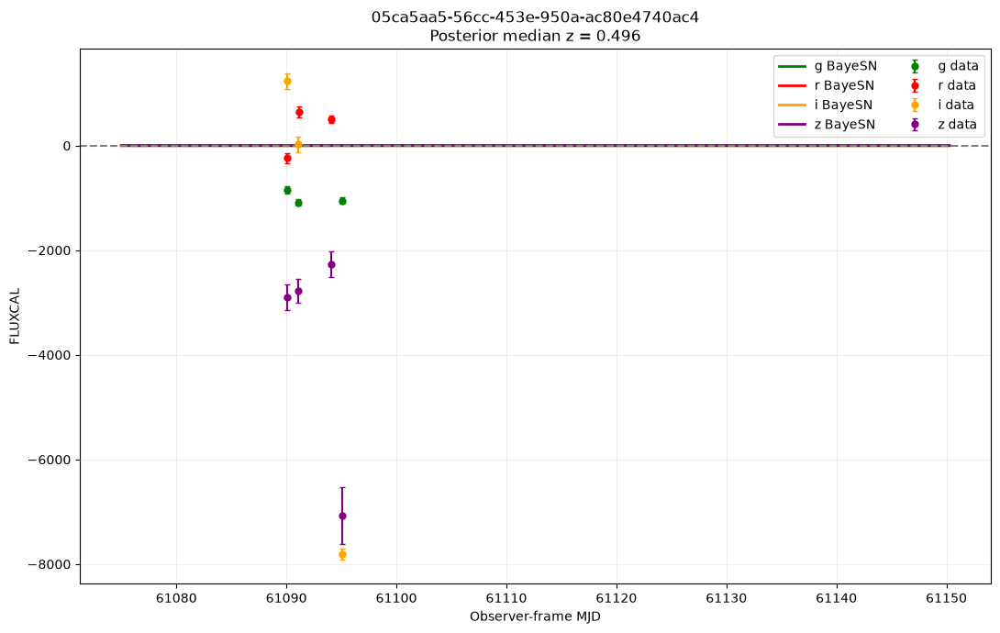

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.86s/it]


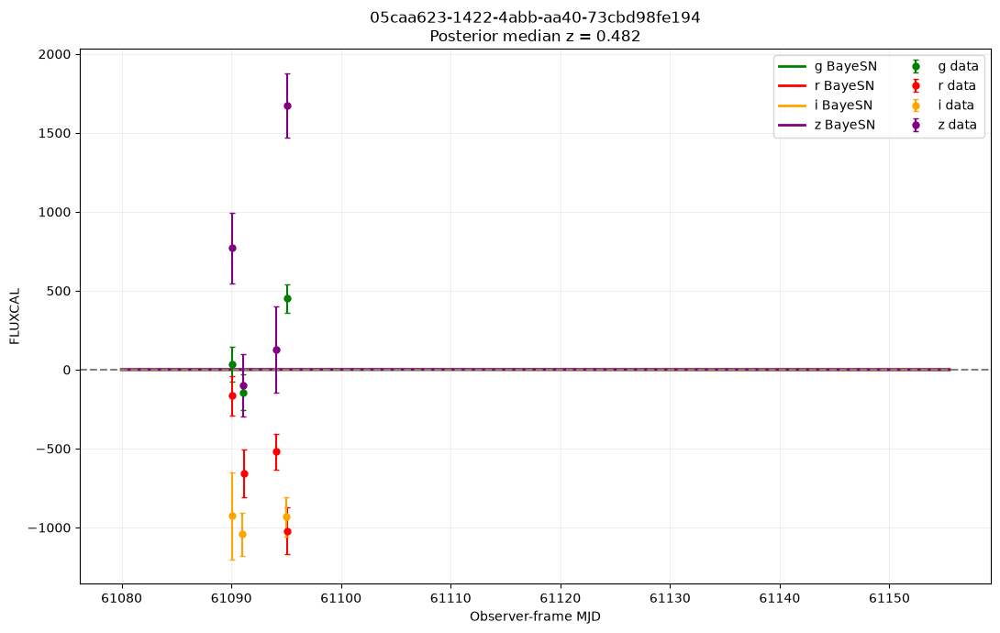

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.39s/it]


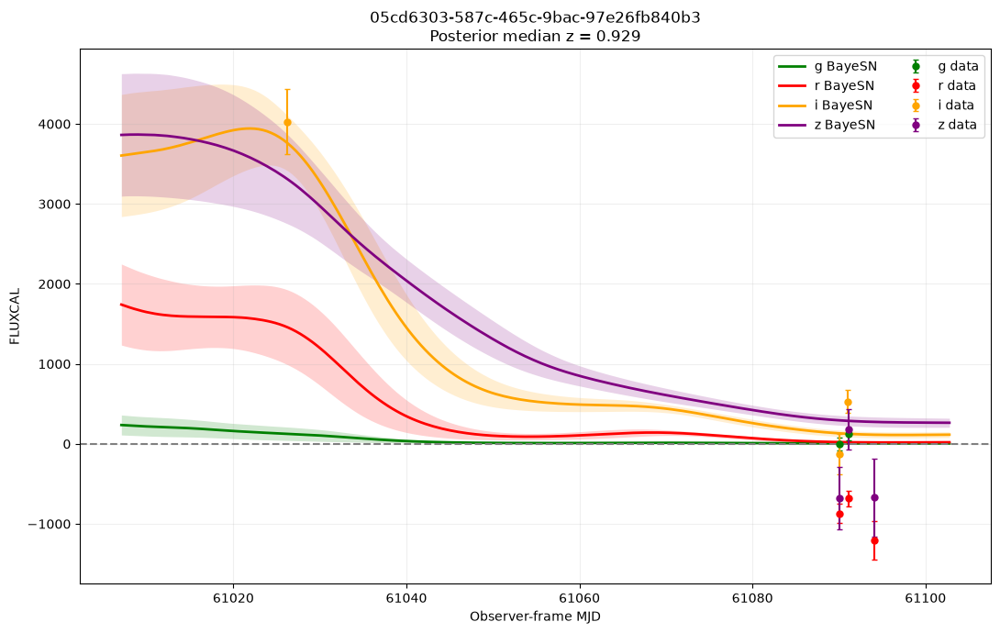

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.08s/it]


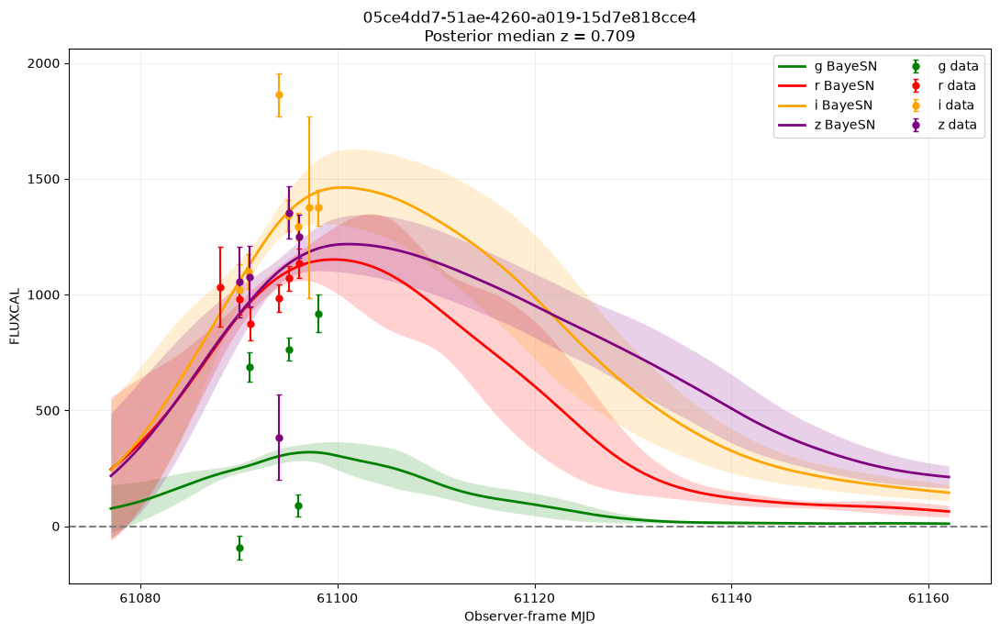

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.15s/it]


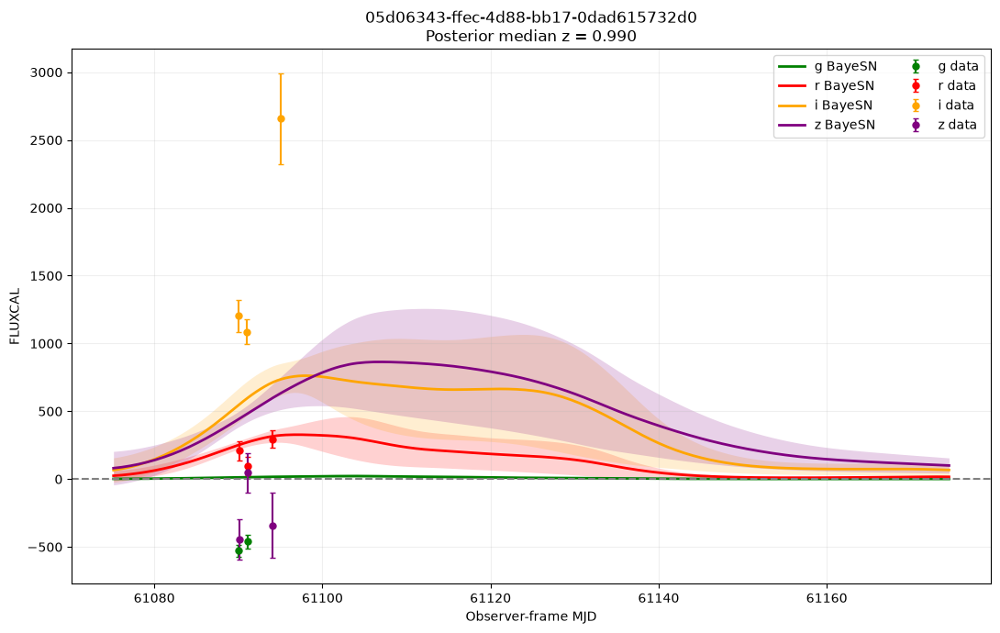

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.16s/it]


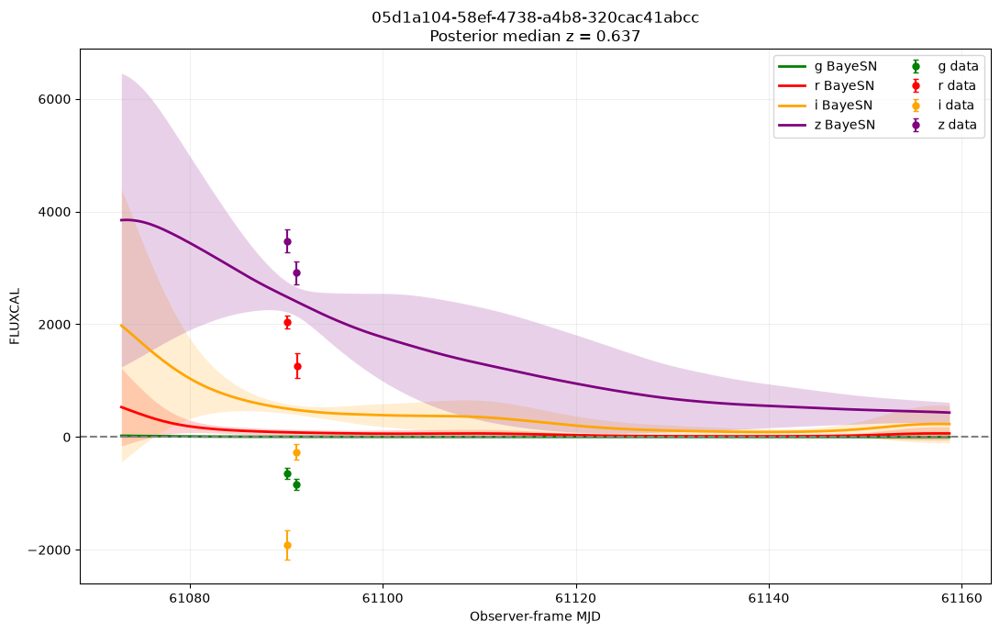

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.15s/it]


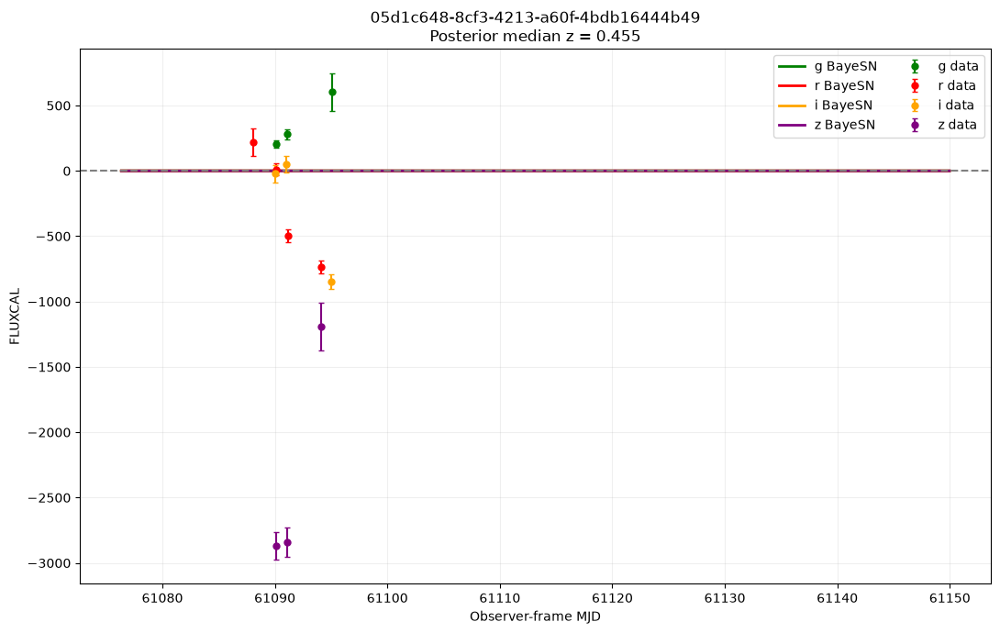

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.65s/it]


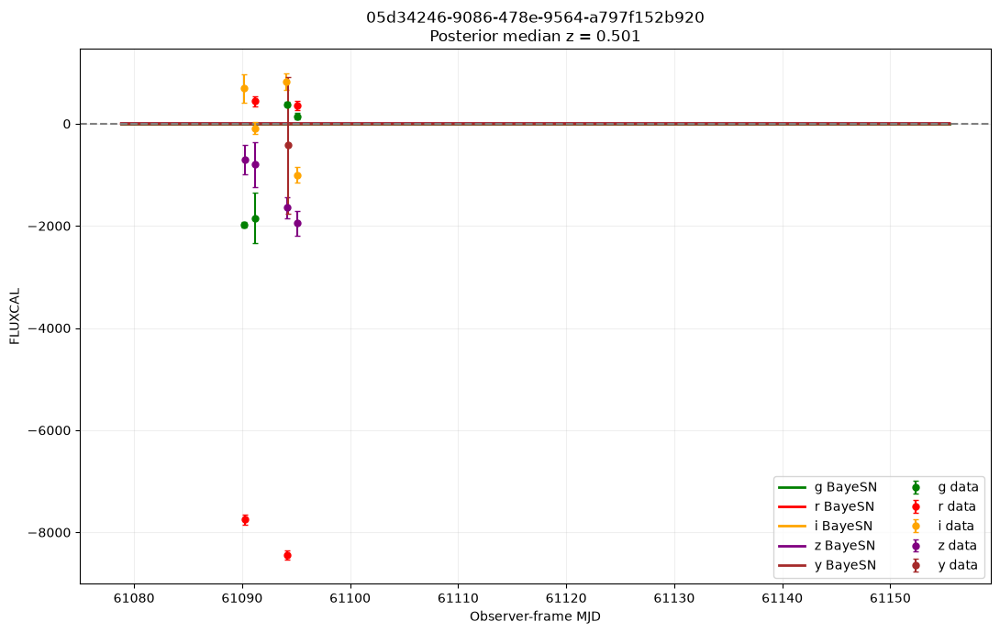

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:04<00:00,  4.43s/it]


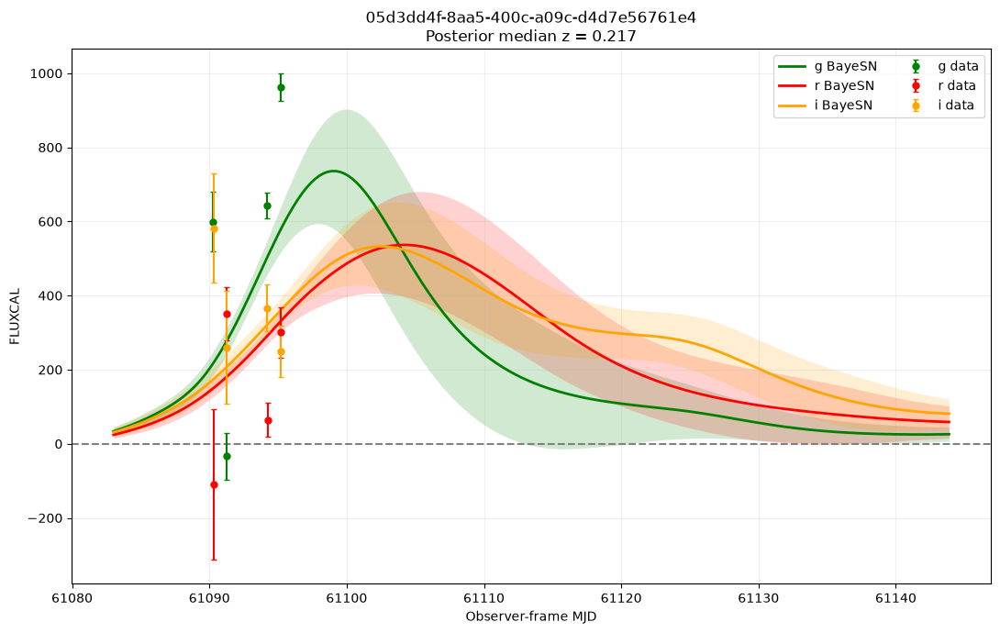

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.10s/it]


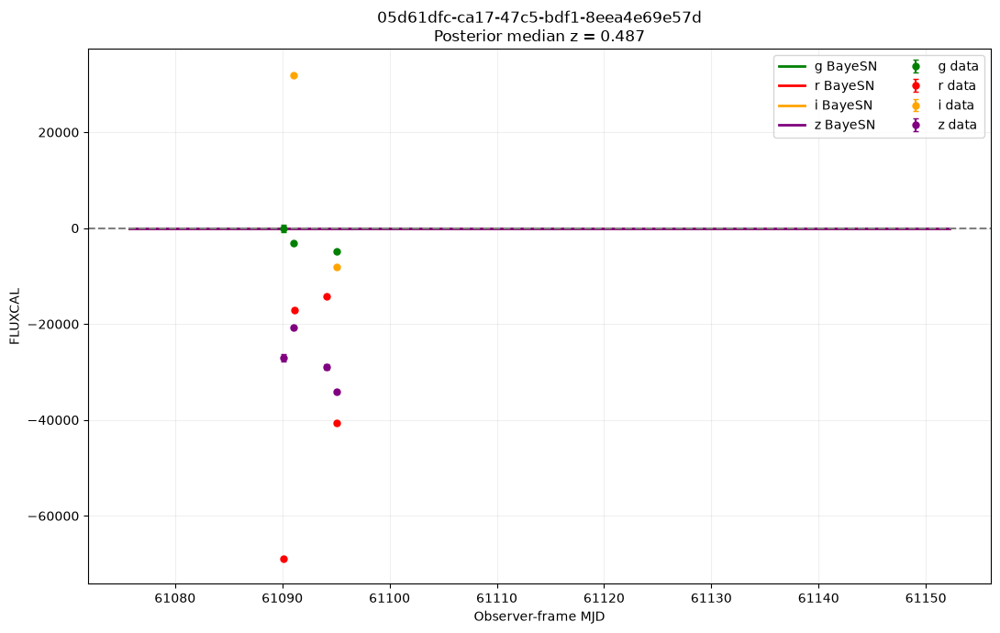

In [67]:
batch_path = Path("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks/fit_results/batch_0013.pkl")

with open(batch_path, "rb") as f:
    batch_0 = pickle.load(f)

print(f"{len(batch_0)} fits in this batch:")
for snid in batch_0:
    print(" ", snid)

for snid, result in batch_0.items():
    plot_fit(snid, result["samples"])

8 fits in this batch:
  05d64802-e488-4b8a-802b-a8228a8438f6
  05d96410-a773-437d-acb4-5165c28f132b
  05dcd528-828e-4ea8-8e40-932d0c792b8e
  05dd88e2-a8c3-40ad-8129-ea760dadace0
  05ddb408-a946-4f74-9b90-511915d5fb43
  05df1632-8921-44df-8cb7-cb406a07e5c6
  05df87cb-3862-4d66-a298-af9a37825236
  05e04723-c482-4587-94a0-0a127c3b9944
Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.60s/it]


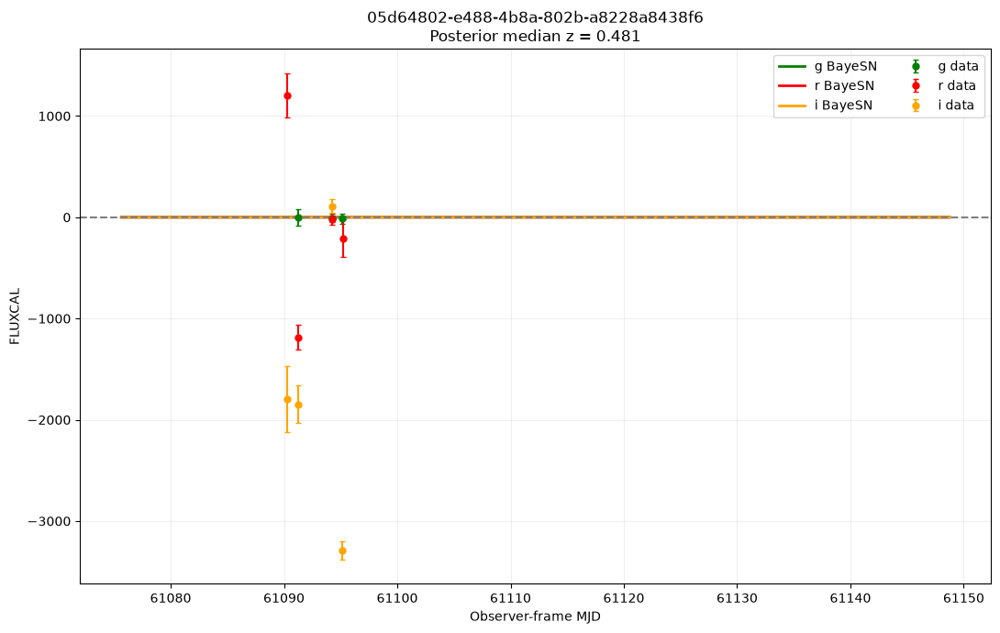

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.93s/it]


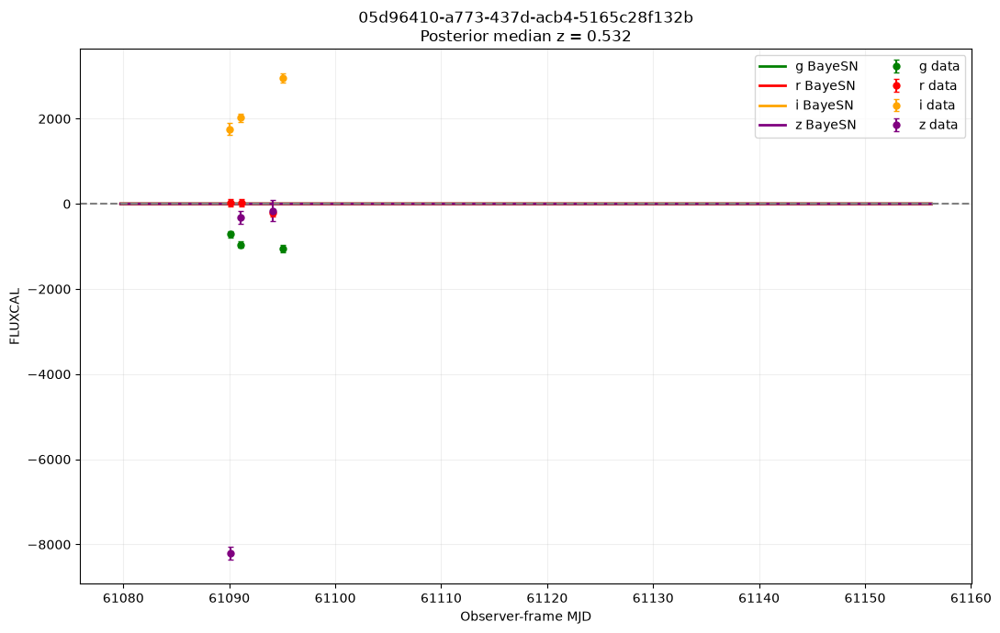

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:08<00:00,  8.44s/it]


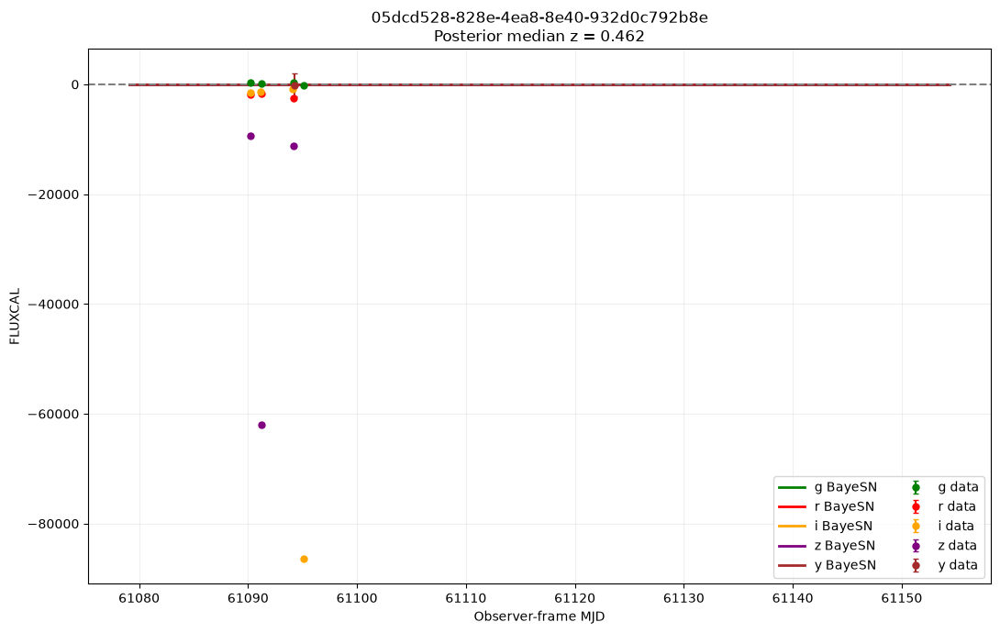

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.07s/it]


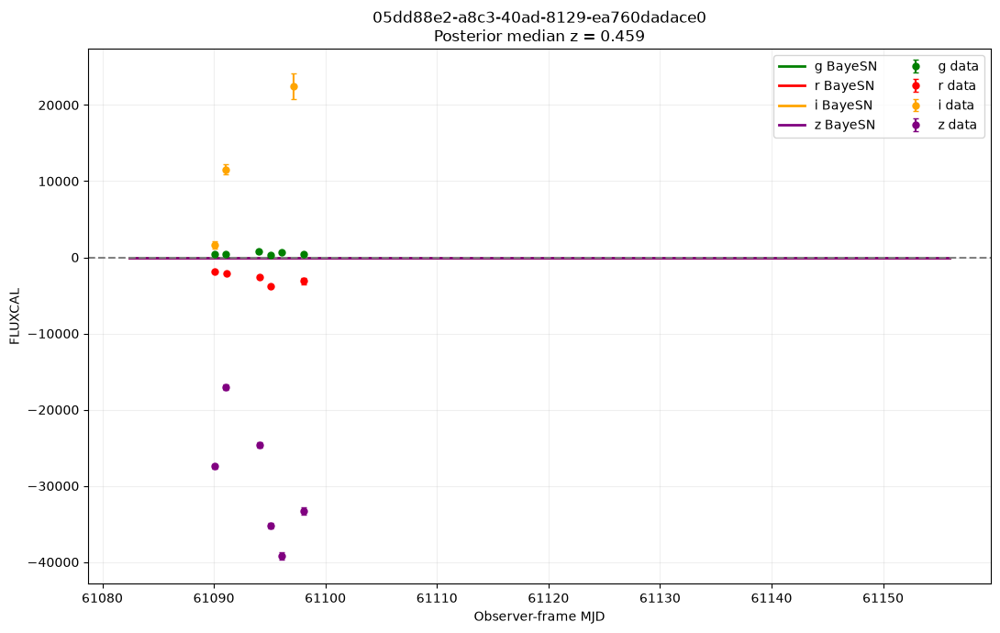

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:08<00:00,  8.34s/it]


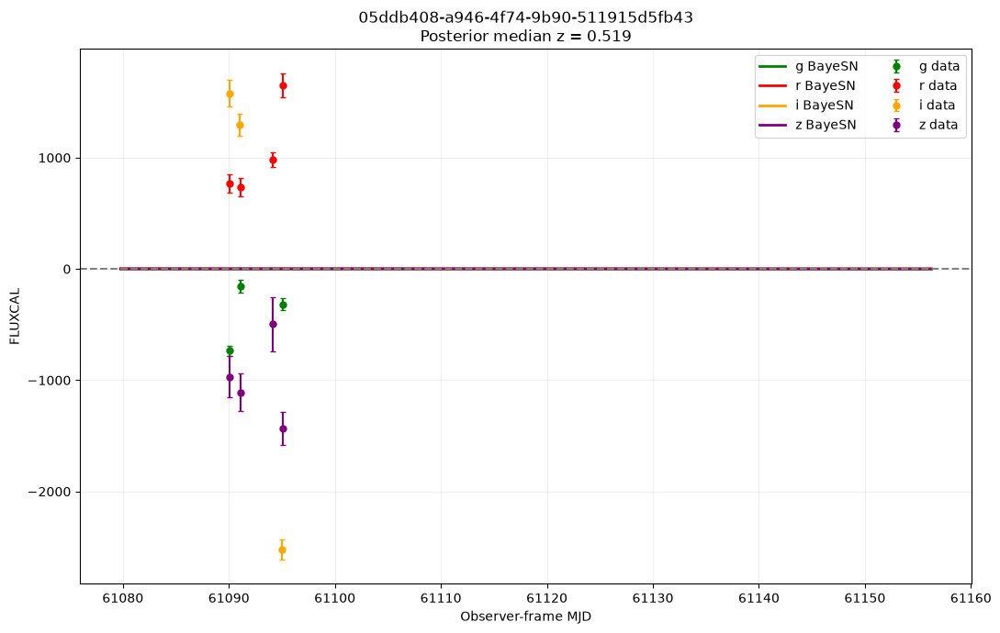

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:09<00:00,  9.90s/it]


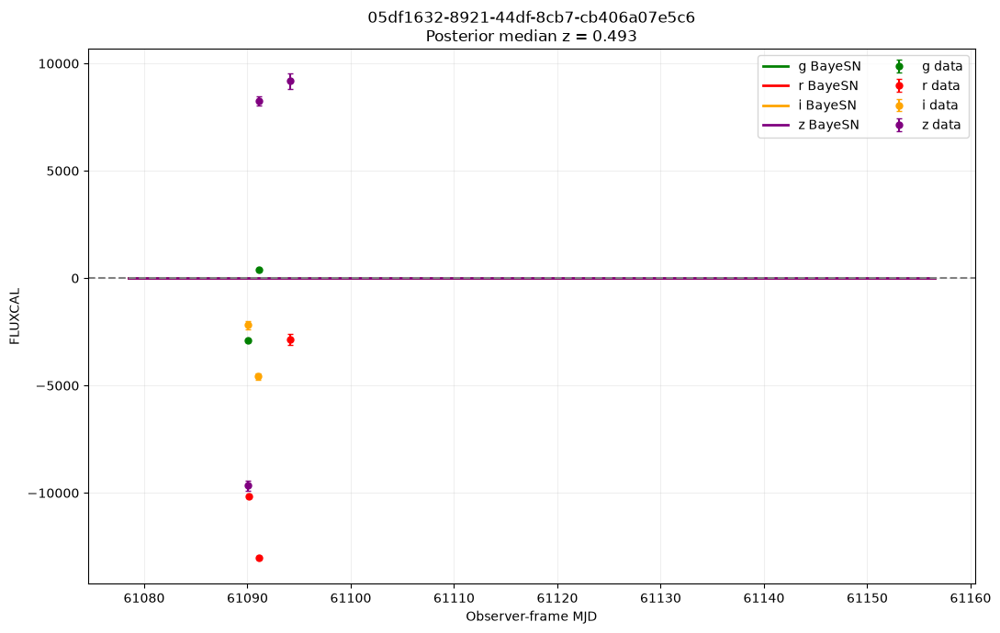

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.31s/it]


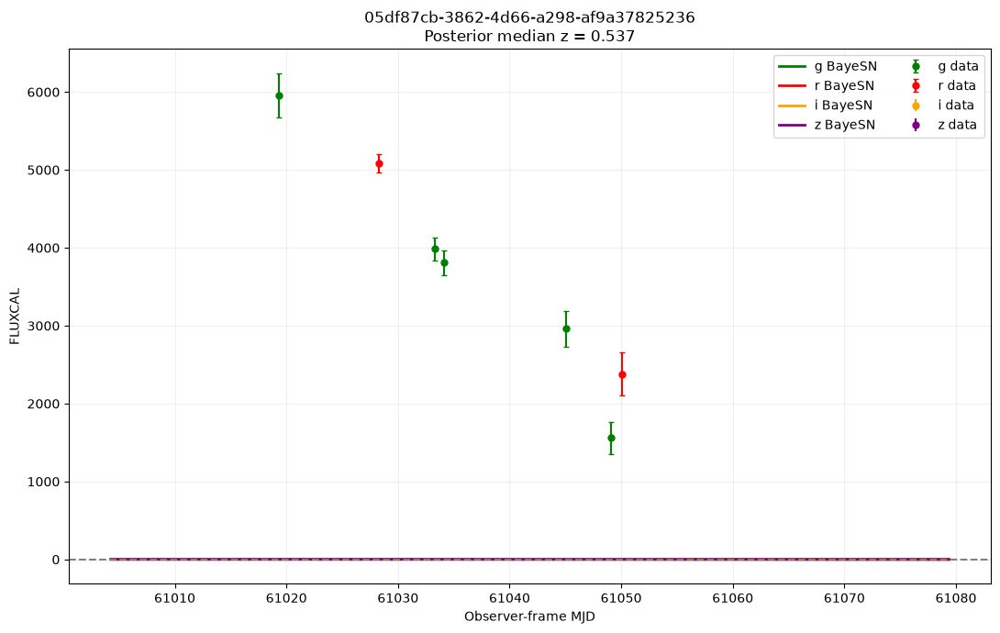

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:09<00:00,  9.98s/it]


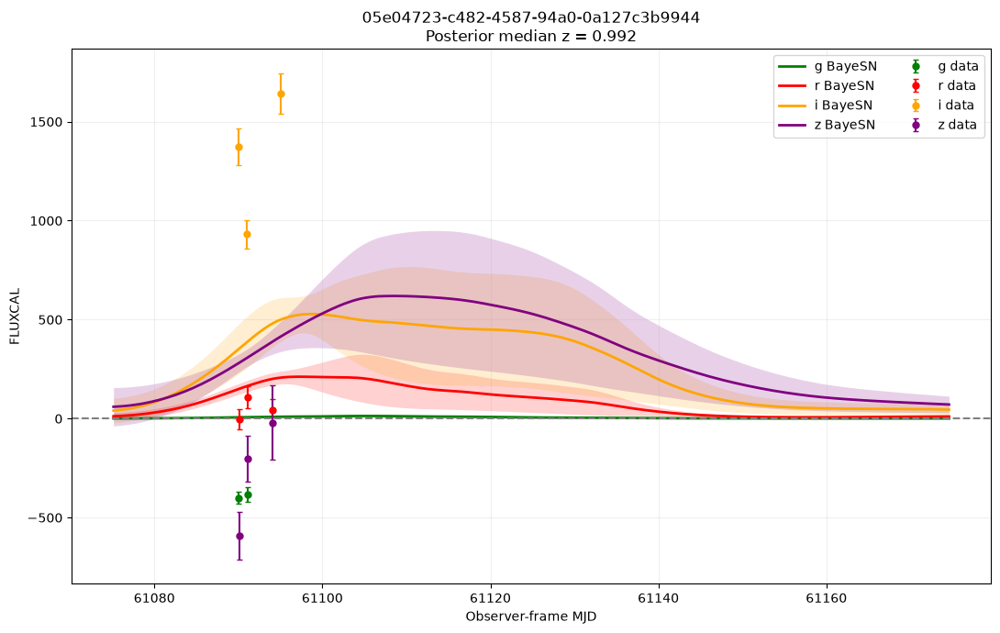

In [68]:
batch_path = Path("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks/fit_results/batch_0014.pkl")

with open(batch_path, "rb") as f:
    batch_0 = pickle.load(f)

print(f"{len(batch_0)} fits in this batch:")
for snid in batch_0:
    print(" ", snid)

for snid, result in batch_0.items():
    plot_fit(snid, result["samples"])

9 fits in this batch:
  05e24b6e-bb57-40ae-b35a-e9ff1ffdceb9
  05e2b3ec-416f-4769-b054-ebd126c60294
  05e3005a-a345-44a2-8a61-69e50c4c1c38
  05e3dee8-fe1c-4156-817c-9474fa1db11b
  05e5feab-66aa-43a4-a4ab-abf4ef90e82f
  05e7407b-cbe1-4dbc-8ab6-02669612ad8d
  05e7d796-fdaa-49e4-8253-37a0f6392d74
  05e901ea-c224-42a1-ad0e-b246c99fe1d1
  05e933ba-b281-41d1-8aeb-62ce3397b8ba
Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.40s/it]


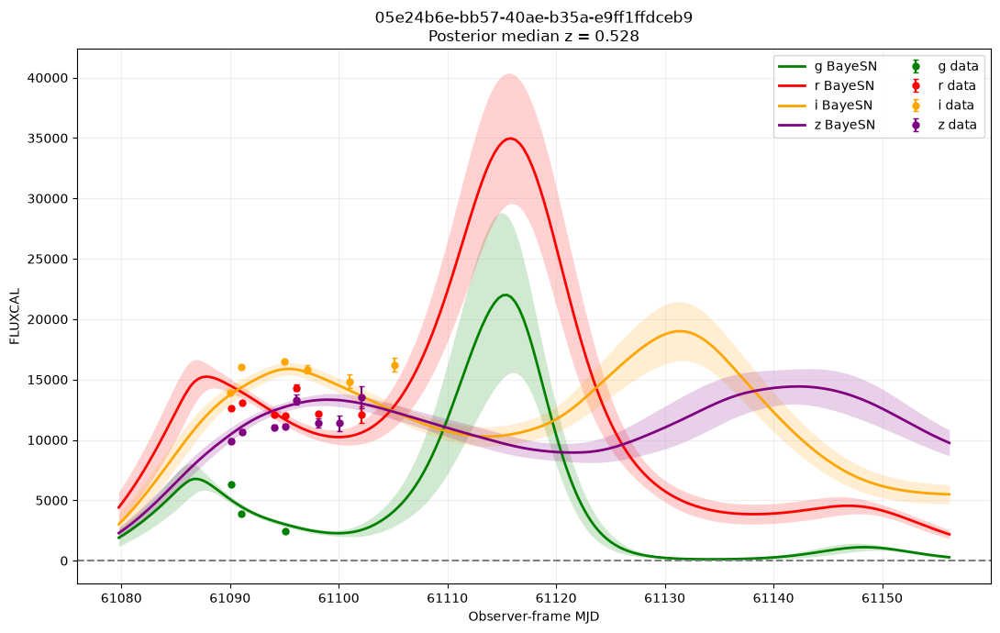

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.96s/it]


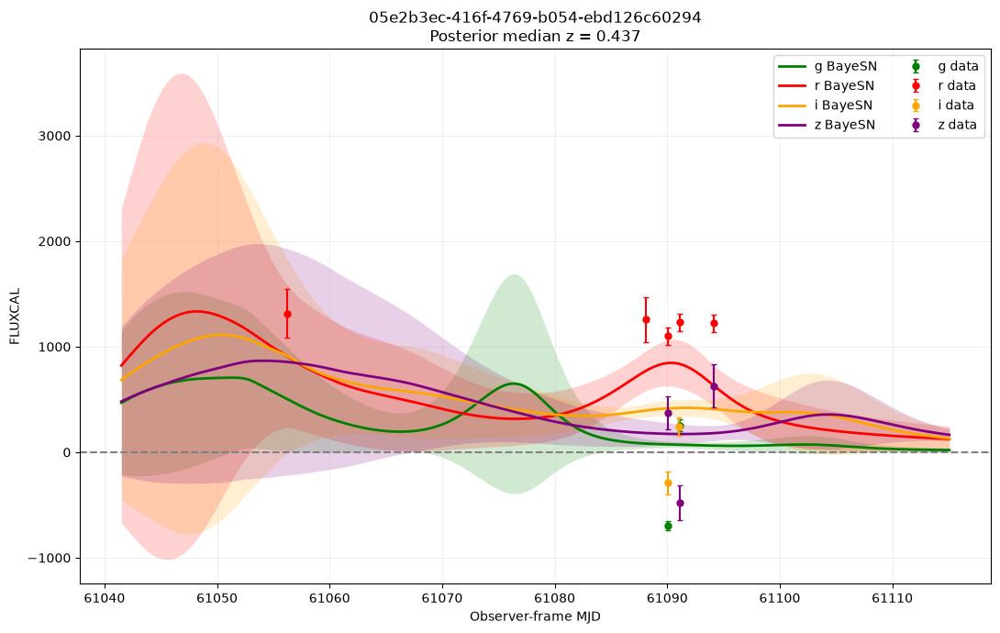

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:04<00:00,  4.49s/it]


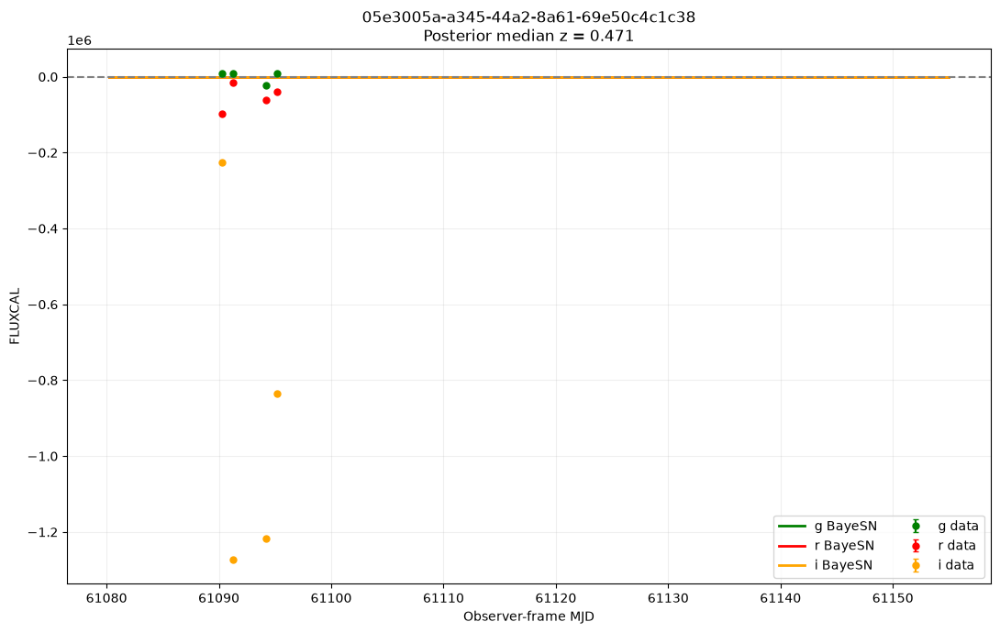

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.81s/it]


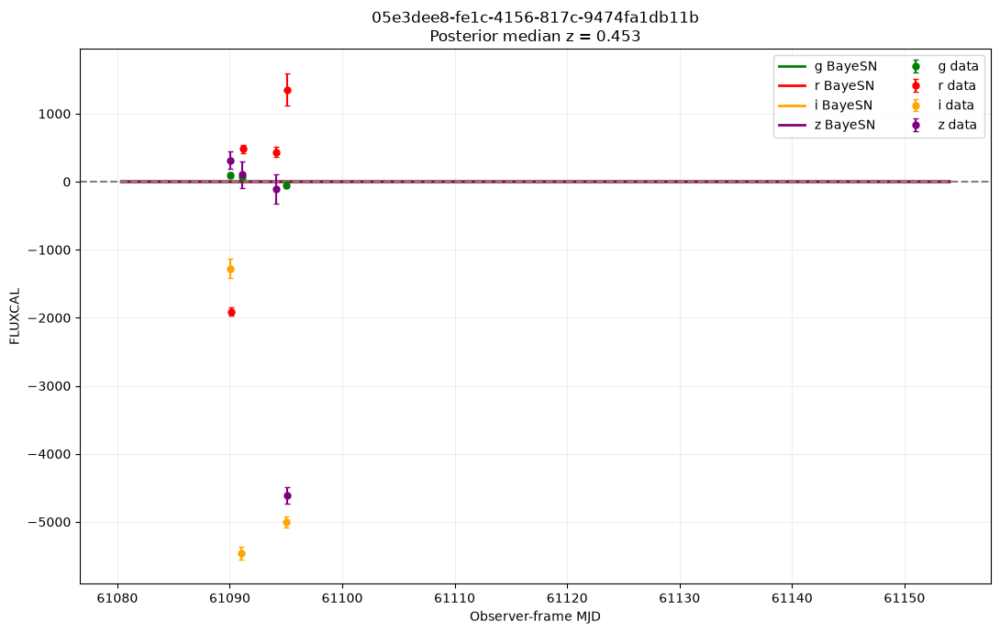

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:08<00:00,  8.82s/it]


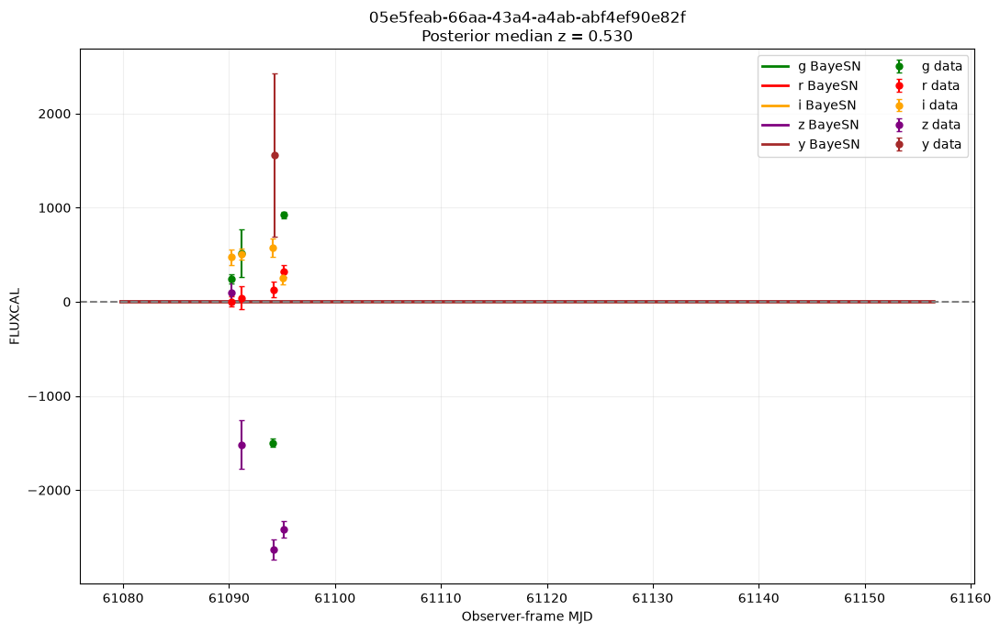

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:10<00:00, 10.01s/it]


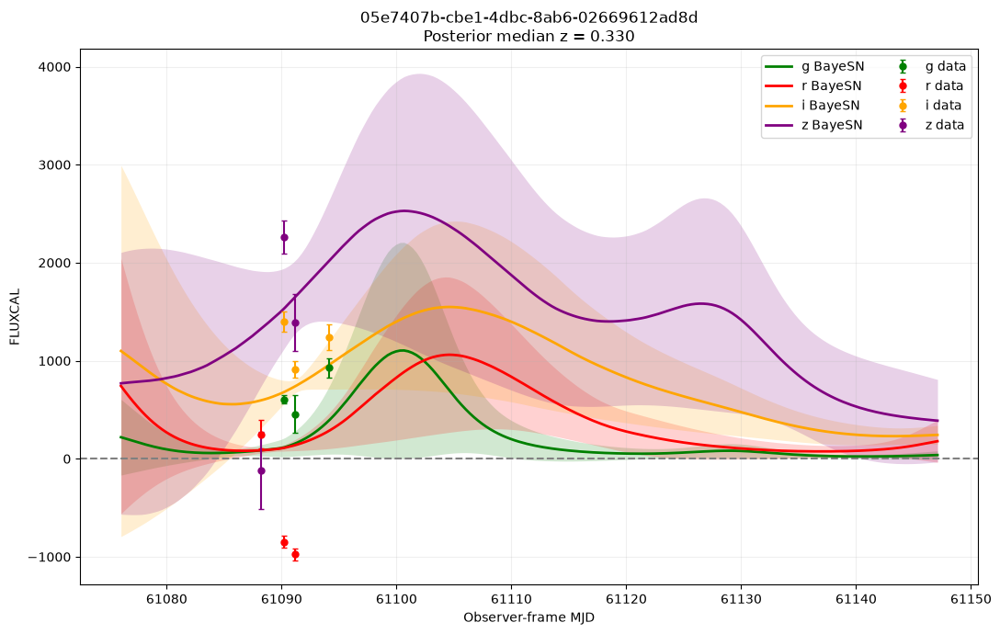

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:08<00:00,  8.80s/it]


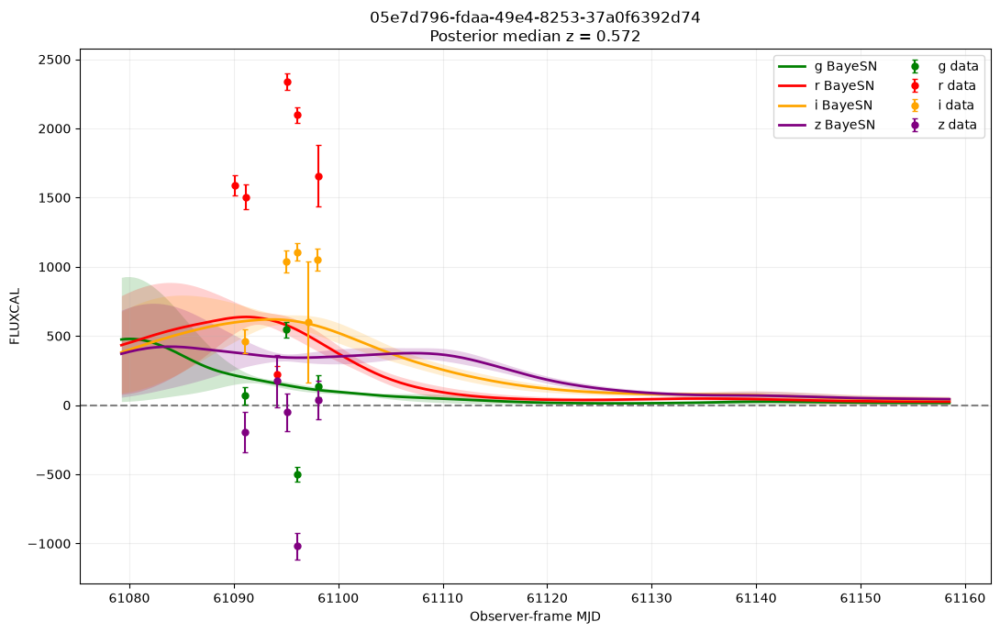

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:04<00:00,  4.70s/it]


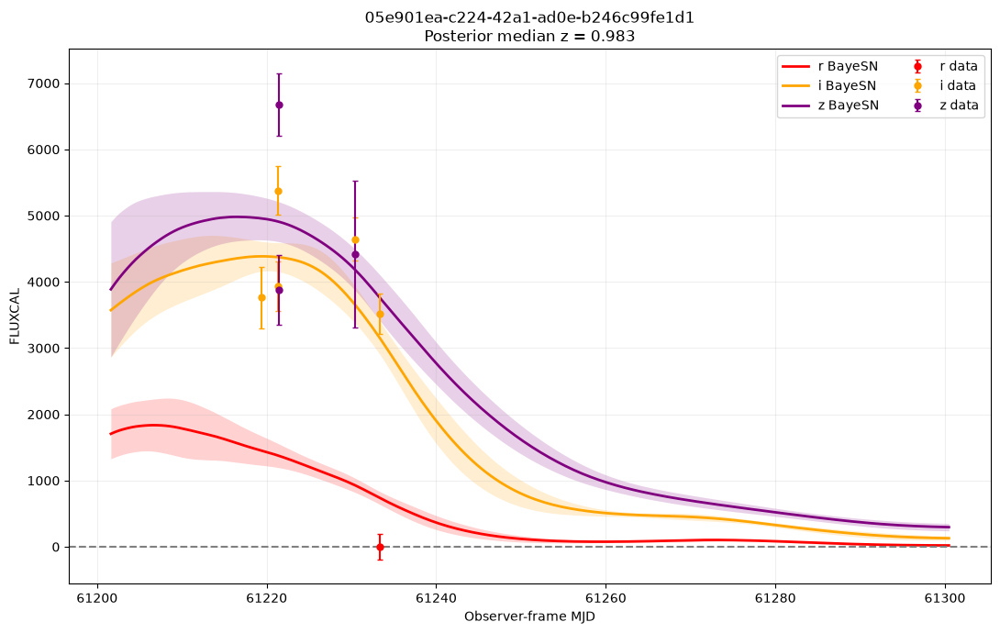

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:03<00:00,  4.00s/it]


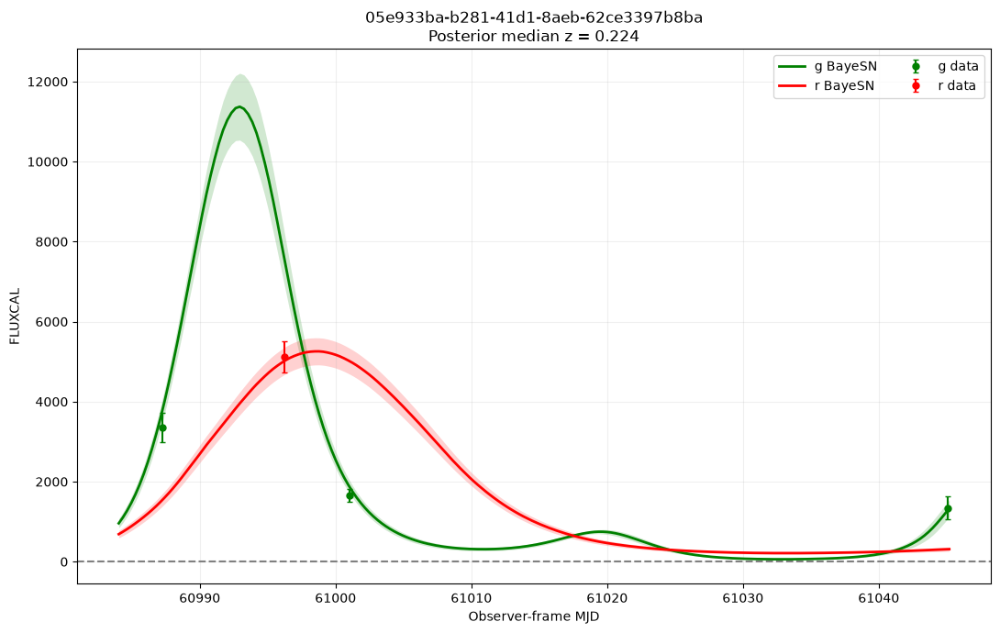

In [69]:
batch_path = Path("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks/fit_results/batch_0015.pkl")

with open(batch_path, "rb") as f:
    batch_0 = pickle.load(f)

print(f"{len(batch_0)} fits in this batch:")
for snid in batch_0:
    print(" ", snid)

for snid, result in batch_0.items():
    plot_fit(snid, result["samples"])

7 fits in this batch:
  05ea41af-f156-4dc7-90d0-da9c7ccf36fc
  05eb563f-d1c3-4c0d-a8bb-d627a1e15fa3
  05eceb0e-317e-4c8c-b345-fc7077f82e0a
  05ef0192-d090-4876-8cc5-51c02dcbd285
  05f2dee2-158d-4c12-8140-b3de0c72c271
  05f41bbb-e82e-4c5f-9324-c74bec6a83d3
  05f7126b-d5de-484a-bae6-ee8cbd9d44d0
Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.93s/it]


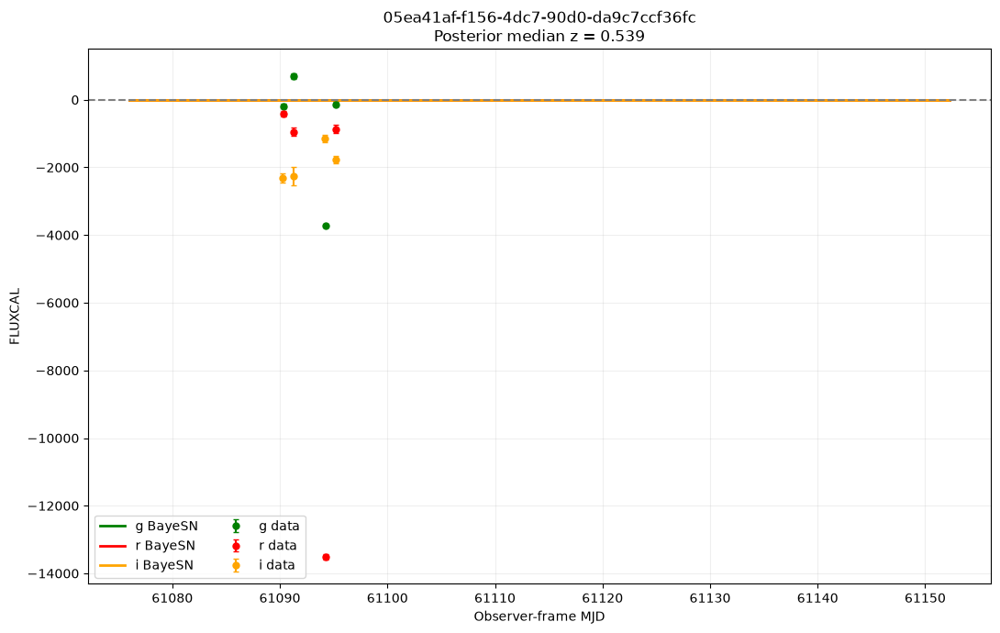

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:11<00:00, 11.36s/it]


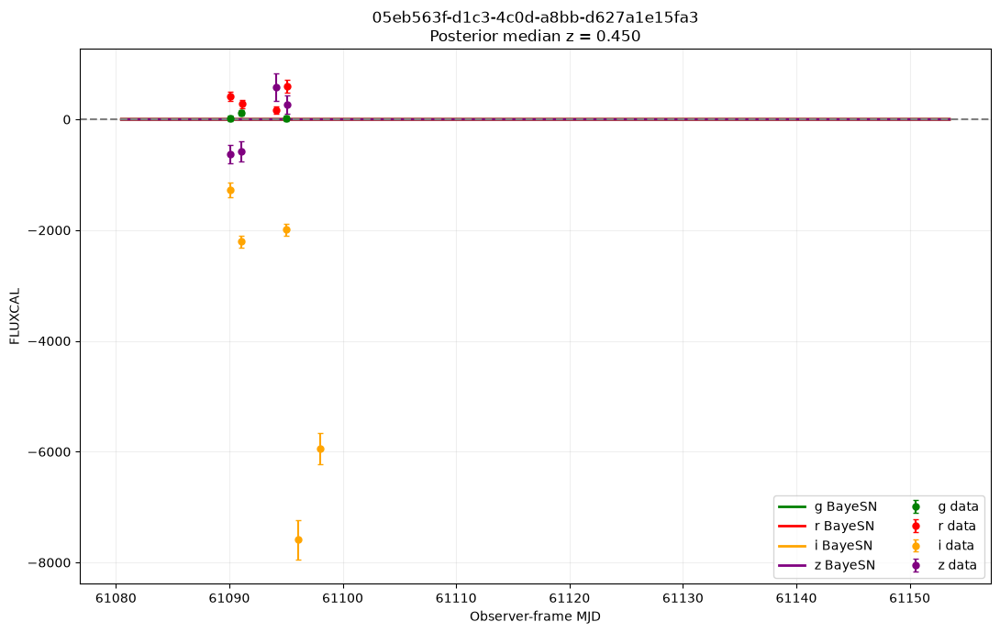

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:10<00:00, 10.21s/it]


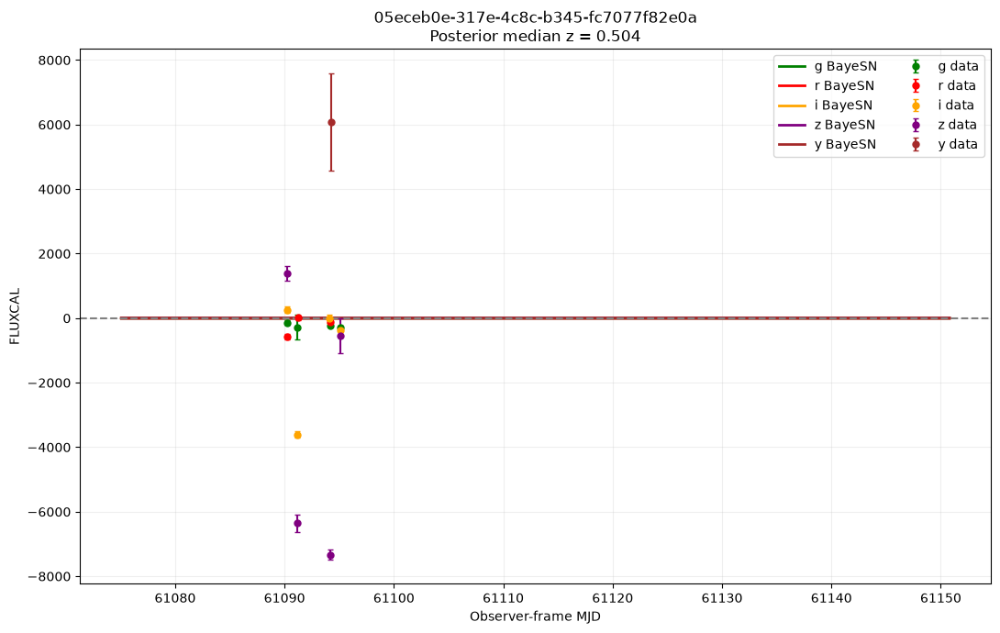

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:08<00:00,  8.30s/it]


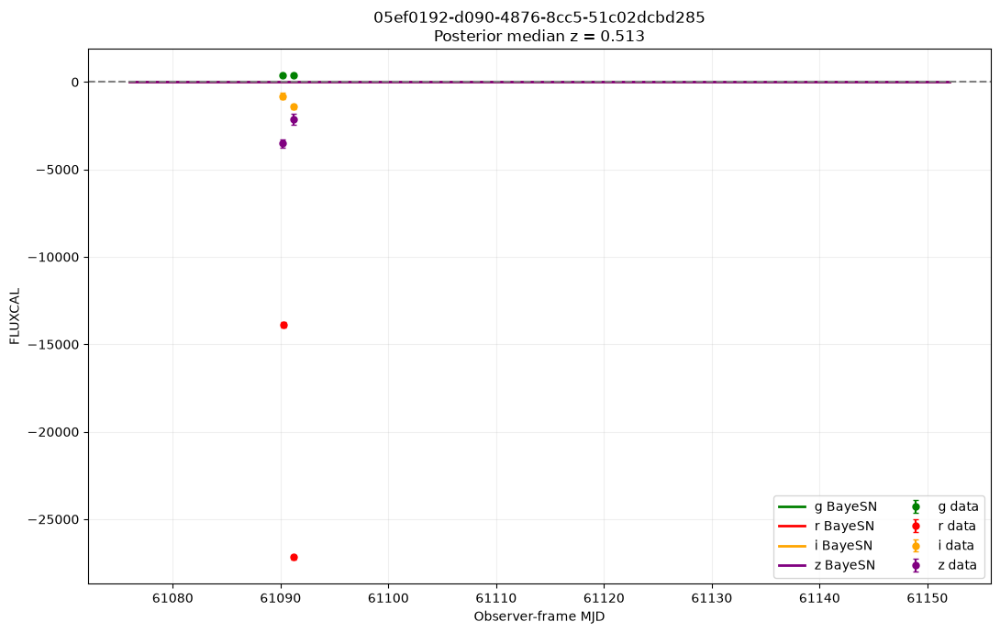

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.66s/it]


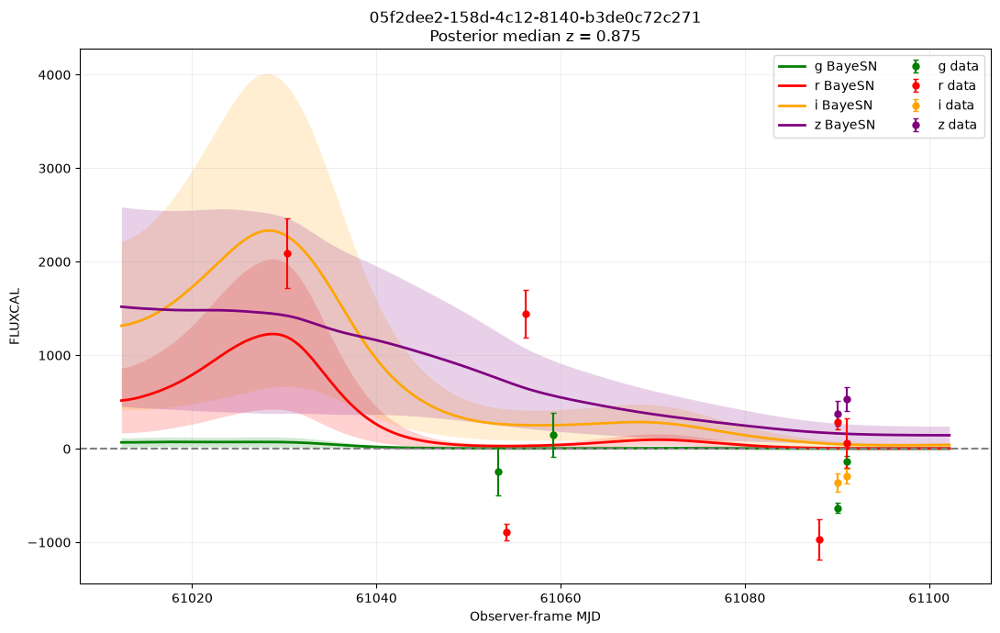

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:08<00:00,  8.84s/it]


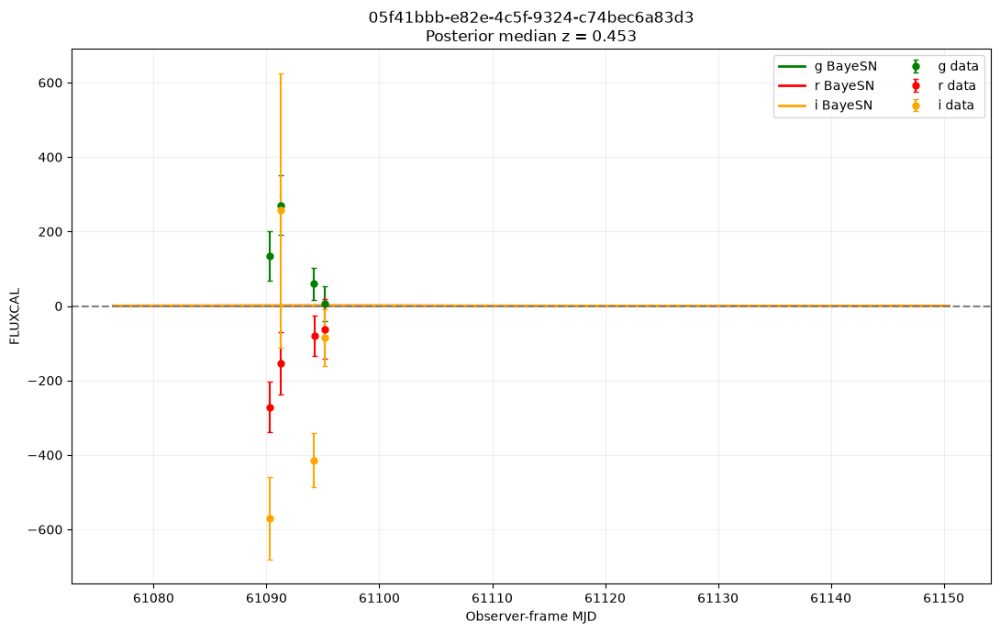

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                                                                              | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:16<00:00, 16.33s/it]


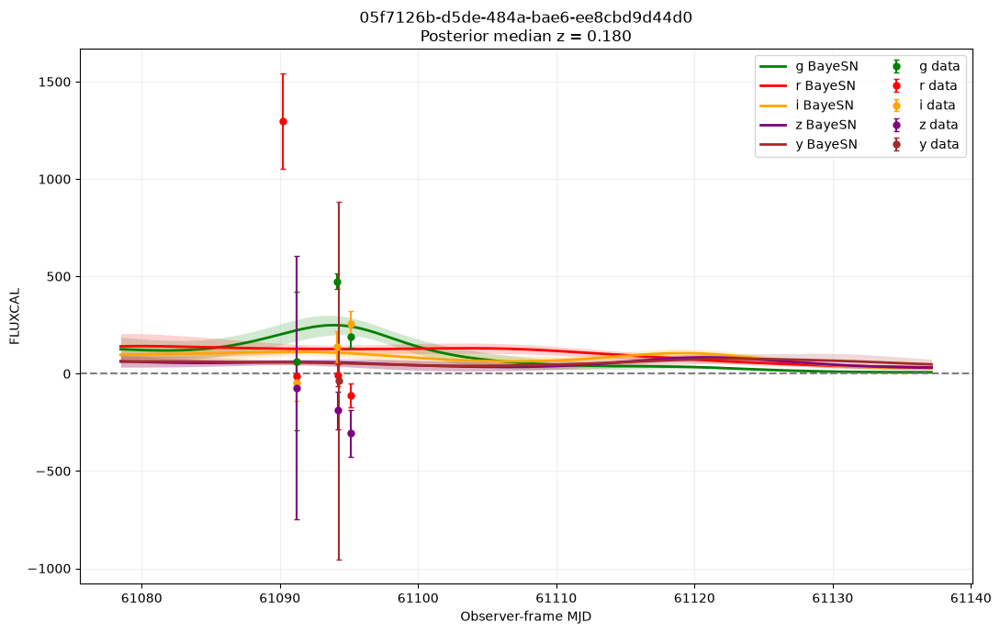

In [70]:
batch_path = Path("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks/fit_results/batch_0016.pkl")

with open(batch_path, "rb") as f:
    batch_0 = pickle.load(f)

print(f"{len(batch_0)} fits in this batch:")
for snid in batch_0:
    print(" ", snid)

for snid, result in batch_0.items():
    plot_fit(snid, result["samples"])

### Host Crossmatch Function

In [51]:
from alerce.core import Alerce

client = Alerce()

def find_host_galaxy(snid, radius_arcsec=15):
    idx = np.flatnonzero(
        np.char.strip(head_data["SNID"].astype(str)) == snid
    )[0]
    head_row = head_data[idx]

    ra = float(head_row["RA"])   
    dec = float(head_row["DEC"]) 

    print(f"{snid}: RA={ra:.5f}, DEC={dec:.5f}")

    results = {}
    for catalog in ["2MASSxsc", "SDSS/DR10", "GAIA/DR2"]:
        try:
            match = client.catshtm_crossmatch(
                ra, dec, radius_arcsec, catalog, format="pandas"
            )
            results[catalog] = match
            if match is not None and len(match) > 0:
                print(f"\n--- {catalog} match ---")
                print(match)
            else:
                print(f"\n--- {catalog}: no match within {radius_arcsec}\" ---")
        except Exception as e:
            print(f"\n--- {catalog}: query failed ({e}) ---")

    return results

results = find_host_galaxy("00d07183-a62a-4e6c-8f7b-2f99059f62eb")

00d07183-a62a-4e6c-8f7b-2f99059f62eb: RA=58.77451, DEC=-49.94431

--- 2MASSxsc match ---
cat_name    catsHTM_2MASSxsc
Name: catsHTM_2MASSxsc, dtype: str

--- SDSS/DR10 match ---
cat_name    catsHTM_SDSS/DR10
Name: catsHTM_SDSS/DR10, dtype: str

--- GAIA/DR2 match ---
A_G                           None
Dec                     -49.944347
Epoch                       2015.5
ErrDec                    0.565364
ErrPMDec                  1.647335
ErrPMRA                   0.944982
ErrPlx                    0.535763
ErrRA                     0.424338
ErrRV                         None
ExcessNoise                    0.0
ExcessNoiseSig                 0.0
MagErr_BP                 0.066794
MagErr_G                   0.00769
MagErr_RP                 0.091008
Mag_BP                   20.080912
Mag_G                    20.284111
Mag_RP                   19.838594
PMDec                     0.717755
PMRA                      0.785136
Plx                      -0.649724
RA                       58.7742

In [54]:
ra, dec = 58.77451, -49.94431

for radius in [5, 15, 30]:
    z_result = client.catshtm_redshift(ra, dec, radius, format="pandas")
    print(f"radius={radius}\": {z_result}")

radius=5": None
radius=15": None
radius=30": None


In [55]:
import time

for attempt in range(5):
    try:
        result = tap.search(query).to_table().to_pandas()
        print(result)
        break
    except Exception as e:
        print(f"Attempt {attempt + 1} failed: {e}")
        time.sleep(15)
        

Attempt 1 failed: CannotGetJdbcConnectionException: Could not get JDBC Connection; nested exception is org.postgresql.util.PSQLException: FATAL: sorry, too many clients already PSQLException: FATAL: sorry, too many clients already
Attempt 2 failed: CannotGetJdbcConnectionException: Could not get JDBC Connection; nested exception is org.postgresql.util.PSQLException: FATAL: sorry, too many clients already PSQLException: FATAL: sorry, too many clients already


KeyboardInterrupt: 

### Old Notebook

In [154]:
matched = Path("/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks/alerce_match.csv")
matched = pd.read_csv(matched)

lsst_zip = Path(
    "/Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/data/LSST_ALERTS.zip"
)

In [155]:
head_name = "LSST_ALERTS/LSST/LSST_CHUNK01_SPLIT001_HEAD.FITS.gz"
phot_name = "LSST_ALERTS/LSST/LSST_CHUNK01_SPLIT001_PHOT.FITS.gz"

with ZipFile(lsst_zip, "r") as archive:
    # Read and decompress HEAD file
    head_bytes = gzip.decompress(archive.read(head_name))

    with fits.open(BytesIO(head_bytes), memmap=False) as hdul:
        head_data = hdul[1].data.copy()

    # Read and decompress PHOT file
    phot_bytes = gzip.decompress(archive.read(phot_name))

    with fits.open(BytesIO(phot_bytes), memmap=False) as hdul:
        phot_data = hdul[1].data.copy()

In [174]:
# Crossmatch function
target_snid = "47dc4b9e-d800-4f53-9b89-a252a47c8ae5"

all_snids = np.char.strip(
    np.asarray(head_data["SNID"]).astype(str)
)

matches = np.where(all_snids == target_snid)[0]

print("Matches:", matches)
print(matched.columns.tolist())
display(matched.head())

Matches: [14921]
['SNID', 'oid', 'sep_arcsec', 'p_SN', 'classifier_version']


,SNID,oid,sep_arcsec,p_SN,classifier_version
0,a3f7ac57-349f-44a8-bc11-dd101444ace1,3.138535e+17,0.004703,0.002284,202.0
1,14c2643a-48e6-4bae-a2e0-20b41cdbefaf,3.138535e+17,0.005537,0.001532,202.0
2,1ee3563b-4982-460e-8a6f-f609d50f62c9,3.138710e+17,0.007144,0.019884,202.0
3,23af3b06-9c88-44d8-a6c2-39a062326bbf,3.138535e+17,0.006170,0.003808,202.0
4,28ea9e0f-cd86-4b7e-becb-9970dd7a006c,3.138754e+17,0.019361,0.020532,202.0


In [175]:
# Position of this object in the HEAD table
idx = matches[0]

# All object-level information
head_row = head_data[idx]

# Locate this object's observations in the PHOT table
start = int(head_row["PTROBS_MIN"]) - 1
stop = int(head_row["PTROBS_MAX"])

# Extract all photometric observations for this object
lightcurve = phot_data[start:stop].copy()

print("HEAD row index:", idx)
print("PHOT rows:", start, "to", stop - 1)
print("Number of observations:", len(lightcurve))

HEAD row index: 14921
PHOT rows: 79561 to 79621
Number of observations: 61


In [176]:
head_df = pd.DataFrame(
    {
        column: [head_row[column]]
        for column in head_data.names
    }
)

display(head_df)

,SNID,NAME_IAUC,NAME_TRANSIENT,FAKE,MASK_FLUXCOR_SNANA,RA,DEC,PIXSIZE,NXPIX,NYPIX,...,PRIVATE(NOBS_AFTER_COADD),PRIVATE(RATIO_NOBS_COADD),PRIVATE(NOBS_GARBAGE),PRIVATE(N_NITE_DETECT_u),PRIVATE(N_NITE_DETECT_g),PRIVATE(N_NITE_DETECT_r),PRIVATE(N_NITE_DETECT_i),PRIVATE(N_NITE_DETECT_z),PRIVATE(N_NITE_DETECT_y),PRIVATE(N_NITE_DETECT_ANY_BAND)
0,47dc4b9e-d800-4f53-9b89-a252a47c8ae5,UNKNOWN,313695087475818549,0,0,10.403402,-45.251132,0.199598,4072,4000,...,61.0,0.488,0.0,0.0,18.0,12.0,17.0,6.0,0.0,36.0


In [177]:
print("Target SNID:", target_snid)
print("HEAD SNID:", str(head_row["SNID"]).strip())

print("PTROBS_MIN:", head_row["PTROBS_MIN"])
print("PTROBS_MAX:", head_row["PTROBS_MAX"])
print("HEAD NOBS:", head_row["NOBS"])
print("Extracted observations:", len(lightcurve))

assert len(lightcurve) == int(head_row["NOBS"]), (
    f"Expected {head_row['NOBS']} observations, "
    f"but extracted {len(lightcurve)}"
)

print("\nPHOT columns:")
print(lightcurve.dtype.names)

Target SNID: 47dc4b9e-d800-4f53-9b89-a252a47c8ae5
HEAD SNID: 47dc4b9e-d800-4f53-9b89-a252a47c8ae5
PTROBS_MIN: 79562
PTROBS_MAX: 79622
HEAD NOBS: 61
Extracted observations: 61

PHOT columns:
('MJD', 'BAND', 'DETNUM', 'IMGNUM', 'FIELD', 'PHOTFLAG', 'PHOTPROB', 'FLUXCAL', 'FLUXCALERR', 'PSF_SIG1', 'PSF_SIG2', 'PSF_RATIO', 'SKY_SIG', 'SKY_SIG_T', 'RDNOISE', 'ZEROPT', 'ZEROPT_ERR', 'TEXPOSE', 'GAIN', 'XPIX', 'YPIX')


In [178]:
def clean_band(value):
    if isinstance(value, (bytes, np.bytes_)):
        value = value.decode("utf-8", errors="ignore")

    return str(value).strip().strip("\x00")


lightcurve_df = pd.DataFrame({
    "MJD": np.array(
        lightcurve["MJD"],
        dtype=np.float64,
        copy=True,
    ),
    "FLUXCAL": np.array(
        lightcurve["FLUXCAL"],
        dtype=np.float64,
        copy=True,
    ),
    "FLUXCALERR": np.array(
        lightcurve["FLUXCALERR"],
        dtype=np.float64,
        copy=True,
    ),
    "BAND": [
        clean_band(value)
        for value in lightcurve["BAND"]
    ],
})

display(lightcurve_df.head())

,MJD,FLUXCAL,FLUXCALERR,BAND
0,60988.1233,2054.600098,121.489998,r
1,60989.2050,2012.300049,150.699997,g
2,60991.2372,2142.100098,189.130005,g
3,60994.0838,1973.199951,110.610001,g
4,60994.1448,1670.400024,214.039993,i


In [179]:
print("HEAD NOBS:", int(head_row["NOBS"]))
print("Extracted rows:", len(lightcurve_df))

assert len(lightcurve_df) == int(head_row["NOBS"])

print("Bands:", np.unique(lightcurve_df["BAND"]))

print(
    "MJD range:",
    lightcurve_df["MJD"].min(),
    "to",
    lightcurve_df["MJD"].max(),
)

print(
    "FLUXCAL range:",
    lightcurve_df["FLUXCAL"].min(),
    "to",
    lightcurve_df["FLUXCAL"].max(),
)

display(
    lightcurve_df
    .groupby("BAND")
    .agg(
        n_observations=("MJD", "size"),
        min_mjd=("MJD", "min"),
        max_mjd=("MJD", "max"),
        min_flux=("FLUXCAL", "min"),
        max_flux=("FLUXCAL", "max"),
    )
)

HEAD NOBS: 61
Extracted rows: 61
Bands: ['g' 'i' 'r' 'z']
MJD range: 60988.1233 to 61233.4019
FLUXCAL range: -2553.0 to 3881.39990234375


,n_observations,min_mjd,max_mjd,min_flux,max_flux
BAND,,,,,
g,20,60989.2050,61233.4019,1403.699951,3444.899902
i,21,60994.1448,61231.3632,-2553.000000,3528.199951
r,12,60988.1233,61230.4100,2035.000000,3881.399902
z,8,61009.0479,61230.4153,547.299988,3698.199951


In [180]:
valid = (
    np.isfinite(lightcurve_df["MJD"])
    & np.isfinite(lightcurve_df["FLUXCAL"])
    & np.isfinite(lightcurve_df["FLUXCALERR"])
    & (lightcurve_df["FLUXCALERR"] > 0)
)

lsst_lc = (
    lightcurve_df.loc[valid]
    .sort_values("MJD")
    .reset_index(drop=True)
)

print(
    f"Retained {len(lsst_lc)} of "
    f"{len(lightcurve_df)} observations"
)

Retained 61 of 61 observations


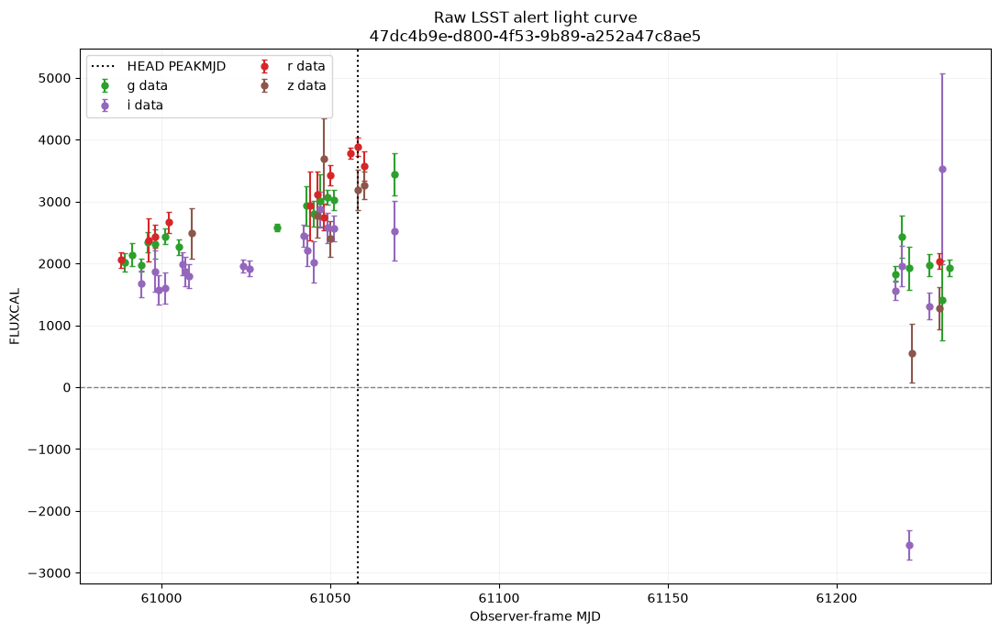

In [181]:
band_colours = {
    "u": "#7B2CBF",
    "g": "#2CA02C",
    "r": "#D62728",
    "i": "#9467BD",
    "z": "#8C564B",
    "y": "#BCBD22",
}

fig, ax = plt.subplots(figsize=(11, 7))

for band in sorted(lsst_lc["BAND"].unique()):
    band_data = lsst_lc[
        lsst_lc["BAND"] == band
    ]

    ax.errorbar(
        band_data["MJD"],
        band_data["FLUXCAL"],
        yerr=band_data["FLUXCALERR"],
        fmt="o",
        ms=5,
        capsize=2,
        color=band_colours.get(band, "black"),
        label=f"{band} data",
    )

ax.axhline(
    0,
    color="0.5",
    linestyle="--",
    linewidth=1,
)

ax.axvline(
    float(head_row["PEAKMJD"]),
    color="black",
    linestyle=":",
    linewidth=1.5,
    label="HEAD PEAKMJD",
)

ax.set_xlabel("Observer-frame MJD")
ax.set_ylabel("FLUXCAL")
ax.set_title(
    f"Raw LSST alert light curve\n{target_snid}"
)
ax.legend(ncol=2)
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

### Fit Foundation object

In [39]:
import numpyro
numpyro.set_host_device_count(4)

import jax
import jax.numpy as jnp
import numpy as np
import sncosmo
from bayesn import SEDmodel
from pathlib import Path
import pandas as pd

from io import BytesIO
import gzip
from astropy.io import fits
from zipfile import ZipFile, BadZipFile

import numpy as np
import matplotlib.pyplot as plt
import sncosmo
from bayesn import SEDmodel

In [45]:
project_root = Path.cwd().parent
lsst_zip = project_root / "data" / "Foundation_DR1.zip"

import numpy as np
import matplotlib.pyplot as plt
import sncosmo
from pathlib import Path
from bayesn import SEDmodel

snid = "ASASSN-15so"

sn_file = (
    project_root
    / "data"
    / "Foundation_DR1_extracted"
    / "Foundation_DR1"
    / f"Foundation_DR1_{snid}.txt"
)

filt_map = {
    "g": "g_PS1",
    "r": "r_PS1",
    "i": "i_PS1",
    "z": "z_PS1",
}

z_quantiles = jnp.linspace(0.001, 0.30, 101)

model = SEDmodel(load_model="T21_model")

samples, sn_props = model.fit_from_file(
    str(sn_file),
    filt_map=filt_map,
    photoz=True,
    z_quantiles=z_quantiles,
    chain_method="parallel",
)


Current devices: [CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3)]
Currently working in /Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks
Loading built-in model T21_model


/Users/jennakempster-taylor/miniforge3/envs/bayesn-lsst/lib/python3.11/site-packages/jax/_src/api_util.py:691: UserWarning: Missing a plate statement for batch dimension -2 at site 'obs'. You can use `numpyro.util.format_shapes` utility to check shapes at all sites of your model.
  ans = _fun(*args, **kwargs)


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]


                     mean       std    median      5.0%     95.0%     n_eff     r_hat
          AV[0]      0.12      0.05      0.12      0.03      0.20    312.85      1.01
          Ds[0]     32.81      0.05     32.81     32.73     32.89    342.44      1.01
 eps_tform[0,0]      0.63      0.57      0.65     -0.30      1.61    670.75      1.01
 eps_tform[0,1]      1.05      0.49      1.06      0.27      1.81    722.90      1.00
 eps_tform[0,2]      1.34      0.50      1.33      0.56      2.27    862.89      1.00
 eps_tform[0,3]     -0.02      0.64     -0.02     -1.06      1.05    772.42      1.00
 eps_tform[0,4]     -1.37      0.61     -1.37     -2.31     -0.39    483.38      1.00
 eps_tform[0,5]     -0.28      0.53     -0.27     -1.14      0.58    750.38      1.00
 eps_tform[0,6]      0.14      0.59      0.13     -0.74      1.21    436.46      1.00
 eps_tform[0,7]     -0.19      0.42     -0.20     -0.97      0.40    380.95      1.01
 eps_tform[0,8]      0.67      0.50      0.69     -0.

In [47]:
# Get flux from chains

meta, tables = sncosmo.read_snana_ascii(
    str(sn_file),
    default_tablename="OBS",
)

lc = tables["OBS"].to_pandas().sort_values("MJD")

plot_samples = dict(samples)
plot_samples.setdefault("mu", plot_samples["Ds"])
plot_samples.setdefault(
    "delM",
    np.zeros_like(plot_samples["Ds"]),
)

model.peak_mjds = np.array([float(meta["SEARCH_PEAKMJD"])])
model.ebv = np.array([float(meta["MWEBV"])])

bands = [["g_PS1", "r_PS1", "i_PS1", "z_PS1"]]

model_mjd, model_flux, model_std = (
    model.get_flux_from_chains_photoz(
        chains=plot_samples,
        bands=bands,
        num_sne=1,
        n_grid=200,
        num_samples=200,
    )
)

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                      | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:15<00:00, 15.73s/it]


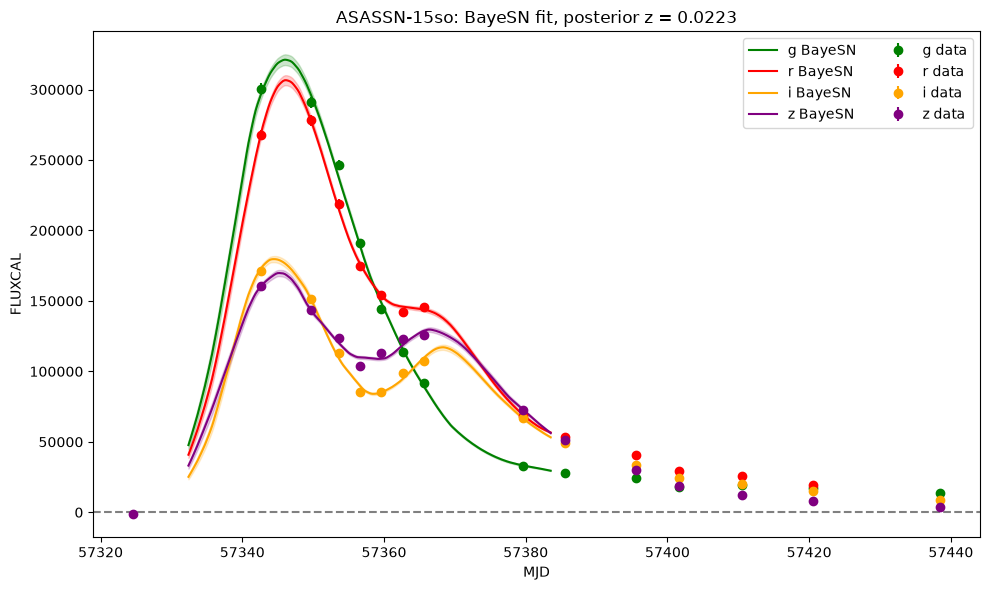

In [48]:
colours = {
    "g": "green",
    "r": "red",
    "i": "orange",
    "z": "purple",
}

fig, ax = plt.subplots(figsize=(10, 6))

for i, band in enumerate(["g", "r", "i", "z"]):
    observed = lc[lc["FLT"].astype(str).str.strip() == band]

    ax.errorbar(
        observed["MJD"],
        observed["FLUXCAL"],
        yerr=observed["FLUXCALERR"],
        fmt="o",
        color=colours[band],
        label=f"{band} data",
    )

    ax.plot(
        model_mjd[0],
        model_flux[0, i],
        color=colours[band],
        label=f"{band} BayeSN",
    )

    ax.fill_between(
        model_mjd[0],
        model_flux[0, i] - model_std[0, i],
        model_flux[0, i] + model_std[0, i],
        color=colours[band],
        alpha=0.2,
    )

z = np.asarray(samples["z"]).reshape(-1)

ax.axhline(0, color="grey", linestyle="--")
ax.set(
    xlabel="MJD",
    ylabel="FLUXCAL",
    title=f"{snid}: BayeSN fit, posterior z = {np.median(z):.4f}",
)
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

### LSST data

In [193]:
target_snid = "19898c3a-46fb-4f17-8d03-ae5b208bd820"
head_row = head_data[
    np.char.strip(head_data["SNID"].astype(str)) == target_snid
][0]

def get_lightcurve(head_row, phot_table):
    start = int(head_row["PTROBS_MIN"]) - 1
    stop = int(head_row["PTROBS_MAX"])

    lc = pd.DataFrame(
        phot_table[start:stop]
    )

    # Convert byte strings such as b"g" into normal strings
    lc["BAND"] = (
        lc["BAND"]
        .str.decode("utf-8")
        .str.strip()
        if lc["BAND"].dtype == object
        else lc["BAND"].astype(str).str.strip()
    )

    return lc
    
target_lc = get_lightcurve(head_row, phot_data)

In [183]:
target_snid = "47dc4b9e-d800-4f53-9b89-a252a47c8ae5"

snids = np.char.strip(
    head_data["SNID"].astype(str)
)

head_row = head_data[snids == target_snid][0]

target_lc = get_lightcurve(
    head_row,
    phot_data,
)

print("Extracted observations:", len(target_lc))
display(
    target_lc[
        ["MJD", "BAND", "FLUXCAL", "FLUXCALERR"]
    ].head()
)

Extracted observations: 61


,MJD,BAND,FLUXCAL,FLUXCALERR
0,60988.1233,r,2054.600098,121.489998
1,60989.2050,g,2012.300049,150.699997
2,60991.2372,g,2142.100098,189.130005
3,60994.0838,g,1973.199951,110.610001
4,60994.1448,i,1670.400024,214.039993


In [184]:
# Keep valid measurements
target_lc = target_lc[
    np.isfinite(target_lc["MJD"])
    & np.isfinite(target_lc["FLUXCAL"])
    & np.isfinite(target_lc["FLUXCALERR"])
    & (target_lc["FLUXCALERR"] > 0)
].copy()

# Remove possible "LSST_" prefix
target_lc["BAND"] = (
    target_lc["BAND"]
    .astype(str)
    .str.strip()
    .str.replace("LSST_", "", regex=False)
)

print(target_lc["BAND"].value_counts())

BAND
i    21
g    20
r    12
z     8
Name: count, dtype: int64


In [185]:
import jax.numpy as jnp
from bayesn import SEDmodel

# Use the highest-SNR observation as an approximate peak
snr = target_lc["FLUXCAL"] / target_lc["FLUXCALERR"]
peak_mjd = float(target_lc.loc[snr.idxmax(), "MJD"])

import numpy as np
import jax.numpy as jnp
from bayesn import SEDmodel

t = np.asarray(target_lc["MJD"], dtype=float)
flux = np.asarray(target_lc["FLUXCAL"], dtype=float)
flux_err = np.asarray(target_lc["FLUXCALERR"], dtype=float)
filters = np.asarray(target_lc["BAND"]).astype(str)

LSST_FILT_MAP = {
    "u": "u_LSST",
    "g": "g_LSST",
    "r": "r_LSST",
    "i": "i_LSST",
    "z": "z_LSST",
    "y": "y_LSST",
}

# Broad uniform redshift prior
zq_broad = jnp.linspace(0.001, 1.0, 101)

model = SEDmodel(load_model="T21_model")

samples, props = model.fit(
    t,
    flux,
    np.clip(flux_err, flux/10, np.inf),
    #flux_err,
    filters,
    ebv_mw=float(head_row["MWEBV"]),
    peak_mjd=float(head_row["PEAKMJD"]),
    filt_map=LSST_FILT_MAP,
    photoz=True,
    z_quantiles=zq_broad,
    chain_method="parallel",
)

Current devices: [CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3)]
Currently working in /Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks
Loading built-in model T21_model


/Users/jennakempster-taylor/miniforge3/envs/bayesn-lsst/lib/python3.11/site-packages/jax/_src/api_util.py:691: UserWarning: Missing a plate statement for batch dimension -2 at site 'obs'. You can use `numpyro.util.format_shapes` utility to check shapes at all sites of your model.
  ans = _fun(*args, **kwargs)


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
z_samples = np.asarray(samples["z"]).reshape(-1)

print("Posterior median z:", np.median(z_samples))
print("68% interval:", np.percentile(z_samples, [16, 84]))


In [ ]:
plot_samples = dict(samples)

if "mu" not in plot_samples:
    plot_samples["mu"] = plot_samples["Ds"]

if "delM" not in plot_samples:
    plot_samples["delM"] = np.zeros_like(plot_samples["Ds"])

# Tell the model about this object's metadata
model.peak_mjds = np.array(
    [float(head_row["PEAKMJD"])]
)

model.ebv = np.array(
    [float(head_row["MWEBV"])]
)

observed_bands = [
    band for band in ["u", "g", "r", "i", "z", "y"]
    if band in np.unique(filters)
]

fit_bands = [[
    LSST_FILT_MAP[band]
    for band in observed_bands
]]

model_mjd, model_mean, model_std = (
    model.get_flux_from_chains_photoz(
        chains=plot_samples,
        bands=fit_bands,
        num_sne=1,
        n_grid=200,
        num_samples=200,
    )
)

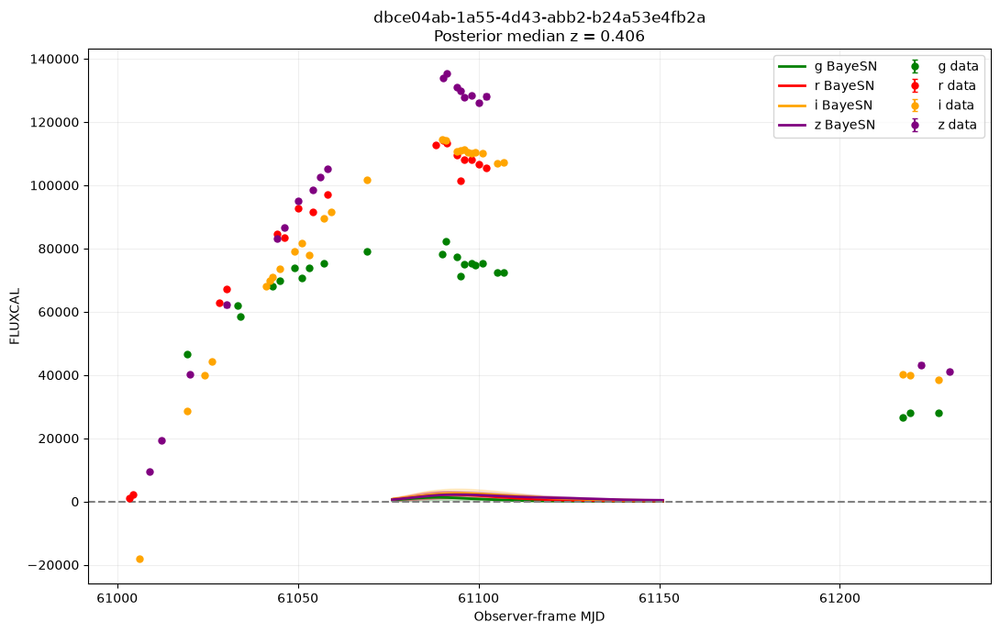

In [58]:
colours = {
    "u": "blue",
    "g": "green",
    "r": "red",
    "i": "orange",
    "z": "purple",
    "y": "brown",
}

fig, ax = plt.subplots(figsize=(11, 7))

for band_index, band in enumerate(observed_bands):
    use = filters == band
    colour = colours[band]

    ax.errorbar(
        t[use],
        flux[use],
        yerr=flux_err[use],
        fmt="o",
        ms=5,
        capsize=2,
        color=colour,
        label=f"{band} data",
        zorder=3,
    )

    fitted_flux = model_mean[0, band_index]
    fitted_std = model_std[0, band_index]

    ax.plot(
        model_mjd[0],
        fitted_flux,
        color=colour,
        linewidth=2,
        label=f"{band} BayeSN",
    )

    ax.fill_between(
        model_mjd[0],
        fitted_flux - fitted_std,
        fitted_flux + fitted_std,
        color=colour,
        alpha=0.18,
    )

z_median = np.median(
    np.asarray(samples["z"]).reshape(-1)
)

ax.axhline(0, color="grey", linestyle="--")
ax.set(
    xlabel="Observer-frame MJD",
    ylabel="FLUXCAL",
    title=f"{target_snid}\nPosterior median z = {z_median:.3f}",
)
ax.legend(ncol=2)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [59]:
print("Observed MJD range:", t.min(), "to", t.max())
print("Model MJD range:", model_mjd[0].min(), "to", model_mjd[0].max())

print("Observed flux range:", flux.min(), "to", flux.max())
print("Model flux range:", model_mean.min(), "to", model_mean.max())

Observed MJD range: 61003.3367 to 61230.4212
Model MJD range: 61076.12022382599 to 61150.987854696046
Observed flux range: -18166.0 to 135290.0
Model flux range: 37.01107388225982 to 2585.8293410218153


In [60]:
for band in observed_bands:
    use = filters == band

    print(f"\n{band}")
    print("N points:", use.sum())
    print("Flux range:", flux[use].min(), flux[use].max())
    print("Median flux:", np.median(flux[use]))
    print("Positive fraction:", np.mean(flux[use] > 0))
    print("SNR > 3:", np.sum(flux[use] / flux_err[use] > 3))


g
N points: 23
Flux range: 26589.0 82421.0
Median flux: 72475.0
Positive fraction: 1.0
SNR > 3: 23

r
N points: 18
Flux range: 1007.5999755859375 114060.0
Median flux: 99146.5
Positive fraction: 1.0
SNR > 3: 18

i
N points: 28
Flux range: -18166.0 114580.0
Median flux: 85579.0
Positive fraction: 0.9642857142857143
SNR > 3: 27

z
N points: 20
Flux range: 9390.7001953125 135290.0
Median flux: 100529.0
Positive fraction: 1.0
SNR > 3: 20


### Debug to work 

In [61]:
LSST_ZP = 31.4
FLUXCAL_ZP = 27.5

conversion = 10 ** (0.4 * (FLUXCAL_ZP - LSST_ZP))

flux_fluxcal = flux * conversion
flux_err_fluxcal = flux_err * conversion

print("Conversion factor:", conversion)
print("Original flux range:", flux.min(), flux.max())
print("FLUXCAL range:", flux_fluxcal.min(), flux_fluxcal.max())

Conversion factor: 0.02754228703338169
Original flux range: -18166.0 135290.0
FLUXCAL range: -500.3331862484118 3726.1960127462085


In [63]:
filters_plot = np.asarray(filters).astype("U").reshape(-1)
plot_bands = [str(b).strip() for b in fit_bands]

print("Filter values:", np.unique(filters_plot))
print("Model band order:", plot_bands)
print("Shapes:", filters_plot.shape, np.asarray(t).shape)

Filter values: ['g' 'i' 'r' 'z']
Model band order: ["['g_LSST', 'r_LSST', 'i_LSST', 'z_LSST']"]
Shapes: (89,) (89,)


In [91]:
target_snid = "8f156832-1cb6-49e8-a3d4-b5bf27fc0ba1" 

snids = np.char.strip(
    head_data["SNID"].astype(str)
)

head_row = head_data[snids == target_snid][0]

target_lc = get_lightcurve(
    head_row,
    phot_data,
)

print("Extracted observations:", len(target_lc))
display(
    target_lc[
        ["MJD", "BAND", "FLUXCAL", "FLUXCALERR"]
    ].head()
)

Extracted observations: 37


,MJD,BAND,FLUXCAL,FLUXCALERR
0,61024.1376,i,68965.0,193.029999
1,61026.1990,i,94453.0,256.950012
2,61034.1530,g,174170.0,218.289993
3,61042.1004,i,103280.0,459.000000
4,61043.0626,g,114860.0,550.849976


In [97]:
print(target_lc.dtypes)

MJD             >f8
BAND            str
DETNUM          >i2
IMGNUM        int32
FIELD           str
PHOTFLAG      int32
PHOTPROB        >f4
FLUXCAL         >f4
FLUXCALERR      >f4
PSF_SIG1        >f4
PSF_SIG2        >f4
PSF_RATIO       >f4
SKY_SIG         >f4
SKY_SIG_T       >f4
RDNOISE         >f4
ZEROPT          >f4
ZEROPT_ERR      >f4
TEXPOSE         >f4
GAIN            >f4
XPIX            >f4
YPIX            >f4
dtype: object


In [117]:

#target_lc = target_lc.astype({"MJD": ">f4"})
float_cols = target_lc.select_dtypes(include="float").columns
target_lc[float_cols] = target_lc[float_cols].astype("float32")
print(target_lc.dtypes)


MJD           float32
BAND              str
DETNUM            >i2
IMGNUM          int32
FIELD             str
PHOTFLAG        int32
PHOTPROB      float32
FLUXCAL       float32
FLUXCALERR    float32
PSF_SIG1      float32
PSF_SIG2      float32
PSF_RATIO     float32
SKY_SIG       float32
SKY_SIG_T     float32
RDNOISE       float32
ZEROPT        float32
ZEROPT_ERR    float32
TEXPOSE       float32
GAIN          float32
XPIX          float32
YPIX          float32
dtype: object


In [121]:
mjd_mask = target_lc["MJD"] < 61100
print(mjd_mask.value_counts())


MJD
True     23
False    14
Name: count, dtype: int64


In [122]:
target_lc["DETNUM"] = target_lc["DETNUM"].astype("int16")

In [123]:
# Keep valid measurements
target_lc = target_lc[
    np.isfinite(target_lc["MJD"])
    & np.isfinite(target_lc["FLUXCAL"])
    & np.isfinite(target_lc["FLUXCALERR"])
    & (target_lc["FLUXCALERR"] > 0)
    & (target_lc["MJD"] < 61100)
].copy()

# Remove possible "LSST_" prefix
target_lc["BAND"] = (
    target_lc["BAND"]
    .astype(str)
    .str.strip()
    .str.replace("LSST_", "", regex=False)
)

print(target_lc["BAND"].value_counts())

BAND
i    6
r    6
z    6
g    5
Name: count, dtype: int64


In [124]:
snr = target_lc["FLUXCAL"] / target_lc["FLUXCALERR"]
peak_mjd = float(target_lc.loc[snr.idxmax(), "MJD"])

import numpy as np
import jax.numpy as jnp
from bayesn import SEDmodel

t = np.asarray(target_lc["MJD"], dtype=float)
flux = np.asarray(target_lc["FLUXCAL"], dtype=float)
flux_err = np.asarray(target_lc["FLUXCALERR"], dtype=float)
filters = np.asarray(target_lc["BAND"]).astype(str)

LSST_FILT_MAP = {
    "u": "u_LSST",
    "g": "g_LSST",
    "r": "r_LSST",
    "i": "i_LSST",
    "z": "z_LSST",
    "y": "y_LSST",
}

# Broad uniform redshift prior
zq_broad = jnp.linspace(0, 1, 101)

model = SEDmodel(load_model="T21_model")

samples, props = model.fit(
    t,
    flux,
    np.clip(flux_err, flux/10, np.inf),
    filters,
    ebv_mw=float(head_row["MWEBV"]),
    peak_mjd=float(head_row["PEAKMJD"]),
    filt_map=LSST_FILT_MAP,
    photoz=True,
    z_quantiles=zq_broad,
    chain_method="parallel",
)

Current devices: [CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3)]
Currently working in /Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks
Loading built-in model T21_model


/Users/jennakempster-taylor/miniforge3/envs/bayesn-lsst/lib/python3.11/site-packages/jax/_src/api_util.py:691: UserWarning: Missing a plate statement for batch dimension -2 at site 'obs'. You can use `numpyro.util.format_shapes` utility to check shapes at all sites of your model.
  ans = _fun(*args, **kwargs)


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]


                     mean       std    median      5.0%     95.0%     n_eff     r_hat
          AV[0]      0.46      0.15      0.46      0.21      0.70    539.13      1.01
          Ds[0]     33.02      0.13     33.01     32.80     33.21    411.40      1.01
 eps_tform[0,0]      0.32      0.96      0.34     -1.24      1.86   1020.91      1.00
 eps_tform[0,1]      0.26      0.93      0.24     -1.13      1.87   1262.78      1.00
 eps_tform[0,2]      0.24      0.96      0.24     -1.32      1.75   1046.34      1.00
 eps_tform[0,3]      0.19      1.00      0.17     -1.33      1.87   1567.67      1.00
 eps_tform[0,4]      0.40      0.96      0.39     -1.09      1.98    886.56      1.00
 eps_tform[0,5]      0.02      1.03     -0.01     -1.61      1.72   1435.81      1.00
 eps_tform[0,6]     -0.06      0.95     -0.08     -1.63      1.40   1023.73      1.00
 eps_tform[0,7]      0.17      0.97      0.17     -1.49      1.74   1384.05      1.00
 eps_tform[0,8]      0.39      0.89      0.42     -1.

In [125]:
z_samples = np.asarray(samples["z"]).reshape(-1)

print("Posterior median z:", np.median(z_samples))
print("68% interval:", np.percentile(z_samples, [16, 84]))


Posterior median z: 0.06013942293430567
68% interval: [0.05260565 0.06697343]


In [126]:
plot_samples = dict(samples)
z_samples = np.asarray(samples["z"]).reshape(-1)

if "mu" not in plot_samples:
    plot_samples["mu"] = plot_samples["Ds"]

if "delM" not in plot_samples:
    plot_samples["delM"] = np.zeros_like(plot_samples["Ds"])

# Tell the model about this object's metadata
model.peak_mjds = np.array(
    [float(head_row["PEAKMJD"])]
)

model.ebv = np.array(
    [float(head_row["MWEBV"])]
)

observed_bands = [
    band for band in ["u", "g", "r", "i", "z", "y"]
    if band in np.unique(filters)
]

fit_bands = [[
    LSST_FILT_MAP[band]
    for band in observed_bands
]]

model_mjd, model_mean, model_std = (
    model.get_flux_from_chains_photoz(
        chains=plot_samples,
        bands=fit_bands,
        num_sne=1,
        n_grid=200,
        num_samples=200,
    )
)

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                      | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.60s/it]


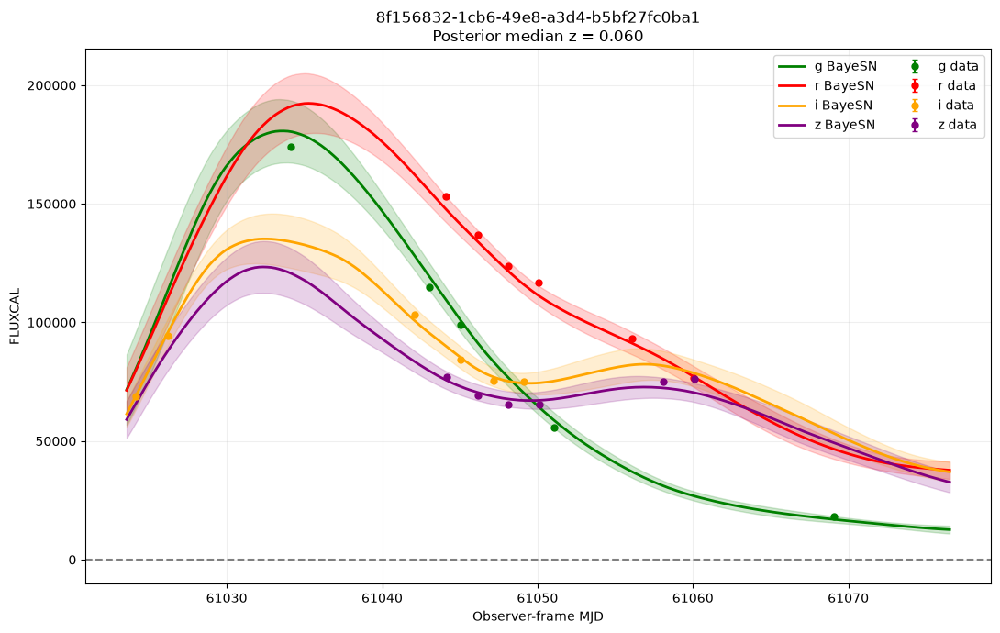


g
N points: 10
Flux range: 1218.199951171875 174170.0
Median flux: 10329.849975585938
Positive fraction: 1.0
SNR > 1000: 0

r
N points: 8
Flux range: 1422.5 153170.0
Median flux: 105028.5
Positive fraction: 1.0
SNR > 1000: 0

i
N points: 11
Flux range: -4350.60009765625 103280.0
Median flux: 68965.0
Positive fraction: 0.5454545454545454
SNR > 1000: 0

z
N points: 8
Flux range: 401.3599853515625 76929.0
Median flux: 67410.5
Positive fraction: 1.0
SNR > 1000: 0


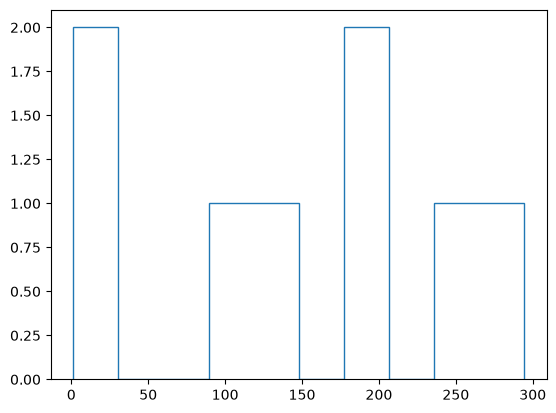

In [77]:
for band in observed_bands:
    use = filters == band

    print(f"\n{band}")
    print("N points:", use.sum())
    print("Flux range:", flux[use].min(), flux[use].max())
    print("Median flux:", np.median(flux[use]))
    print("Positive fraction:", np.mean(flux[use] > 0))
    print("SNR > 1000:", np.sum(flux[use] / flux_err[use] > 1000))


counts, bins = np.histogram(flux[use]/flux_err[use])
plt.stairs(counts, bins)

In [215]:
target_snid = "dbf14a27-ed8f-43d2-9263-de157d67b408"

snids = np.char.strip(
    head_data["SNID"].astype(str)
)

head_row = head_data[snids == target_snid][0]

target_lc = get_lightcurve(
    head_row,
    phot_data,
)

print("Extracted observations:", len(target_lc))
display(
    target_lc[
        ["MJD", "BAND", "FLUXCAL", "FLUXCALERR"]
    ].head()
)

Extracted observations: 22


,MJD,BAND,FLUXCAL,FLUXCALERR
0,61003.3244,g,1503.500000,165.990005
1,61019.2897,g,2637.899902,301.250000
2,61028.3221,r,3503.600098,154.929993
3,61033.2850,g,2463.100098,133.509995
4,61049.1175,g,2674.100098,207.309998


In [216]:
target_snid = "dbf14a27-ed8f-43d2-9263-de157d67b408"
head_row = head_data[
    np.char.strip(head_data["SNID"].astype(str)) == target_snid
][0]

def get_lightcurve(head_row, phot_table):
    start = int(head_row["PTROBS_MIN"]) - 1
    stop = int(head_row["PTROBS_MAX"])

    lc = pd.DataFrame(
        phot_table[start:stop]
    )

    # Convert byte strings such as b"g" into normal strings
    lc["BAND"] = (
        lc["BAND"]
        .str.decode("utf-8")
        .str.strip()
        if lc["BAND"].dtype == object
        else lc["BAND"].astype(str).str.strip()
    )

    return lc
    
target_lc = get_lightcurve(head_row, phot_data)

In [217]:
idx = matches[0]

# All object-level information
head_row = head_data[idx]

# Locate this object's observations in the PHOT table
start = int(head_row["PTROBS_MIN"]) - 1
stop = int(head_row["PTROBS_MAX"])

# Extract all photometric observations for this object
lightcurve = phot_data[start:stop].copy()

print("HEAD row index:", idx)
print("PHOT rows:", start, "to", stop - 1)
print("Number of observations:", len(lightcurve))

HEAD row index: 14921
PHOT rows: 79561 to 79621
Number of observations: 61


In [211]:
valid = (
    np.isfinite(lightcurve_df["MJD"])
    & np.isfinite(lightcurve_df["FLUXCAL"])
    & np.isfinite(lightcurve_df["FLUXCALERR"])
    & (lightcurve_df["FLUXCALERR"] > 0)
)

lsst_lc = (
    lightcurve_df.loc[valid]
    .sort_values("MJD")
    .reset_index(drop=True)
)

print(
    f"Retained {len(lsst_lc)} of "
    f"{len(lightcurve_df)} observations"
)

Retained 61 of 61 observations


In [207]:
float_cols = target_lc.select_dtypes(include="float").columns
target_lc[float_cols] = target_lc[float_cols].astype("float32")
print(target_lc.dtypes)

MJD           float32
BAND              str
DETNUM            >i2
IMGNUM          int32
FIELD             str
PHOTFLAG        int32
PHOTPROB      float32
FLUXCAL       float32
FLUXCALERR    float32
PSF_SIG1      float32
PSF_SIG2      float32
PSF_RATIO     float32
SKY_SIG       float32
SKY_SIG_T     float32
RDNOISE       float32
ZEROPT        float32
ZEROPT_ERR    float32
TEXPOSE       float32
GAIN          float32
XPIX          float32
YPIX          float32
dtype: object


In [208]:
mjd_mask = target_lc["MJD"] < 61100
print(mjd_mask.value_counts())
target_lc["DETNUM"] = target_lc["DETNUM"].astype("int16")
# Keep valid measurements
target_lc = target_lc[
    np.isfinite(target_lc["MJD"])
    & np.isfinite(target_lc["FLUXCAL"])
    & np.isfinite(target_lc["FLUXCALERR"])
    & (target_lc["FLUXCALERR"] > 0)
    & (target_lc["MJD"] < 61100)
].copy()

# Remove possible "LSST_" prefix
target_lc["BAND"] = (
    target_lc["BAND"]
    .astype(str)
    .str.strip()
    .str.replace("LSST_", "", regex=False)
)

print(target_lc["BAND"].value_counts())

MJD
True    22
Name: count, dtype: int64
BAND
g    11
r     6
z     3
i     2
Name: count, dtype: int64


In [209]:
snr = target_lc["FLUXCAL"] / target_lc["FLUXCALERR"]
peak_mjd = float(target_lc.loc[snr.idxmax(), "MJD"])

import numpy as np
import jax.numpy as jnp
from bayesn import SEDmodel

t = np.asarray(target_lc["MJD"], dtype=float)
flux = np.asarray(target_lc["FLUXCAL"], dtype=float)
flux_err = np.asarray(target_lc["FLUXCALERR"], dtype=float)
filters = np.asarray(target_lc["BAND"]).astype(str)

LSST_FILT_MAP = {
    "u": "u_LSST",
    "g": "g_LSST",
    "r": "r_LSST",
    "i": "i_LSST",
    "z": "z_LSST",
    "y": "y_LSST",
}

# Broad uniform redshift prior
zq_broad = jnp.linspace(0, 1, 101)

model = SEDmodel(load_model="T21_model")

samples, props = model.fit(
    t,
    flux,
    np.clip(flux_err, flux/10, np.inf),
    filters,
    ebv_mw=float(head_row["MWEBV"]),
    peak_mjd=float(head_row["PEAKMJD"]),
    filt_map=LSST_FILT_MAP,
    photoz=True,
    z_quantiles=zq_broad,
    chain_method="parallel",
)

Current devices: [CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3)]
Currently working in /Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks
Loading built-in model T21_model


/Users/jennakempster-taylor/miniforge3/envs/bayesn-lsst/lib/python3.11/site-packages/jax/_src/api_util.py:691: UserWarning: Missing a plate statement for batch dimension -2 at site 'obs'. You can use `numpyro.util.format_shapes` utility to check shapes at all sites of your model.
  ans = _fun(*args, **kwargs)


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]


                     mean       std    median      5.0%     95.0%     n_eff     r_hat
          AV[0]      0.05      0.05      0.03      0.00      0.11    541.70      1.00
          Ds[0]     37.96      0.11     37.96     37.77     38.14    728.73      1.00
 eps_tform[0,0]      0.78      0.84      0.74     -0.58      2.16   1264.45      1.00
 eps_tform[0,1]     -0.33      0.96     -0.35     -2.08      1.17   1357.81      1.00
 eps_tform[0,2]      0.08      1.00      0.09     -1.31      1.91   1384.46      1.00
 eps_tform[0,3]     -0.11      1.03     -0.16     -1.68      1.71   2513.44      1.00
 eps_tform[0,4]     -0.31      0.95     -0.33     -1.78      1.37   1654.55      1.00
 eps_tform[0,5]      0.10      1.03      0.10     -1.65      1.65   1847.38      1.00
 eps_tform[0,6]     -0.23      1.00     -0.27     -1.74      1.41   1708.77      1.00
 eps_tform[0,7]     -0.05      0.99     -0.06     -1.62      1.58   1446.51      1.00
 eps_tform[0,8]      0.49      1.04      0.49     -1.

In [212]:
z_samples = np.asarray(samples["z"]).reshape(-1)

plot_samples = dict(samples)

if "mu" not in plot_samples:
    plot_samples["mu"] = plot_samples["Ds"]

if "delM" not in plot_samples:
    plot_samples["delM"] = np.zeros_like(plot_samples["Ds"])

# Tell the model about this object's metadata
model.peak_mjds = np.array(
    [float(head_row["PEAKMJD"])]
)

model.ebv = np.array(
    [float(head_row["MWEBV"])]
)

observed_bands = [
    band for band in ["u", "g", "r", "i", "z", "y"]
    if band in np.unique(filters)
]

fit_bands = [[
    LSST_FILT_MAP[band]
    for band in observed_bands
]]

model_mjd, model_mean, model_std = (
    model.get_flux_from_chains_photoz(
        chains=plot_samples,
        bands=fit_bands,
        num_sne=1,
        n_grid=200,
        num_samples=200,
    )
)

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                    | 0/1 [00:00<?, ?it/s]



100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.78s/it]


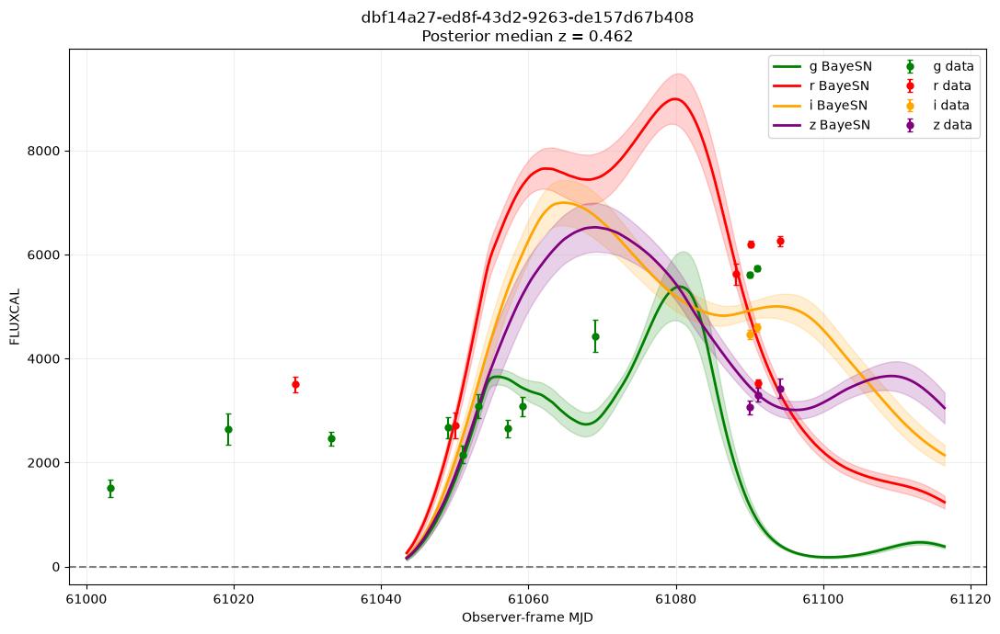

In [213]:
colours = {
    "u": "blue",
    "g": "green",
    "r": "red",
    "i": "orange",
    "z": "purple",
    "y": "brown",
}

fig, ax = plt.subplots(figsize=(11, 7))

for band_index, band in enumerate(observed_bands):
    use = filters == band
    colour = colours[band]

    ax.errorbar(
        t[use],
        flux[use],
        yerr=flux_err[use],
        fmt="o",
        ms=5,
        capsize=2,
        color=colour,
        label=f"{band} data",
        zorder=3,
    )

    fitted_flux = model_mean[0, band_index]
    fitted_std = model_std[0, band_index]

    ax.plot(
        model_mjd[0],
        fitted_flux,
        color=colour,
        linewidth=2,
        label=f"{band} BayeSN",
    )

    ax.fill_between(
        model_mjd[0],
        fitted_flux - fitted_std,
        fitted_flux + fitted_std,
        color=colour,
        alpha=0.18,
    )

z_median = np.median(
    np.asarray(samples["z"]).reshape(-1)
)

ax.axhline(0, color="grey", linestyle="--")
ax.set(
    xlabel="Observer-frame MJD",
    ylabel="FLUXCAL",
    title=f"{target_snid}\nPosterior median z = {z_median:.3f}",
)
ax.legend(ncol=2)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Full cleaned workflow for one object 

In [60]:
# Select SNID

target_snid = "00ff5b2a-1ec5-4450-bdac-b4b92cee2da2"
#"dbf14a27-ed8f-43d2-9263-de157d67b408"

# Find object in HEAD table
snids = np.char.strip(
    head_data["SNID"].astype(str)
)

matches = np.flatnonzero(snids == target_snid)

if len(matches) == 0:
    raise ValueError(f"SNID {target_snid} not found")

head_row = head_data[matches[0]]

# Extract light curve
target_lc = get_lightcurve(
    head_row,
    phot_data,
)

print("Extracted observations:", len(target_lc))

# Convert FITS numerical columns to values
float_cols = target_lc.select_dtypes(
    include="float"
).columns

target_lc[float_cols] = target_lc[
    float_cols
].astype("float32")
target_lc["DETNUM"] = target_lc["DETNUM"].astype("int16")

# Keep valid measurements (apply cut at MJD days here)
target_lc = target_lc[
    np.isfinite(target_lc["MJD"])
    & np.isfinite(target_lc["FLUXCAL"])
    & np.isfinite(target_lc["FLUXCALERR"])
    & (target_lc["FLUXCALERR"] > 0)
    #& (target_lc["MJD"] < 61100)
].copy()

# Remove LSST_ prefix from the bands
target_lc["BAND"] = (
    target_lc["BAND"]
    .astype(str)
    .str.strip()
    .str.replace("LSST_", "", regex=False)
)

target_lc = (
    target_lc
    .sort_values("MJD")
    .reset_index(drop=True)
)

print("Retained observations:", len(target_lc))
print(target_lc["BAND"].value_counts().sort_index())

display(
    target_lc[
        ["MJD", "BAND", "FLUXCAL", "FLUXCALERR"]
    ].head()
)

Extracted observations: 15
Retained observations: 15
BAND
g    3
i    4
r    3
u    1
z    4
Name: count, dtype: int64


,MJD,BAND,FLUXCAL,FLUXCALERR
0,61029.328125,u,1821.800049,353.220001
1,61042.210938,i,-7922.399902,708.640015
2,61088.210938,r,-470.329987,390.679993
3,61088.218750,z,-8382.500000,675.669983
4,61090.195312,i,-2300.899902,130.970001


In [61]:
t = np.asarray(
    target_lc["MJD"],
    dtype=float,
)

flux = np.asarray(
    target_lc["FLUXCAL"],
    dtype=float,
)

flux_err = np.asarray(
    target_lc["FLUXCALERR"],
    dtype=float,
)

filters = np.asarray(
    target_lc["BAND"],
    dtype=str,
)

# Estimate peak MJD from the highest-SNR observation
snr = flux / flux_err
#peak_mjd = float(t[np.argmax(snr)])

print("MJD range:", t.min(), "to", t.max())
#print("Estimated peak MJD:", peak_mjd)
print("Observed bands:", np.unique(filters))

MJD range: 61029.328125 to 61094.15625
Observed bands: ['g' 'i' 'r' 'u' 'z']


In [62]:
snr = target_lc["FLUXCAL"] / target_lc["FLUXCALERR"]
#peak_mjd = float(target_lc.loc[snr.idxmax(), "MJD"])
peak_mjd = float(head_row["PEAKMJD"])

target_lc = target_lc[
    target_lc["MJD"].between(
        peak_mjd - 20,
        peak_mjd + 200,
    )
].copy()

t = np.asarray(target_lc["MJD"], dtype=float)
flux = np.asarray(target_lc["FLUXCAL"], dtype=float)
flux_err = np.asarray(target_lc["FLUXCALERR"], dtype=float)
filters = np.asarray(target_lc["BAND"], dtype=str)

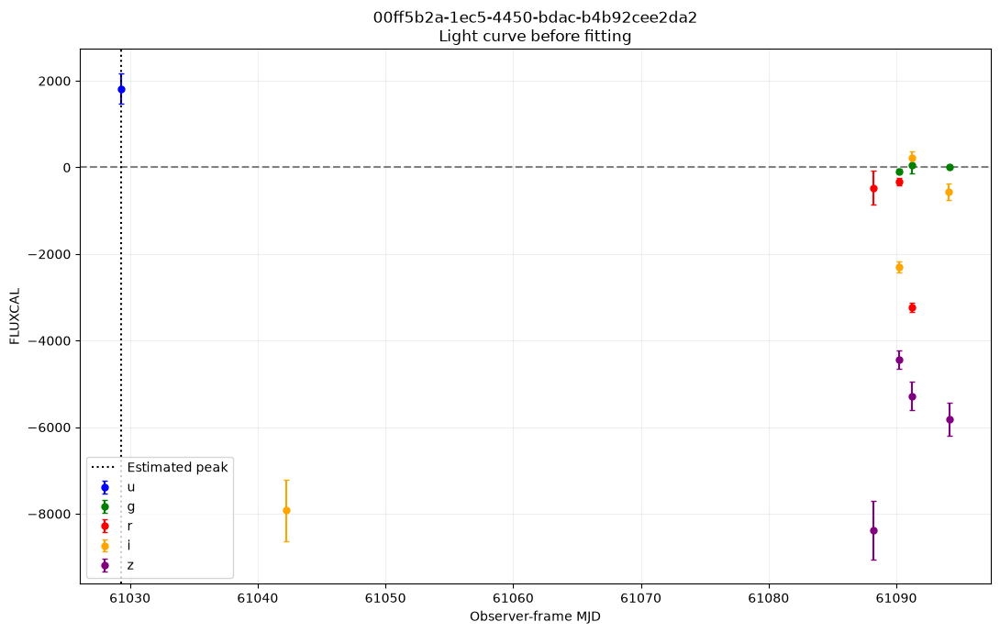

In [63]:
import matplotlib.pyplot as plt
#plot

colours = {
    "u": "blue",
    "g": "green",
    "r": "red",
    "i": "orange",
    "z": "purple",
    "y": "brown",
}

observed_bands = [
    band
    for band in ["u", "g", "r", "i", "z", "y"]
    if band in np.unique(filters)
]

fig, ax = plt.subplots(figsize=(11, 7))

for band in observed_bands:
    use = filters == band

    ax.errorbar(
        t[use],
        flux[use],
        yerr=flux_err[use],
        fmt="o",
        ms=5,
        capsize=2,
        color=colours[band],
        label=band,
    )

ax.axhline(
    0,
    color="grey",
    linestyle="--",
)

ax.axvline(
    peak_mjd,
    color="black",
    linestyle=":",
    label="Estimated peak",
)

ax.set(
    xlabel="Observer-frame MJD",
    ylabel="FLUXCAL",
    title=f"{target_snid}\nLight curve before fitting",
)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [318]:
import jax.numpy as jnp
from bayesn import SEDmodel

LSST_FILT_MAP = {
    "u": "u_LSST",
    "g": "g_LSST",
    "r": "r_LSST",
    "i": "i_LSST",
    "z": "z_LSST",
    "y": "y_LSST",
}

# Broad uniform redshift prior
zq_broad = jnp.linspace(0, 1, 101)

model = SEDmodel(
    load_model="T21_model"
)

samples, props = model.fit(
    t,
    flux,
    np.clip(
        flux_err,
        flux / 10,
        np.inf,
    ),
    filters,
    ebv_mw=float(head_row["MWEBV"]),
    peak_mjd=peak_mjd,
    filt_map=LSST_FILT_MAP,
    photoz=True,
    z_quantiles=zq_broad,
    chain_method="parallel",
)

z_samples = np.asarray(
    samples["z"]
).reshape(-1)

print(
    "Posterior median z:",
    np.median(z_samples),
)

Current devices: [CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3)]
Currently working in /Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks
Loading built-in model T21_model


/Users/jennakempster-taylor/miniforge3/envs/bayesn-lsst/lib/python3.11/site-packages/jax/_src/api_util.py:691: UserWarning: Missing a plate statement for batch dimension -2 at site 'obs'. You can use `numpyro.util.format_shapes` utility to check shapes at all sites of your model.
  ans = _fun(*args, **kwargs)


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]


                     mean       std    median      5.0%     95.0%     n_eff     r_hat
          AV[0]      0.16      0.10      0.16      0.00      0.31    446.63      1.00
          Ds[0]     37.86      0.15     37.86     37.62     38.10    449.35      1.00
 eps_tform[0,0]     -0.23      0.95     -0.18     -1.68      1.33    785.03      1.00
 eps_tform[0,1]     -0.51      0.89     -0.48     -2.03      0.85   1229.19      1.00
 eps_tform[0,2]     -0.14      1.00     -0.13     -1.91      1.41   1429.40      1.00
 eps_tform[0,3]     -0.26      1.00     -0.21     -1.76      1.51   1414.92      1.00
 eps_tform[0,4]     -0.94      0.91     -0.93     -2.42      0.67   1109.70      1.00
 eps_tform[0,5]      0.01      0.93      0.01     -1.56      1.49   1751.76      1.00
 eps_tform[0,6]     -0.20      0.93     -0.22     -1.67      1.33   1392.22      1.00
 eps_tform[0,7]     -0.08      0.94     -0.08     -1.69      1.37   1021.03      1.00
 eps_tform[0,8]     -0.24      0.92     -0.21     -1.

In [319]:
plot_samples = dict(samples)

if "mu" not in plot_samples:
    plot_samples["mu"] = plot_samples["Ds"]

if "delM" not in plot_samples:
    plot_samples["delM"] = np.zeros_like(
        plot_samples["Ds"]
    )

# Give BayeSN object's metadata
model.peak_mjds = np.array([peak_mjd])

model.ebv = np.array([
    float(head_row["MWEBV"])
])

fit_bands = [[
    LSST_FILT_MAP[band]
    for band in observed_bands
]]

model_mjd, model_mean, model_std = (
    model.get_flux_from_chains_photoz(
        chains=plot_samples,
        bands=fit_bands,
        num_sne=1,
        n_grid=200,
        num_samples=200,
    )
)

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                    | 0/1 [00:00<?, ?it/s]



100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:12<00:00, 12.11s/it]


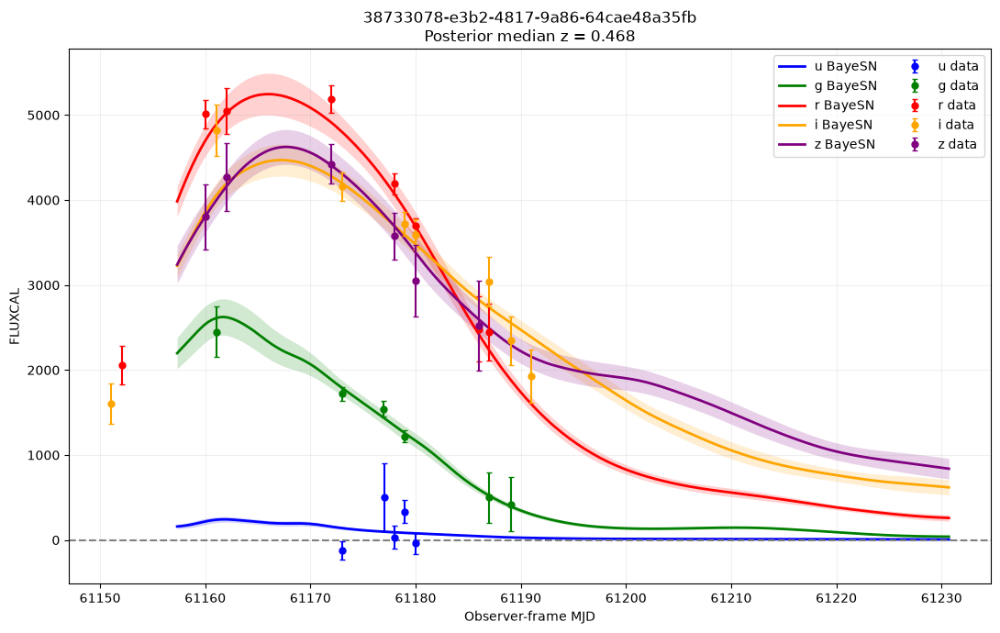

In [320]:
fig, ax = plt.subplots(figsize=(11, 7))

for band_index, band in enumerate(observed_bands):
    use = filters == band
    colour = colours[band]

    # Observed data
    ax.errorbar(
        t[use],
        flux[use],
        yerr=flux_err[use],
        fmt="o",
        ms=5,
        capsize=2,
        color=colour,
        label=f"{band} data",
        zorder=3,
    )

    # BayeSN prediction
    fitted_flux = model_mean[0, band_index]
    fitted_std = model_std[0, band_index]

    ax.plot(
        model_mjd[0],
        fitted_flux,
        color=colour,
        linewidth=2,
        label=f"{band} BayeSN",
        zorder=2,
    )

    ax.fill_between(
        model_mjd[0],
        fitted_flux - fitted_std,
        fitted_flux + fitted_std,
        color=colour,
        alpha=0.18,
        linewidth=0,
        zorder=1,
    )

z_median = np.median(z_samples)

ax.axhline(
    0,
    color="grey",
    linestyle="--",
)

ax.set(
    xlabel="Observer-frame MJD",
    ylabel="FLUXCAL",
    title=(
        f"{target_snid}\n"
        f"Posterior median z = {z_median:.3f}"
    ),
)

ax.legend(ncol=2)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [ ]:
# small flux cal measurements?????
# real or fake 


In [358]:
target_snid = "666ed310-b587-4689-8873-48cae7cb2673"
#"dbf14a27-ed8f-43d2-9263-de157d67b408"

# Find object in HEAD table
snids = np.char.strip(
    head_data["SNID"].astype(str)
)

matches = np.flatnonzero(snids == target_snid)

if len(matches) == 0:
    raise ValueError(f"SNID {target_snid} not found")

head_row = head_data[matches[0]]

# Extract light curve
target_lc = get_lightcurve(
    head_row,
    phot_data,
)

print("Extracted observations:", len(target_lc))

# Convert FITS numerical columns to values
float_cols = target_lc.select_dtypes(
    include="float"
).columns

target_lc[float_cols] = target_lc[
    float_cols
].astype("float32")
target_lc["DETNUM"] = target_lc["DETNUM"].astype("int16")

# Keep valid measurements (apply cut at MJD days here)
target_lc = target_lc[
    np.isfinite(target_lc["MJD"])
    & np.isfinite(target_lc["FLUXCAL"])
    & np.isfinite(target_lc["FLUXCALERR"])
    & (target_lc["FLUXCALERR"] > 0)
    #& (target_lc["MJD"] < 61100)
].copy()

# Remove LSST_ prefix from the bands
target_lc["BAND"] = (
    target_lc["BAND"]
    .astype(str)
    .str.strip()
    .str.replace("LSST_", "", regex=False)
)

target_lc = (
    target_lc
    .sort_values("MJD")
    .reset_index(drop=True)
)

print("Retained observations:", len(target_lc))
print(target_lc["BAND"].value_counts().sort_index())

display(
    target_lc[
        ["MJD", "BAND", "FLUXCAL", "FLUXCALERR"]
    ].head()
)

Extracted observations: 281
Retained observations: 281
BAND
g    71
i    65
r    68
u     9
y     6
z    62
Name: count, dtype: int64


,MJD,BAND,FLUXCAL,FLUXCALERR
0,61090.179688,i,-8983.700195,1075.099976
1,61090.179688,i,-4489.500000,1080.500000
2,61090.183594,i,-19601.000000,1090.500000
3,61090.183594,i,25.153000,1080.900024
4,61090.183594,i,441.320007,1124.000000


In [359]:
t = np.asarray(
    target_lc["MJD"],
    dtype=float,
)

flux = np.asarray(
    target_lc["FLUXCAL"],
    dtype=float,
)

flux_err = np.asarray(
    target_lc["FLUXCALERR"],
    dtype=float,
)

filters = np.asarray(
    target_lc["BAND"],
    dtype=str,
)

# Estimate peak MJD from the highest-SNR observation
snr = flux / flux_err
#peak_mjd = float(t[np.argmax(snr)])

print("MJD range:", t.min(), "to", t.max())
#print("Estimated peak MJD:", peak_mjd)
print("Observed bands:", np.unique(filters))

MJD range: 61090.1796875 to 61204.0234375
Observed bands: ['g' 'i' 'r' 'u' 'y' 'z']


In [360]:
snr = target_lc["FLUXCAL"] / target_lc["FLUXCALERR"]
#peak_mjd = float(target_lc.loc[snr.idxmax(), "MJD"])
peak_mjd = float(head_row["PEAKMJD"])

target_lc = target_lc[
    target_lc["MJD"].between(
        peak_mjd - 70,
        peak_mjd + 40,
    )
].copy()
peak_mjd = float(head_row["PEAKMJD"])
snr = target_lc["FLUXCAL"] / target_lc["FLUXCALERR"]

target_lc = target_lc[
    target_lc["MJD"].between(peak_mjd - 30, peak_mjd + 50)
    & (snr > -5)
].copy()

t = np.asarray(target_lc["MJD"], dtype=float)
flux = np.asarray(target_lc["FLUXCAL"], dtype=float)
flux_err = np.asarray(target_lc["FLUXCALERR"], dtype=float)
filters = np.asarray(target_lc["BAND"], dtype=str)

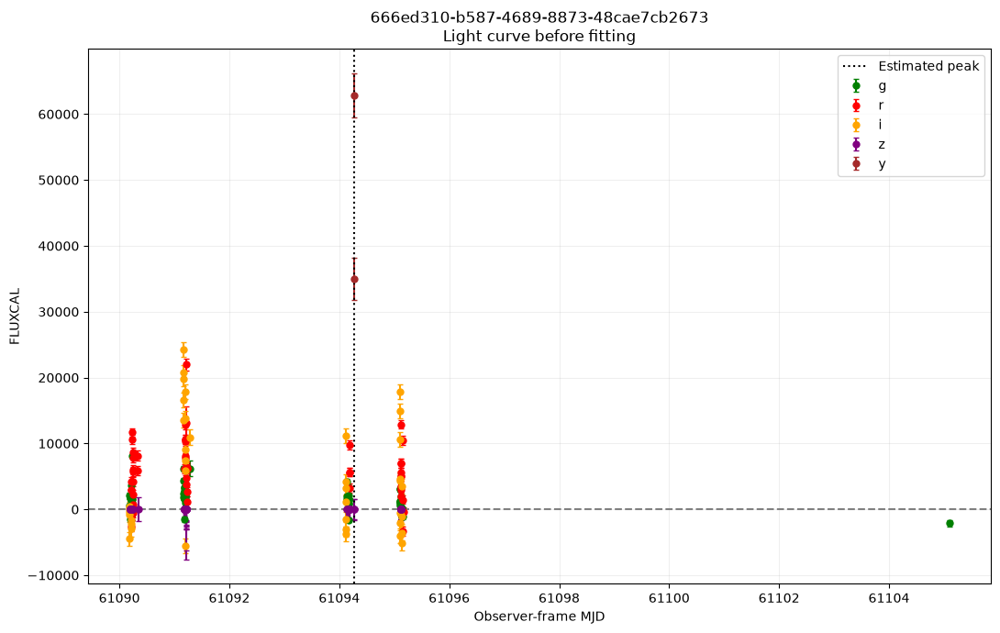

In [361]:
import matplotlib.pyplot as plt
#plot

colours = {
    "u": "blue",
    "g": "green",
    "r": "red",
    "i": "orange",
    "z": "purple",
    "y": "brown",
}

observed_bands = [
    band
    for band in ["u", "g", "r", "i", "z", "y"]
    if band in np.unique(filters)
]

fig, ax = plt.subplots(figsize=(11, 7))

for band in observed_bands:
    use = filters == band

    ax.errorbar(
        t[use],
        flux[use],
        yerr=flux_err[use],
        fmt="o",
        ms=5,
        capsize=2,
        color=colours[band],
        label=band,
    )

ax.axhline(
    0,
    color="grey",
    linestyle="--",
)

ax.axvline(
    peak_mjd,
    color="black",
    linestyle=":",
    label="Estimated peak",
)

ax.set(
    xlabel="Observer-frame MJD",
    ylabel="FLUXCAL",
    title=f"{target_snid}\nLight curve before fitting",
)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [353]:
import jax.numpy as jnp
from bayesn import SEDmodel

LSST_FILT_MAP = {
    "u": "u_LSST",
    "g": "g_LSST",
    "r": "r_LSST",
    "i": "i_LSST",
    "z": "z_LSST",
    "y": "y_LSST",
}

# Broad uniform redshift prior
zq_broad = jnp.linspace(0, 1, 101)

model = SEDmodel(
    load_model="T21_model"
)

samples, props = model.fit(
    t,
    flux,
    np.clip(
        flux_err,
        flux / 10,
        np.inf,
    ),
    filters,
    ebv_mw=float(head_row["MWEBV"]),
    peak_mjd=peak_mjd,
    filt_map=LSST_FILT_MAP,
    photoz=True,
    z_quantiles=zq_broad,
    chain_method="parallel",
)

z_samples = np.asarray(
    samples["z"]
).reshape(-1)

print(
    "Posterior median z:",
    np.median(z_samples),
)

Current devices: [CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3)]
Currently working in /Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks
Loading built-in model T21_model


/Users/jennakempster-taylor/miniforge3/envs/bayesn-lsst/lib/python3.11/site-packages/jax/_src/api_util.py:691: UserWarning: Missing a plate statement for batch dimension -2 at site 'obs'. You can use `numpyro.util.format_shapes` utility to check shapes at all sites of your model.
  ans = _fun(*args, **kwargs)


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]


                     mean       std    median      5.0%     95.0%     n_eff     r_hat
          AV[0]      0.73      0.35      0.89      0.10      1.06      2.08      5.07
          Ds[0]     36.46      0.27     36.33     36.20     36.96      2.12      4.16
 eps_tform[0,0]     -1.90      1.37     -1.65     -4.30     -0.00      2.88      1.75
 eps_tform[0,1]     -0.48      1.20     -0.59     -2.28      1.55      3.46      1.49
 eps_tform[0,2]     -1.78      1.69     -1.32     -4.90      0.31      2.57      2.04
 eps_tform[0,3]      1.83      1.04      1.78      0.21      3.52     23.29      1.06
 eps_tform[0,4]      2.57      1.94      1.93      0.37      6.24      2.34      2.50
 eps_tform[0,5]      3.52      1.00      3.47      1.84      5.14      6.25      1.20
 eps_tform[0,6]     -0.73      1.19     -0.55     -2.64      1.14      3.42      1.52
 eps_tform[0,7]     -2.39      1.67     -2.82     -4.71      0.52      2.58      2.02
 eps_tform[0,8]      1.00      0.94      0.99     -0.

In [354]:
plot_samples = dict(samples)

if "mu" not in plot_samples:
    plot_samples["mu"] = plot_samples["Ds"]

if "delM" not in plot_samples:
    plot_samples["delM"] = np.zeros_like(
        plot_samples["Ds"]
    )

# Give BayeSN object's metadata
model.peak_mjds = np.array([peak_mjd])

model.ebv = np.array([
    float(head_row["MWEBV"])
])

fit_bands = [[
    LSST_FILT_MAP[band]
    for band in observed_bands
]]

model_mjd, model_mean, model_std = (
    model.get_flux_from_chains_photoz(
        chains=plot_samples,
        bands=fit_bands,
        num_sne=1,
        n_grid=200,
        num_samples=200,
    )
)

Getting photo-z posterior-predictive light curves from chains...






  0%|                                                                                                                      | 0/1 [00:00<?, ?it/s]



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:14<00:00, 14.94s/it]


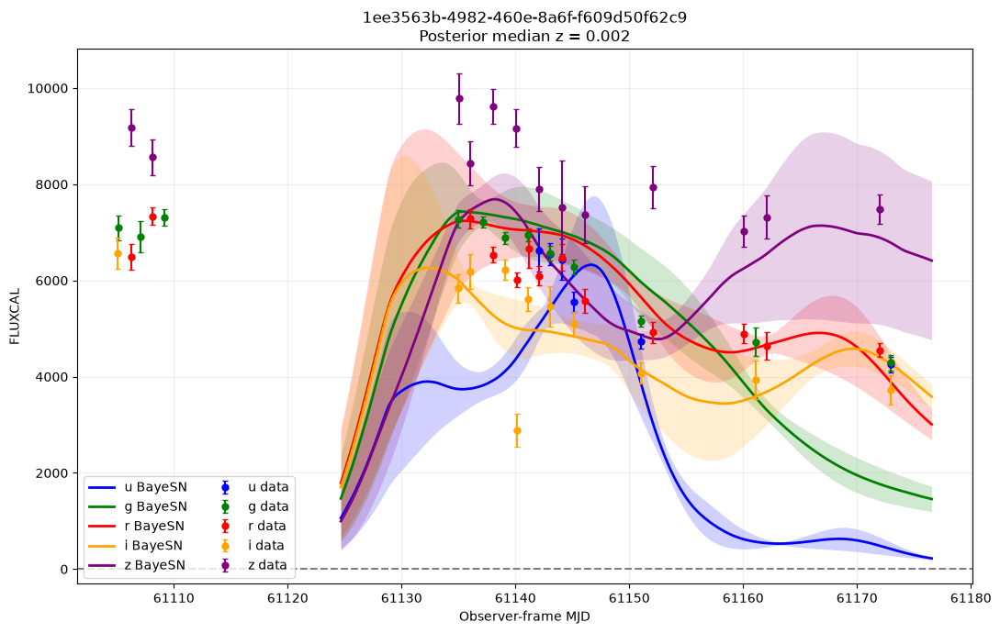

In [355]:
fig, ax = plt.subplots(figsize=(11, 7))

for band_index, band in enumerate(observed_bands):
    use = filters == band
    colour = colours[band]

    # Observed data
    ax.errorbar(
        t[use],
        flux[use],
        yerr=flux_err[use],
        fmt="o",
        ms=5,
        capsize=2,
        color=colour,
        label=f"{band} data",
        zorder=3,
    )

    # BayeSN prediction
    fitted_flux = model_mean[0, band_index]
    fitted_std = model_std[0, band_index]

    ax.plot(
        model_mjd[0],
        fitted_flux,
        color=colour,
        linewidth=2,
        label=f"{band} BayeSN",
        zorder=2,
    )

    ax.fill_between(
        model_mjd[0],
        fitted_flux - fitted_std,
        fitted_flux + fitted_std,
        color=colour,
        alpha=0.18,
        linewidth=0,
        zorder=1,
    )

z_median = np.median(z_samples)

ax.axhline(
    0,
    color="grey",
    linestyle="--",
)

ax.set(
    xlabel="Observer-frame MJD",
    ylabel="FLUXCAL",
    title=(
        f"{target_snid}\n"
        f"Posterior median z = {z_median:.3f}"
    ),
)

ax.legend(ncol=2)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### New cut on nights and time span

In [328]:
matched = pd.read_csv(
    "alerce_match_partial.csv"
)

print(matched.columns.tolist())
display(matched.head())

['SNID', 'oid', 'sep_arcsec', 'p_SN', 'classifier_version']


,SNID,oid,sep_arcsec,p_SN,classifier_version
0,a3f7ac57-349f-44a8-bc11-dd101444ace1,3.138535e+17,0.004703,0.002284,202.0
1,14c2643a-48e6-4bae-a2e0-20b41cdbefaf,3.138535e+17,0.005537,0.001532,202.0
2,1ee3563b-4982-460e-8a6f-f609d50f62c9,3.138710e+17,0.007144,0.019884,202.0
3,23af3b06-9c88-44d8-a6c2-39a062326bbf,3.138535e+17,0.006170,0.003808,202.0
4,28ea9e0f-cd86-4b7e-becb-9970dd7a006c,3.138754e+17,0.019361,0.020532,202.0


In [331]:
results = []

for target_snid in matched["SNID"].astype(str).unique():

    # Find this SNID in HEAD
    snids = np.char.strip(
        head_data["SNID"].astype(str)
    )

    matches = np.flatnonzero(
        snids == target_snid
    )

    if len(matches) == 0:
        results.append({
            "SNID": target_snid,
            "survives": False,
            "reason": "not found in HEAD",
        })
        continue

    head_row = head_data[matches[0]]

    # Extract a fresh light curve
    lc = get_lightcurve(
        head_row,
        phot_data,
    )

    # Fix FITS byte ordering
    float_cols = lc.select_dtypes(
        include="float"
    ).columns

    lc[float_cols] = lc[
        float_cols
    ].astype("float32")
    lc["DETNUM"] = lc["DETNUM"].astype("int16")

    # Basic measurement cuts
    lc = lc[
        np.isfinite(lc["MJD"])
        & np.isfinite(lc["FLUXCAL"])
        & np.isfinite(lc["FLUXCALERR"])
        & (lc["FLUXCALERR"] > 0)
    ].copy()

    if len(lc) == 0:
        results.append({
            "SNID": target_snid,
            "survives": False,
            "reason": "no valid measurements",
        })
        continue

    # Remove extreme negative-flux outliers
    snr = lc["FLUXCAL"] / lc["FLUXCALERR"]

    lc = lc[
        snr > -5
    ].copy()

    if len(lc) == 0:
        results.append({
            "SNID": target_snid,
            "survives": False,
            "reason": "no data after point cuts",
        })
        continue

    # Sampling metrics after all point cuts
    n_observations = len(lc)
    n_nights = lc["MJD"].astype(int).nunique()
    time_span = lc["MJD"].max() - lc["MJD"].min()
    n_bands = lc["BAND"].nunique()

    # Object-level selection
    survives = (
        (n_nights >= 8)
        & (time_span >= 20)
    )

    reason = (
        "passes"
        if survives
        else "insufficient nights or time span"
    )

    results.append({
        "SNID": target_snid,
        "survives": survives,
        "reason": reason,
        "n_observations": n_observations,
        "n_nights": n_nights,
        "time_span": time_span,
        "n_bands": n_bands,
    })

In [332]:
cut_summary = pd.DataFrame(results)

print("Objects checked:", len(cut_summary))
print("Objects surviving:", cut_summary["survives"].sum())

display(
    cut_summary.sort_values(
        ["survives", "n_nights"],
        ascending=[False, False],
    )
)

Objects checked: 2277
Objects surviving: 681


,SNID,survives,reason,n_observations,n_nights,time_span,n_bands
0,a3f7ac57-349f-44a8-bc11-dd101444ace1,True,passes,147.0,66.0,180.679688,6.0
1,14c2643a-48e6-4bae-a2e0-20b41cdbefaf,True,passes,156.0,64.0,180.675781,6.0
3,23af3b06-9c88-44d8-a6c2-39a062326bbf,True,passes,147.0,63.0,180.699219,6.0
2,1ee3563b-4982-460e-8a6f-f609d50f62c9,True,passes,140.0,61.0,176.652344,6.0
4,28ea9e0f-cd86-4b7e-becb-9970dd7a006c,True,passes,139.0,59.0,175.652344,6.0
...,...,...,...,...,...,...,...
2250,424f9ec4-2ebb-4677-97d1-295930e0a22e,False,no data after point cuts,NaN,NaN,NaN,NaN
2251,23e60de3-5a34-443b-89c3-5f22fe7b95dc,False,no data after point cuts,NaN,NaN,NaN,NaN
2258,5c1843b3-c36c-4e33-b904-0330356760a3,False,no data after point cuts,NaN,NaN,NaN,NaN
2263,8a5174f0-c4b9-440e-97ed-7e63ed673d1e,False,no data after point cuts,NaN,NaN,NaN,NaN


In [333]:
surviving_objects = cut_summary[
    cut_summary["survives"]
].copy()

display(surviving_objects)

,SNID,survives,reason,n_observations,n_nights,time_span,n_bands
0,a3f7ac57-349f-44a8-bc11-dd101444ace1,True,passes,147.0,66.0,180.679688,6.0
1,14c2643a-48e6-4bae-a2e0-20b41cdbefaf,True,passes,156.0,64.0,180.675781,6.0
2,1ee3563b-4982-460e-8a6f-f609d50f62c9,True,passes,140.0,61.0,176.652344,6.0
3,23af3b06-9c88-44d8-a6c2-39a062326bbf,True,passes,147.0,63.0,180.699219,6.0
4,28ea9e0f-cd86-4b7e-becb-9970dd7a006c,True,passes,139.0,59.0,175.652344,6.0
...,...,...,...,...,...,...,...
1153,52252300-a09e-4a4c-adef-38632581b562,True,passes,10.0,8.0,131.695312,2.0
1154,00429afb-c43d-4215-b106-dd87b673c8b8,True,passes,8.0,8.0,131.656250,1.0
1156,94799a88-ea9a-4d00-9ab7-173c9050af5b,True,passes,9.0,8.0,114.785156,2.0
1158,476a6c12-99d4-4993-aa88-1663d71bb814,True,passes,8.0,8.0,127.339844,2.0


In [335]:
surviving_objects.to_csv(
    "alerce_match_surviving.csv",
    index=False,
)

In [363]:
snid = "38733078-e3b2-4817-9a86-64cae48a35fb"
print(head_data["RA"])

[282.909373 252.565374 307.694958 ... 282.266842 305.102062 341.45424 ]


### Cut to flat cont readings  // guassian best fit?

In [ ]:
import numpy as np
from scipy.optimize import curve_fit


def gaussian_model(t, baseline, amplitude, peak_mjd, width):
    return baseline + amplitude * np.exp(
        -0.5 * ((t - peak_mjd) / width) ** 2
    )


def gaussian_profile_metrics(lc, min_points=6):
    """
    Test whether a light curve is better described by a broad Gaussian
    transient than by a constant flux.

    Returns lenient profile-selection metrics.
    """

    use = (
        np.isfinite(lc["MJD"])
        & np.isfinite(lc["FLUXCAL"])
        & np.isfinite(lc["FLUXCALERR"])
        & (lc["FLUXCALERR"] > 0)
    )

    clean = lc.loc[use].copy()

    if len(clean) < min_points:
        return {
            "gaussian_fit_ok": False,
            "has_profile": False,
            "reason": "too few points",
        }

    t = clean["MJD"].to_numpy(dtype=float)
    flux = clean["FLUXCAL"].to_numpy(dtype=float)
    flux_err = clean["FLUXCALERR"].to_numpy(dtype=float)

    # Sort by time
    order = np.argsort(t)
    t = t[order]
    flux = flux[order]
    flux_err = flux_err[order]

    time_span = np.ptp(t)

    if time_span == 0:
        return {
            "gaussian_fit_ok": False,
            "has_profile": False,
            "reason": "zero time span",
        }

    # Best-fitting constant model: uncertainty-weighted mean
    weights = 1.0 / flux_err**2
    flat_flux = np.average(flux, weights=weights)

    chi2_flat = np.sum(
        ((flux - flat_flux) / flux_err) ** 2
    )

    # Starting estimates for Gaussian fit
    baseline_guess = np.percentile(flux, 20)
    peak_index = np.argmax(flux)

    amplitude_guess = max(
        flux[peak_index] - baseline_guess,
        np.median(flux_err),
    )

    peak_guess = t[peak_index]
    width_guess = max(time_span / 6, 2.0)

    try:
        parameters, covariance = curve_fit(
            gaussian_model,
            t,
            flux,
            sigma=flux_err,
            absolute_sigma=True,
            p0=[
                baseline_guess,
                amplitude_guess,
                peak_guess,
                width_guess,
            ],
            bounds=(
                [
                    -np.inf,       # baseline
                    0.0,           # positive amplitude
                    t.min(),       # peak inside observations
                    1.0,           # minimum width in days
                ],
                [
                    np.inf,
                    np.inf,
                    t.max(),
                    max(time_span * 2, 2.0),
                ],
            ),
            maxfev=20_000,
        )

        baseline, amplitude, peak_mjd, width = parameters

        model_flux = gaussian_model(t, *parameters)

        chi2_gaussian = np.sum(
            ((flux - model_flux) / flux_err) ** 2
        )

        delta_chi2 = chi2_flat - chi2_gaussian

        amplitude_error = np.sqrt(covariance[1, 1])

        if np.isfinite(amplitude_error) and amplitude_error > 0:
            amplitude_snr = amplitude / amplitude_error
        else:
            amplitude_snr = np.nan

        # Lenient cut: Gaussian merely needs to be noticeably better
        has_profile = (
            (delta_chi2 > 6)
            and (amplitude_snr > 2)
            and (width < time_span * 1.5)
        )

        return {
            "gaussian_fit_ok": True,
            "has_profile": has_profile,
            "chi2_flat": chi2_flat,
            "chi2_gaussian": chi2_gaussian,
            "delta_chi2": delta_chi2,
            "baseline": baseline,
            "amplitude": amplitude,
            "amplitude_snr": amplitude_snr,
            "peak_mjd": peak_mjd,
            "gaussian_width": width,
            "reason": (
                "Gaussian improvement"
                if has_profile
                else "mostly flat or weak profile"
            ),
        }

    except (RuntimeError, ValueError):
        return {
            "gaussian_fit_ok": False,
            "has_profile": False,
            "reason": "Gaussian fit failed",
        }